<a href="https://colab.research.google.com/github/belvinos91/pythonProject/blob/master/PQ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

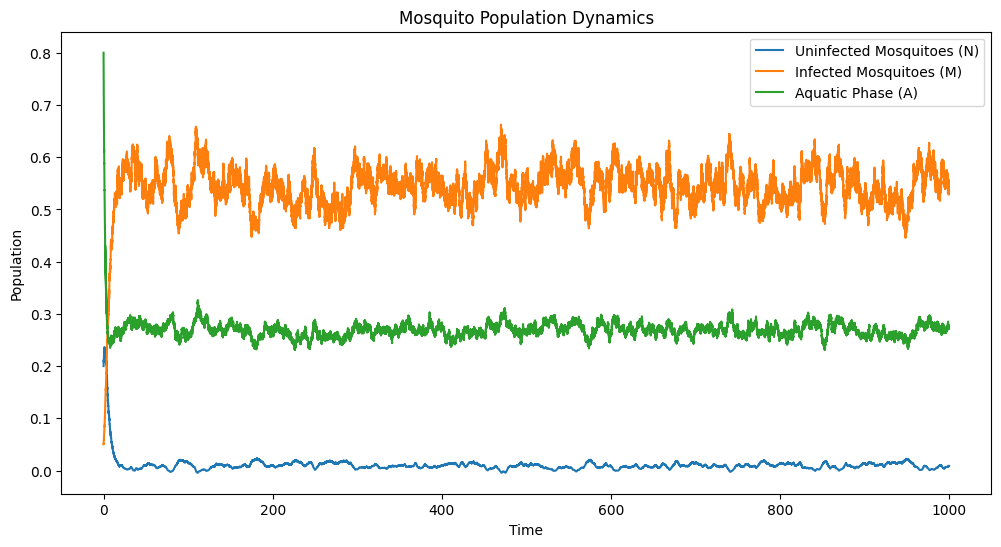

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters (example values)
gamma_N, gamma_M, e, p1, p2, beta = 0.35, 0.34, 0.1, 0.2, 0.7, 0.6
lambda_N, lambda_M, tau, alpha, gamma = 0.21, 0.22, 0.25, 0.1, 0.3
sigma_N, sigma_M, sigma_A = 0.05, 0.04, 0.03
K1, K2 = 0.6, 1.2

# Time setup
T = 1000  # Total time
dt = 0.01  # Time step
n_steps = int(T / dt)

# Initial conditions
N, M, A = np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps)
N[0], M[0], A[0] = 0.2, 0.05, 0.8  # Initial populations

# Brownian increments
dB1 = np.sqrt(dt) * np.random.randn(n_steps)
dB2 = np.sqrt(dt) * np.random.randn(n_steps)
dB3 = np.sqrt(dt) * np.random.randn(n_steps)

# Simulation loop
for t in range(n_steps - 1):
    f_N = gamma_N * N[t] * (1 - (N[t] + M[t]) / K1) + e * M[t] * (1 - (N[t] + M[t]) / K1) + \
          p1 * A[t] * N[t] - beta * N[t] * M[t] - lambda_N * N[t]
    g_N = sigma_N * N[t]
    N[t+1] = N[t] + f_N * dt + g_N * dB1[t] + 0.5 * g_N * sigma_N * (dB1[t]**2 - dt)

    f_M = gamma_M * M[t] * (1 - (N[t] + M[t]) / K1) + p2 * A[t] * M[t] + beta * N[t] * M[t] - lambda_M * M[t]
    g_M = sigma_M * M[t]
    M[t+1] = M[t] + f_M * dt + g_M * dB2[t] + 0.5 * g_M * sigma_M * (dB2[t]**2 - dt)

    f_A = tau * (1 - A[t] / K2) * (M[t] + N[t]) - (alpha + gamma) * A[t]
    g_A = sigma_A * A[t]
    A[t+1] = A[t] + f_A * dt + g_A * dB3[t] + 0.5 * g_A * sigma_A * (dB3[t]**2 - dt)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(np.linspace(0, T, n_steps), N, label='Uninfected Mosquitoes (N)')
plt.plot(np.linspace(0, T, n_steps), M, label='Infected Mosquitoes (M)')
plt.plot(np.linspace(0, T, n_steps), A, label='Aquatic Phase (A)')
plt.xlabel('Time')
plt.ylabel('Population')
plt.legend()
plt.title('Mosquito Population Dynamics')
plt.show()


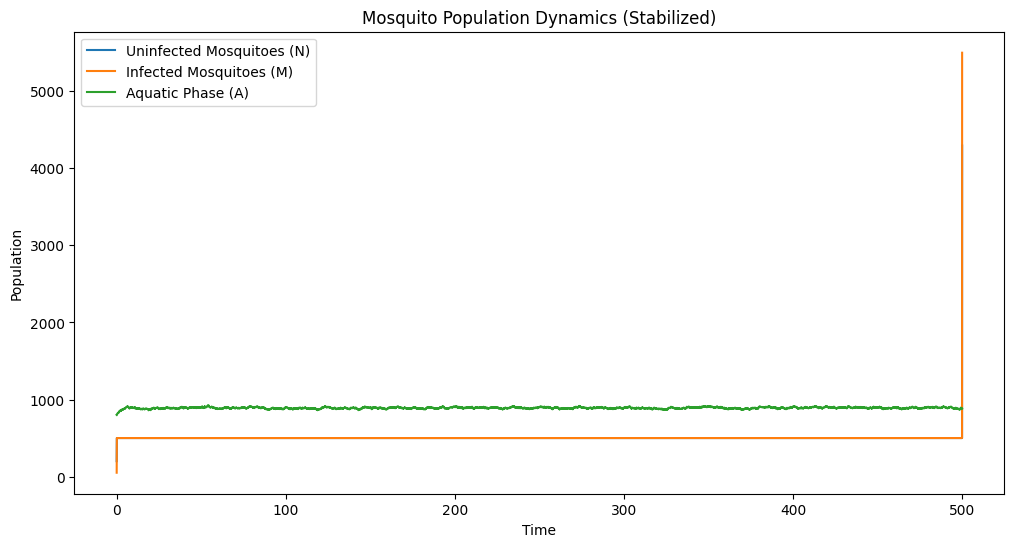

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters (adjusted for scaling)
gamma_N, gamma_M, e, p1, p2, beta = 0.35, 0.34, 0.1, 0.2, 0.7, 0.05
lambda_N, lambda_M, tau, alpha, gamma = 0.15, 0.15, 0.4, 0.05, 0.2
sigma_N, sigma_M, sigma_A = 0.01, 0.01, 0.01
K1, K2 = 1000, 2000  # Adjusted carrying capacities

# Time setup
T = 500  # Total time
dt = 0.05  # Time step (reduced for stability)
n_steps = int(T / dt)

# Initial conditions
N, M, A = np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps)
N[0], M[0], A[0] = 200, 50, 800  # Scaled initial populations

# Brownian increments
dB1 = np.sqrt(dt) * np.random.randn(n_steps)
dB2 = np.sqrt(dt) * np.random.randn(n_steps)
dB3 = np.sqrt(dt) * np.random.randn(n_steps)

# Simulation loop
for t in range(n_steps - 1):
    # Ensure populations stay within carrying capacity
    if N[t] + M[t] > K1:
        N[t], M[t] = K1 / 2, K1 / 2
    if A[t] > K2:
        A[t] = K2

    # Compute drift and diffusion terms
    f_N = gamma_N * N[t] * (1 - (N[t] + M[t]) / K1) + e * M[t] * (1 - (N[t] + M[t]) / K1) + \
          p1 * A[t] * N[t] - beta * N[t] * M[t] - lambda_N * N[t]
    g_N = sigma_N * N[t]
    f_N = min(f_N, 1e5)  # Cap drift term
    N[t+1] = N[t] + f_N * dt + g_N * dB1[t]
    N[t+1] = max(N[t+1], 0)  # Ensure non-negative population

    f_M = gamma_M * M[t] * (1 - (N[t] + M[t]) / K1) + p2 * A[t] * M[t] + beta * N[t] * M[t] - lambda_M * M[t]
    g_M = sigma_M * M[t]
    f_M = min(f_M, 1e5)  # Cap drift term
    M[t+1] = M[t] + f_M * dt + g_M * dB2[t]
    M[t+1] = max(M[t+1], 0)  # Ensure non-negative population

    f_A = tau * (1 - A[t] / K2) * (M[t] + N[t]) - (alpha + gamma) * A[t]
    g_A = sigma_A * A[t]
    f_A = min(f_A, 1e5)  # Cap drift term
    A[t+1] = A[t] + f_A * dt + g_A * dB3[t]
    A[t+1] = max(A[t+1], 0)  # Ensure non-negative population

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(np.linspace(0, T, n_steps), N, label='Uninfected Mosquitoes (N)')
plt.plot(np.linspace(0, T, n_steps), M, label='Infected Mosquitoes (M)')
plt.plot(np.linspace(0, T, n_steps), A, label='Aquatic Phase (A)')
plt.xlabel('Time')
plt.ylabel('Population')
plt.legend()
plt.title('Mosquito Population Dynamics (Stabilized)')
plt.show()


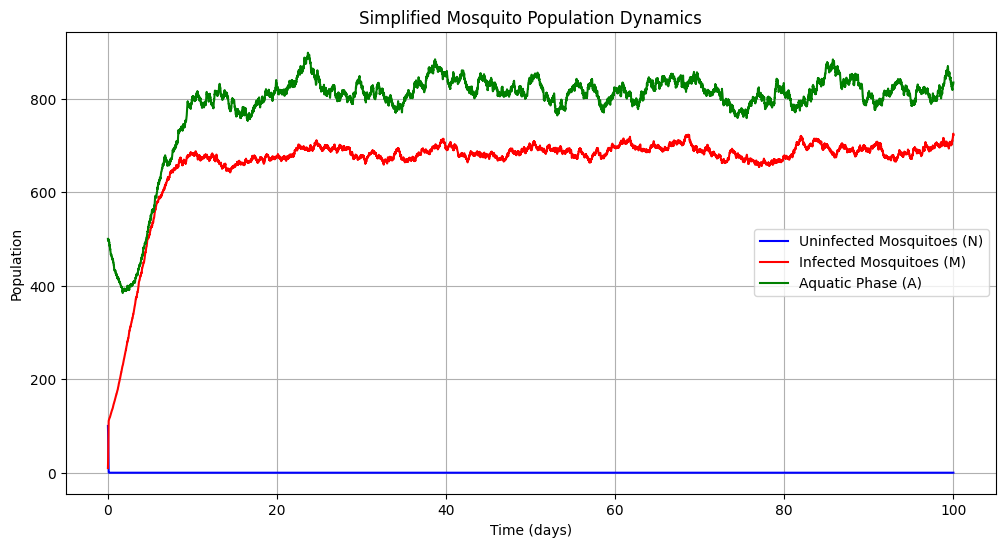

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
gamma_N, gamma_M = 0.35, 0.8  # Growth rates
lambda_N, lambda_M = 0.25, 0.25  # Mortality rates
beta = 0.6  # Infection rate
tau, alpha, gamma = 0.7, 0.2, 0.15  # Aquatic dynamics
sigma_N, sigma_M, sigma_A = 0.01, 0.02, 0.03  # Noise terms
K1, K2 = 1000, 2000  # Carrying capacities

# Time setup
T = 100  # Total time (days)
dt = 0.01  # Time step
n_steps = int(T / dt)

# Initial populations
N, M, A = np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps)
N[0], M[0], A[0] = 100, 10, 500  # Initial values

# Brownian increments
dB1 = np.sqrt(dt) * np.random.randn(n_steps)
dB2 = np.sqrt(dt) * np.random.randn(n_steps)
dB3 = np.sqrt(dt) * np.random.randn(n_steps)

# Simulation loop
for t in range(n_steps - 1):
    # Drift and diffusion for N
    f_N = gamma_N * N[t] * (1 - (N[t] + M[t]) / K1) - beta * N[t] * M[t] - lambda_N * N[t]
    g_N = sigma_N * N[t]
    N[t+1] = N[t] + f_N * dt + g_N * dB1[t]
    N[t+1] = max(N[t+1], 0)  # Ensure non-negative population

    # Drift and diffusion for M
    f_M = gamma_M * M[t] * (1 - (N[t] + M[t]) / K1) + beta * N[t] * M[t] - lambda_M * M[t]
    g_M = sigma_M * M[t]
    M[t+1] = M[t] + f_M * dt + g_M * dB2[t]
    M[t+1] = max(M[t+1], 0)  # Ensure non-negative population

    # Drift and diffusion for A
    f_A = tau * (1 - A[t] / K2) * (N[t] + M[t]) - (alpha + gamma) * A[t]
    g_A = sigma_A * A[t]
    A[t+1] = A[t] + f_A * dt + g_A * dB3[t]
    A[t+1] = max(A[t+1], 0)  # Ensure non-negative population

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(np.linspace(0, T, n_steps), N, label='Uninfected Mosquitoes (N)', color='blue')
plt.plot(np.linspace(0, T, n_steps), M, label='Infected Mosquitoes (M)', color='red')
plt.plot(np.linspace(0, T, n_steps), A, label='Aquatic Phase (A)', color='green')
plt.xlabel('Time (days)')
plt.ylabel('Population')
plt.title('Simplified Mosquito Population Dynamics')
plt.legend()
plt.grid()
plt.show()


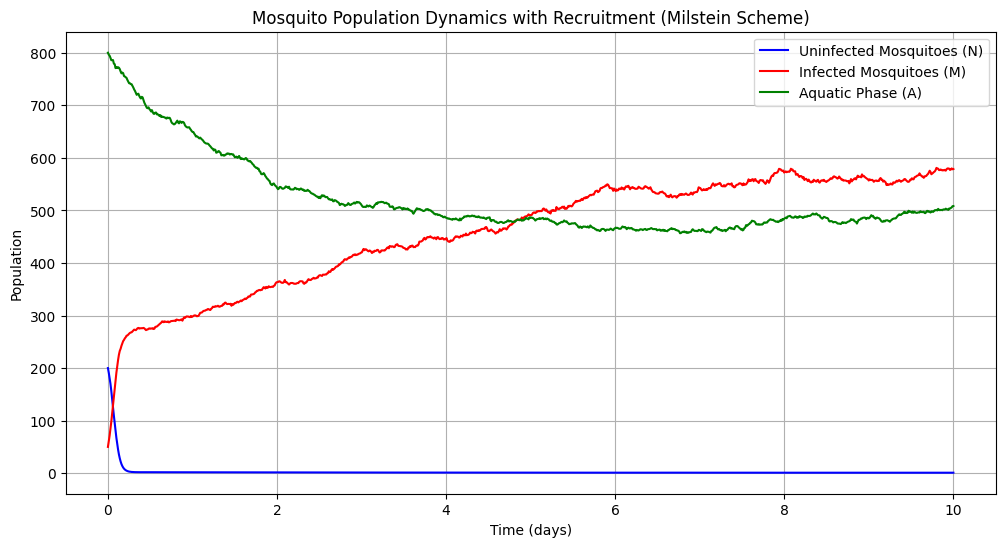

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
gamma_N, gamma_M = 0.5, 0.4  # Growth rates
lambda_N, lambda_M = 0.2, 0.25  # Mortality rates
beta = 0.1  # Infection rate
tau, alpha, gamma = 0.3, 0.1, 0.15  # Aquatic dynamics
sigma_N, sigma_M, sigma_A = 0.05, 0.04, 0.03  # Noise terms
K1, K2 = 1000, 2000  # Carrying capacities
r_N = 50  # Recruitment rate for uninfected mosquitoes

# Time setup
T = 10  # Total time (days)
dt = 0.01  # Time step
n_steps = int(T / dt)

# Initial populations
N, M, A = np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps)
N[0], M[0], A[0] = 200, 50, 800  # Initial values

# Brownian increments
dB1 = np.sqrt(dt) * np.random.randn(n_steps)
dB2 = np.sqrt(dt) * np.random.randn(n_steps)
dB3 = np.sqrt(dt) * np.random.randn(n_steps)

# Simulation loop
for t in range(n_steps - 1):
    # Drift and diffusion for N
    f_N = r_N + gamma_N * N[t] * (1 - (N[t] + M[t]) / K1) - beta * N[t] * M[t] - lambda_N * N[t]
    g_N = sigma_N * N[t]
    N[t+1] = N[t] + f_N * dt + g_N * dB1[t] + 0.5 * g_N * sigma_N * (dB1[t]**2 - dt)
    N[t+1] = max(N[t+1], 0)  # Ensure non-negative population

    # Drift and diffusion for M
    f_M = gamma_M * M[t] * (1 - (N[t] + M[t]) / K1) + beta * N[t] * M[t] - lambda_M * M[t]
    g_M = sigma_M * M[t]
    M[t+1] = M[t] + f_M * dt + g_M * dB2[t] + 0.5 * g_M * sigma_M * (dB2[t]**2 - dt)
    M[t+1] = max(M[t+1], 0)  # Ensure non-negative population

    # Drift and diffusion for A
    f_A = tau * (1 - A[t] / K2) * (N[t] + M[t]) - (alpha + gamma) * A[t]
    g_A = sigma_A * A[t]
    A[t+1] = A[t] + f_A * dt + g_A * dB3[t] + 0.5 * g_A * sigma_A * (dB3[t]**2 - dt)
    A[t+1] = max(A[t+1], 0)  # Ensure non-negative population

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(np.linspace(0, T, n_steps), N, label='Uninfected Mosquitoes (N)', color='blue')
plt.plot(np.linspace(0, T, n_steps), M, label='Infected Mosquitoes (M)', color='red')
plt.plot(np.linspace(0, T, n_steps), A, label='Aquatic Phase (A)', color='green')
plt.xlabel('Time (days)')
plt.ylabel('Population')
plt.title('Mosquito Population Dynamics with Recruitment (Milstein Scheme)')
plt.legend()
plt.grid()
plt.show()


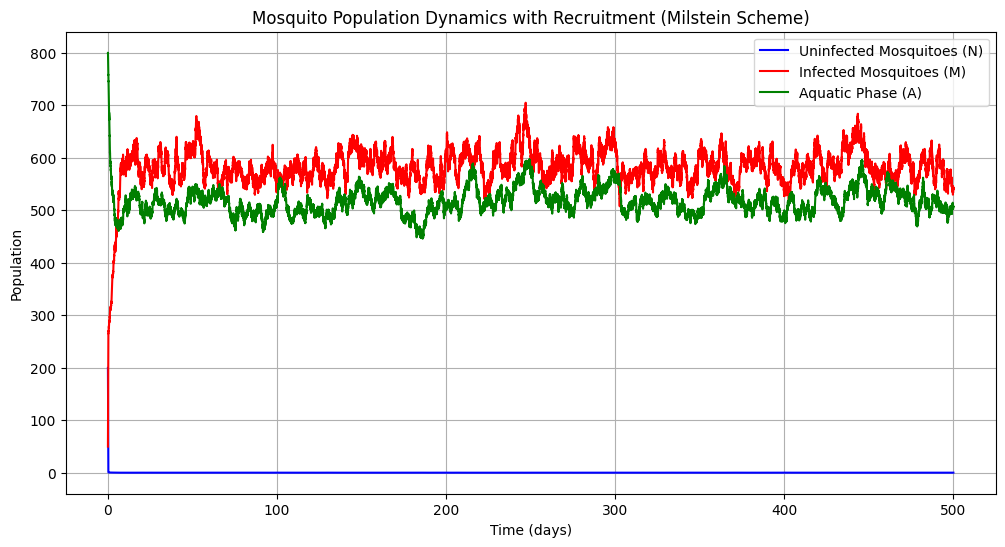

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
gamma_N, gamma_M = 0.5, 0.4  # Growth rates
lambda_N, lambda_M = 0.2, 0.25  # Mortality rates
beta, v = 0.1, 0.6  # Infection rate and vertical transmission rate
tau, alpha, gamma = 0.3, 0.1, 0.15  # Aquatic dynamics
sigma_N, sigma_M, sigma_A = 0.05, 0.04, 0.03  # Noise terms
K1, K2 = 1000, 2000  # Carrying capacities
r_N = 50  # Recruitment rate for uninfected mosquitoes

# Time setup
T = 500  # Total time (days)
dt = 0.01  # Time step
n_steps = int(T / dt)

# Initial populations
N, M, A = np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps)
N[0], M[0], A[0] = 200, 50, 800  # Initial values

# Brownian increments
dB1 = np.sqrt(dt) * np.random.randn(n_steps)
dB2 = np.sqrt(dt) * np.random.randn(n_steps)
dB3 = np.sqrt(dt) * np.random.randn(n_steps)

# Simulation loop
for t in range(n_steps - 1):
    # Drift and diffusion for N
    f_N = r_N * (1 - v * M[t] / (M[t] + N[t])) + gamma_N * N[t] * (1 - (N[t] + M[t]) / K1) - beta * N[t] * M[t] - lambda_N * N[t]
    g_N = sigma_N * N[t]
    N[t+1] = N[t] + f_N * dt + g_N * dB1[t] + 0.5 * g_N * sigma_N * (dB1[t]**2 - dt)
    N[t+1] = max(N[t+1], 0)  # Ensure non-negative population

    # Drift and diffusion for M
    f_M = r_N * v * M[t] / (M[t] + N[t]) + gamma_M * M[t] * (1 - (N[t] + M[t]) / K1) + beta * N[t] * M[t] - lambda_M * M[t]
    g_M = sigma_M * M[t]
    M[t+1] = M[t] + f_M * dt + g_M * dB2[t] + 0.5 * g_M * sigma_M * (dB2[t]**2 - dt)
    M[t+1] = max(M[t+1], 0)  # Ensure non-negative population

    # Drift and diffusion for A
    f_A = tau * (1 - A[t] / K2) * (N[t] + M[t]) - (alpha + gamma) * A[t]
    g_A = sigma_A * A[t]
    A[t+1] = A[t] + f_A * dt + g_A * dB3[t] + 0.5 * g_A * sigma_A * (dB3[t]**2 - dt)
    A[t+1] = max(A[t+1], 0)  # Ensure non-negative population

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(np.linspace(0, T, n_steps), N, label='Uninfected Mosquitoes (N)', color='blue')
plt.plot(np.linspace(0, T, n_steps), M, label='Infected Mosquitoes (M)', color='red')
plt.plot(np.linspace(0, T, n_steps), A, label='Aquatic Phase (A)', color='green')
plt.xlabel('Time (days)')
plt.ylabel('Population')
plt.title('Mosquito Population Dynamics with Recruitment (Milstein Scheme)')
plt.legend()
plt.grid()
plt.show()


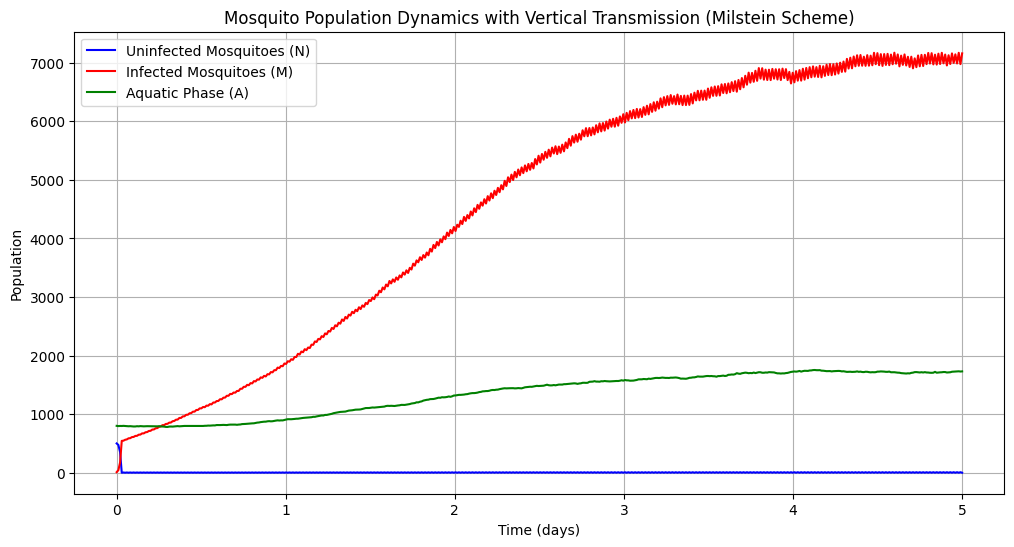

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
gamma_N, gamma_M = 0.30, 0.4  # Growth rates
lambda_N, lambda_M = 0.2, 0.25  # Mortality rates
beta = 0.6  # Infection rate
tau, alpha, gamma = 0.7, 0.2, 0.25  # Aquatic dynamics
sigma_N, sigma_M, sigma_A = 0.05, 0.02, 0.03  # Noise terms
K1, K2 = 1000, 2000  # Carrying capacities
r_N = 0  # Recruitment rate for uninfected mosquitoes
p2 = 0.5  # Vertical transmission rate

# Time setup
T = 5  # Total time (days)
dt = 0.01  # Time step
n_steps = int(T / dt)

# Initial populations
N, M, A = np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps)
N[0], M[0], A[0] = 500, 10, 800  # Initial values

# Brownian increments
dB1 = np.sqrt(dt) * np.random.randn(n_steps)
dB2 = np.sqrt(dt) * np.random.randn(n_steps)
dB3 = np.sqrt(dt) * np.random.randn(n_steps)

# Simulation loop
for t in range(n_steps - 1):
    # Drift and diffusion for N
    f_N = r_N + (1 - p2) * A[t] + gamma_N * N[t] * (1 - (N[t] + M[t]) / K1) - beta * N[t] * M[t] - lambda_N * N[t]
    g_N = sigma_N * N[t]
    N[t+1] = N[t] + f_N * dt + g_N * dB1[t] + 0.5 * g_N * sigma_N * (dB1[t]**2 - dt)
    N[t+1] = max(N[t+1], 0)  # Ensure non-negative population

    # Drift and diffusion for M
    f_M = p2 * A[t] + gamma_M * M[t] * (1 - (N[t] + M[t]) / K1) + beta * N[t] * M[t] - lambda_M * M[t]
    g_M = sigma_M * M[t]
    M[t+1] = M[t] + f_M * dt + g_M * dB2[t] + 0.5 * g_M * sigma_M * (dB2[t]**2 - dt)
    M[t+1] = max(M[t+1], 0)  # Ensure non-negative population

    # Drift and diffusion for A
    f_A = tau * (1 - A[t] / K2) * (N[t] + M[t]) - (alpha + gamma) * A[t]
    g_A = sigma_A * A[t]
    A[t+1] = A[t] + f_A * dt + g_A * dB3[t] + 0.5 * g_A * sigma_A * (dB3[t]**2 - dt)
    A[t+1] = max(A[t+1], 0)  # Ensure non-negative population

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(np.linspace(0, T, n_steps), N, label='Uninfected Mosquitoes (N)', color='blue')
plt.plot(np.linspace(0, T, n_steps), M, label='Infected Mosquitoes (M)', color='red')
plt.plot(np.linspace(0, T, n_steps), A, label='Aquatic Phase (A)', color='green')
plt.xlabel('Time (days)')
plt.ylabel('Population')
plt.title('Mosquito Population Dynamics with Vertical Transmission (Milstein Scheme)')
plt.legend()
plt.grid()
plt.show()


<ipython-input-56-686103a2716a>:27: RuntimeWarning: overflow encountered in scalar multiply
  f_N = (1 - p2) * A[t] + gamma_N * N[t] * (1 - (N[t] + M[t]) / K1) - beta * N[t] * M[t] - lambda_N * N[t]
<ipython-input-56-686103a2716a>:32: RuntimeWarning: overflow encountered in scalar multiply
  f_M = p2 * A[t] + gamma_M * M[t] * (1 - (N[t] + M[t]) / K1) + beta * N[t] * M[t] - lambda_M * M[t]
<ipython-input-56-686103a2716a>:27: RuntimeWarning: invalid value encountered in scalar add
  f_N = (1 - p2) * A[t] + gamma_N * N[t] * (1 - (N[t] + M[t]) / K1) - beta * N[t] * M[t] - lambda_N * N[t]
<ipython-input-56-686103a2716a>:32: RuntimeWarning: invalid value encountered in scalar add
  f_M = p2 * A[t] + gamma_M * M[t] * (1 - (N[t] + M[t]) / K1) + beta * N[t] * M[t] - lambda_M * M[t]
<ipython-input-56-686103a2716a>:37: RuntimeWarning: invalid value encountered in scalar add
  f_A = tau * (1 - A[t] / K2) * (N[t] + M[t]) - (alpha + gamma) * A[t]


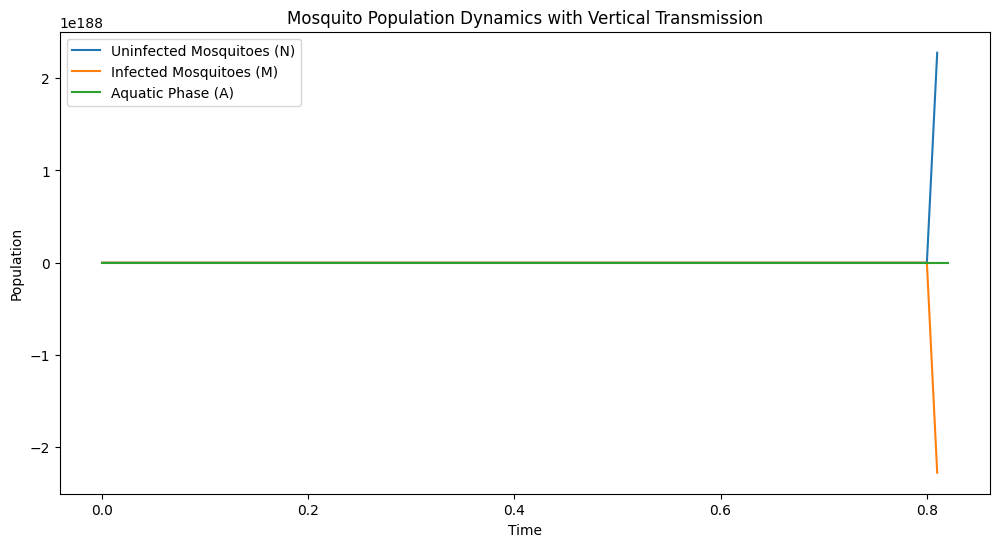

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters (example values)
gamma_N, gamma_M, beta, lambda_N, lambda_M, tau, alpha, gamma = 0.35, 0.34, 0.6, 0.21, 0.22, 0.25, 0.1, 0.3
sigma_N, sigma_M, sigma_A = 0.05, 0.04, 0.03
K1, K2 = 600, 1200
p2 = 0.7  # Vertical transmission rate

# Time setup
T = 100  # Total time
dt = 0.01  # Time step
n_steps = int(T / dt)

# Initial conditions
N, M, A = np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps)
N[0], M[0], A[0] = 200, 20, 500  # Initial populations

# Brownian increments
dB1 = np.sqrt(dt) * np.random.randn(n_steps)
dB2 = np.sqrt(dt) * np.random.randn(n_steps)
dB3 = np.sqrt(dt) * np.random.randn(n_steps)

# Simulation loop
for t in range(n_steps - 1):
    # Uninfected mosquitoes (N)
    f_N = (1 - p2) * A[t] + gamma_N * N[t] * (1 - (N[t] + M[t]) / K1) - beta * N[t] * M[t] - lambda_N * N[t]
    g_N = sigma_N * N[t]
    N[t+1] = N[t] + f_N * dt + g_N * dB1[t] + 0.5 * g_N * sigma_N * (dB1[t]**2 - dt)

    # Infected mosquitoes (M)
    f_M = p2 * A[t] + gamma_M * M[t] * (1 - (N[t] + M[t]) / K1) + beta * N[t] * M[t] - lambda_M * M[t]
    g_M = sigma_M * M[t]
    M[t+1] = M[t] + f_M * dt + g_M * dB2[t] + 0.5 * g_M * sigma_M * (dB2[t]**2 - dt)

    # Aquatic phase (A)
    f_A = tau * (1 - A[t] / K2) * (N[t] + M[t]) - (alpha + gamma) * A[t]
    g_A = sigma_A * A[t]
    A[t+1] = A[t] + f_A * dt + g_A * dB3[t] + 0.5 * g_A * sigma_A * (dB3[t]**2 - dt)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(np.linspace(0, T, n_steps), N, label='Uninfected Mosquitoes (N)')
plt.plot(np.linspace(0, T, n_steps), M, label='Infected Mosquitoes (M)')
plt.plot(np.linspace(0, T, n_steps), A, label='Aquatic Phase (A)')
plt.xlabel('Time')
plt.ylabel('Population')
plt.legend()
plt.title('Mosquito Population Dynamics with Vertical Transmission')
plt.show()


<ipython-input-53-2376548391b9>:37: RuntimeWarning: overflow encountered in scalar multiply
  drift_U = b_U * U[t - 1] + b_I * I[t - 1] * (1 - beta) - m * beta * U[t - 1] * I[t - 1] - mu_U * U[t - 1]
<ipython-input-53-2376548391b9>:38: RuntimeWarning: overflow encountered in scalar multiply
  drift_I = m * beta * U[t - 1] * I[t - 1] + b_I * I[t - 1] * beta - mu_I * I[t - 1]
<ipython-input-53-2376548391b9>:37: RuntimeWarning: invalid value encountered in scalar multiply
  drift_U = b_U * U[t - 1] + b_I * I[t - 1] * (1 - beta) - m * beta * U[t - 1] * I[t - 1] - mu_U * U[t - 1]
<ipython-input-53-2376548391b9>:38: RuntimeWarning: invalid value encountered in scalar multiply
  drift_I = m * beta * U[t - 1] * I[t - 1] + b_I * I[t - 1] * beta - mu_I * I[t - 1]


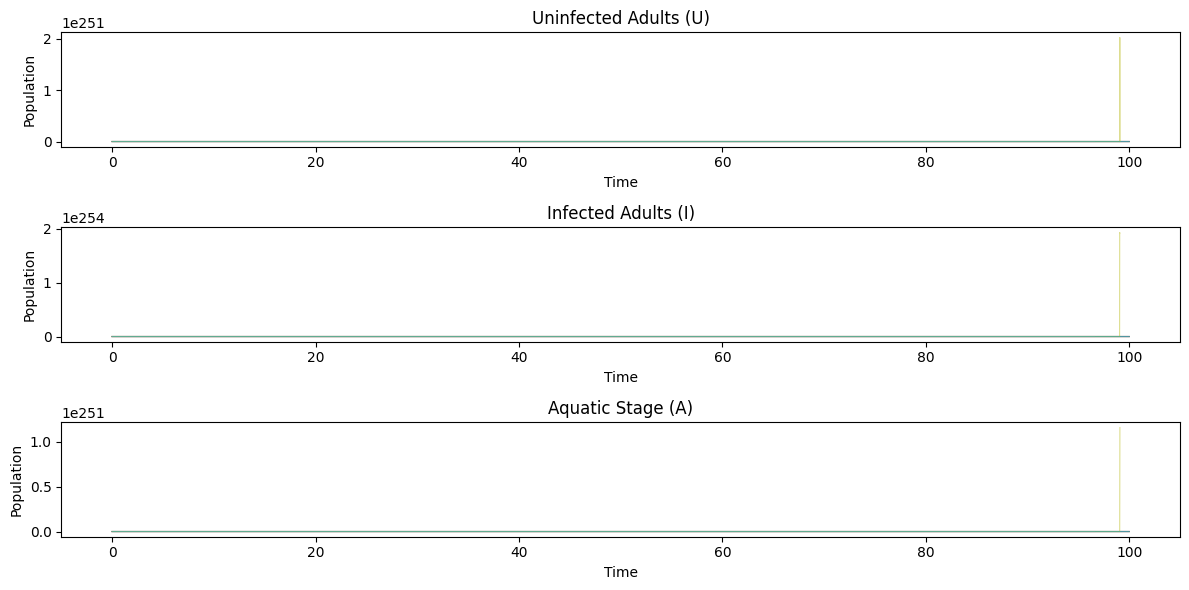

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
b_U = 0.2  # Birth rate of uninfected
b_I = 0.15  # Birth rate of infected
beta = 0.3  # Probability of infection via mating
m = 0.1  # Mating rate
p_v = 0.2  # Probability of vertical transmission
mu_U = 0.1  # Mortality of uninfected
mu_I = 0.1  # Mortality of infected
mu_A = 0.1  # Mortality of aquatic stage
sigma_U = 0.05  # Stochasticity for U
sigma_I = 0.05  # Stochasticity for I
sigma_A = 0.05  # Stochasticity for A
T = 100  # Total time
dt = 0.01  # Time step
N = int(T / dt)  # Number of steps
num_sim = 10  # Number of simulations

# Initial conditions
U0, I0, A0 = 50, 10, 30

# Milstein method implementation
def simulate_milstein():
    U = np.zeros(N)
    I = np.zeros(N)
    A = np.zeros(N)
    U[0], I[0], A[0] = U0, I0, A0

    for t in range(1, N):
        dW_U = np.random.normal(0, np.sqrt(dt))
        dW_I = np.random.normal(0, np.sqrt(dt))
        dW_A = np.random.normal(0, np.sqrt(dt))

        # Drift terms
        drift_U = b_U * U[t - 1] + b_I * I[t - 1] * (1 - beta) - m * beta * U[t - 1] * I[t - 1] - mu_U * U[t - 1]
        drift_I = m * beta * U[t - 1] * I[t - 1] + b_I * I[t - 1] * beta - mu_I * I[t - 1]
        drift_A = p_v * b_I * I[t - 1] + (1 - p_v) * b_U * U[t - 1] - mu_A * A[t - 1]

        # Diffusion terms
        diffusion_U = sigma_U * U[t - 1]
        diffusion_I = sigma_I * I[t - 1]
        diffusion_A = sigma_A * A[t - 1]

        # Milstein correction terms
        milstein_U = 0.5 * sigma_U**2 * (dW_U**2 - dt)
        milstein_I = 0.5 * sigma_I**2 * (dW_I**2 - dt)
        milstein_A = 0.5 * sigma_A**2 * (dW_A**2 - dt)

        # Update equations
        U[t] = max(U[t - 1] + drift_U * dt + diffusion_U * dW_U + milstein_U, 0)
        I[t] = max(I[t - 1] + drift_I * dt + diffusion_I * dW_I + milstein_I, 0)
        A[t] = max(A[t - 1] + drift_A * dt + diffusion_A * dW_A + milstein_A, 0)

    return U, I, A

# Run simulations
results_U = []
results_I = []
results_A = []

for _ in range(num_sim):
    U, I, A = simulate_milstein()
    results_U.append(U)
    results_I.append(I)
    results_A.append(A)

# Plot results
time = np.linspace(0, T, N)

plt.figure(figsize=(12, 6))

# Plot U
plt.subplot(3, 1, 1)
for sim in results_U:
    plt.plot(time, sim, alpha=0.5, linewidth=0.8)
plt.title('Uninfected Adults (U)')
plt.xlabel('Time')
plt.ylabel('Population')

# Plot I
plt.subplot(3, 1, 2)
for sim in results_I:
    plt.plot(time, sim, alpha=0.5, linewidth=0.8)
plt.title('Infected Adults (I)')
plt.xlabel('Time')
plt.ylabel('Population')

# Plot A
plt.subplot(3, 1, 3)
for sim in results_A:
    plt.plot(time, sim, alpha=0.5, linewidth=0.8)
plt.title('Aquatic Stage (A)')
plt.xlabel('Time')
plt.ylabel('Population')

plt.tight_layout()
plt.show()


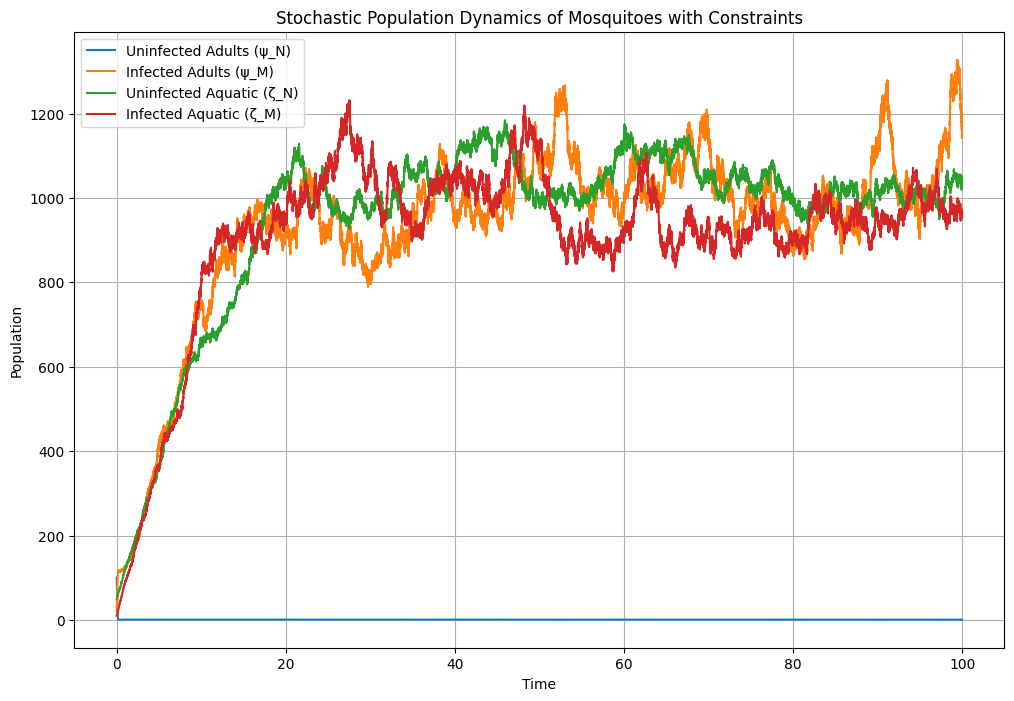

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
tau_N = 50      # Recruitment rate for uninfected aquatic mosquitoes
tau_M = 30      # Recruitment rate for infected aquatic mosquitoes
a_N = 0.1       # Mortality rate of uninfected aquatic mosquitoes
a_M = 0.15      # Mortality rate of infected aquatic mosquitoes
d_N = 0.05      # Mortality rate of uninfected adult mosquitoes
d_M = 0.07      # Mortality rate of infected adult mosquitoes
gamma_N = 0.2   # Maturation rate of uninfected aquatic mosquitoes
gamma_M = 0.25  # Maturation rate of infected aquatic mosquitoes
beta = 0.3      # Probability of uninfected adults becoming infected
theta = 0.6     # Probability of infected adults producing infected aquatic mosquitoes

# Volatility terms
sigma_psi_N = 0.05
sigma_psi_M = 0.07
sigma_zeta_N = 0.04
sigma_zeta_M = 0.06

# Carrying capacity
K = 1000  # Maximum population for each class

T = 100         # Total time
dt = 0.001      # Smaller time step
N = int(T / dt) # Number of time steps

# Initial conditions
psi_N = np.zeros(N)
psi_M = np.zeros(N)
zeta_N = np.zeros(N)
zeta_M = np.zeros(N)

psi_N[0] = 100  # Initial uninfected adults
psi_M[0] = 20   # Initial infected adults
zeta_N[0] = 50  # Initial uninfected aquatic
zeta_M[0] = 10  # Initial infected aquatic

# Stochastic Milstein method
for t in range(1, N):
    dB_psi_N = np.sqrt(dt) * np.random.normal()
    dB_psi_M = np.sqrt(dt) * np.random.normal()
    dB_zeta_N = np.sqrt(dt) * np.random.normal()
    dB_zeta_M = np.sqrt(dt) * np.random.normal()

    # Logistic growth for constraints
    d_zeta_N = (tau_N + (1 - theta) * psi_M[t-1] - a_N * zeta_N[t-1] - gamma_N * zeta_N[t-1]) * (1 - zeta_N[t-1] / K)
    d_zeta_M = (tau_M + theta * psi_M[t-1] - a_M * zeta_M[t-1] - gamma_M * zeta_M[t-1]) * (1 - zeta_M[t-1] / K)
    d_psi_N = (gamma_N * zeta_N[t-1] - beta * psi_N[t-1] * psi_M[t-1] - d_N * psi_N[t-1]) * (1 - psi_N[t-1] / K)
    d_psi_M = (gamma_M * zeta_M[t-1] + beta * psi_N[t-1] * psi_M[t-1] - d_M * psi_M[t-1]) * (1 - psi_M[t-1] / K)

    # Update with Milstein terms
    zeta_N[t] = zeta_N[t-1] + d_zeta_N * dt + sigma_zeta_N * zeta_N[t-1] * dB_zeta_N
    zeta_M[t] = zeta_M[t-1] + d_zeta_M * dt + sigma_zeta_M * zeta_M[t-1] * dB_zeta_M
    psi_N[t] = psi_N[t-1] + d_psi_N * dt + sigma_psi_N * psi_N[t-1] * dB_psi_N
    psi_M[t] = psi_M[t-1] + d_psi_M * dt + sigma_psi_M * psi_M[t-1] * dB_psi_M

    # Avoid negative values
    zeta_N[t] = max(0, zeta_N[t])
    zeta_M[t] = max(0, zeta_M[t])
    psi_N[t] = max(0, psi_N[t])
    psi_M[t] = max(0, psi_M[t])

# Plot the results
time = np.linspace(0, T, N)

plt.figure(figsize=(12, 8))

plt.plot(time, psi_N, label="Uninfected Adults (\u03C8_N)")
plt.plot(time, psi_M, label="Infected Adults (\u03C8_M)")
plt.plot(time, zeta_N, label="Uninfected Aquatic (\u03B6_N)")
plt.plot(time, zeta_M, label="Infected Aquatic (\u03B6_M)")

plt.title("Stochastic Population Dynamics of Mosquitoes with Constraints")
plt.xlabel("Time")
plt.ylabel("Population")
plt.legend()
plt.grid()
plt.show()


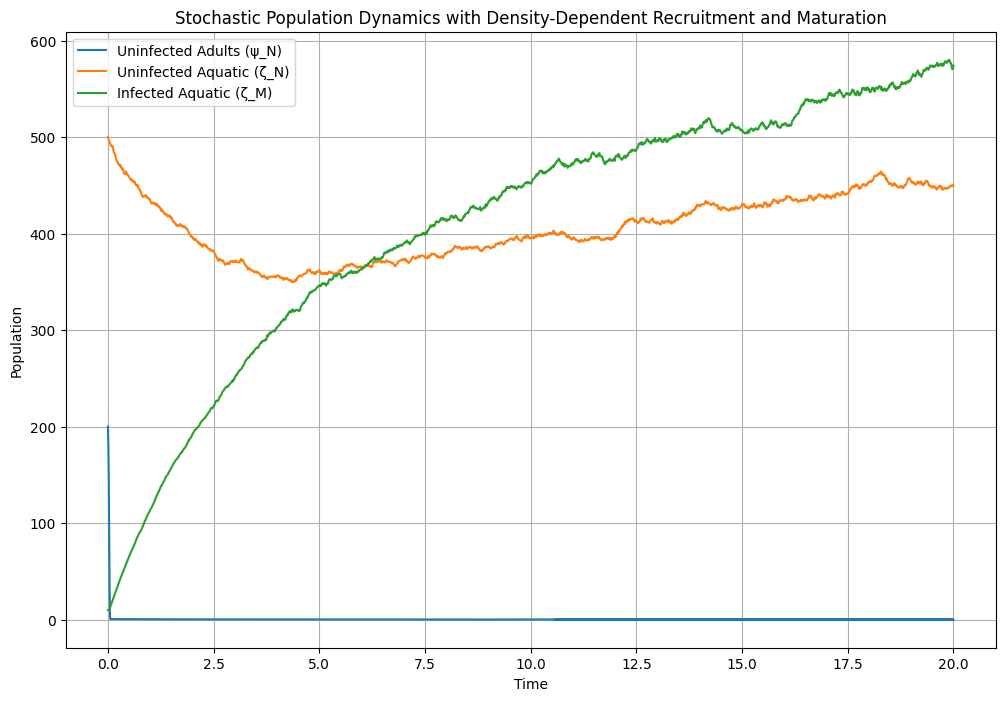

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
tau_N = 100      # Recruitment rate for uninfected aquatic mosquitoes
tau_M = 1      # Recruitment rate for infected aquatic mosquitoes
a_N = 0.30       # Mortality rate of uninfected aquatic mosquitoes
a_M = 0.30      # Mortality rate of infected aquatic mosquitoes
d_N = 0.22      # Mortality rate of uninfected adult mosquitoes
d_M = 0.22      # Mortality rate of infected adult mosquitoes
gamma_N = 0.2   # Maturation rate of uninfected aquatic mosquitoes
gamma_M = 0.2  # Maturation rate of infected aquatic mosquitoes
beta = 0.5      # Probability of uninfected adults becoming infected
theta = 0.6     # Probability of infected adults producing infected aquatic mosquitoes

# Volatility terms
sigma_psi_N = 0.01
sigma_psi_M = 0.01
sigma_zeta_N = 0.02
sigma_zeta_M = 0.02

# Carrying capacities
K_zeta = 1500  # Carrying capacity for aquatic stages
K_psi = 1000  # Carrying capacity for adult stages

T = 20         # Total time   2920
dt = 0.01      # Smaller time step
N = int(T / dt) # Number of time steps

# Initial conditions
psi_N = np.zeros(N)
psi_M = np.zeros(N)
zeta_N = np.zeros(N)
zeta_M = np.zeros(N)

psi_N[0] = 200  # Initial uninfected adults
psi_M[0] = 20   # Initial infected adults
zeta_N[0] = 500  # Initial uninfected aquatic
zeta_M[0] = 10  # Initial infected aquatic

# Stochastic Milstein method
for t in range(1, N):
    dB_psi_N = np.sqrt(dt) * np.random.normal()
    dB_psi_M = np.sqrt(dt) * np.random.normal()
    dB_zeta_N = np.sqrt(dt) * np.random.normal()
    dB_zeta_M = np.sqrt(dt) * np.random.normal()

    # Aquatic phases
    d_zeta_N = (tau_N * (1 - (zeta_N[t-1] + zeta_M[t-1]) / K_zeta) + (1 - theta) * psi_M[t-1]
                - a_N * zeta_N[t-1] - gamma_N * zeta_N[t-1])
    d_zeta_M = (tau_M * (1 - (zeta_N[t-1] + zeta_M[t-1]) / K_zeta) + theta * psi_M[t-1]
                - a_M * zeta_M[t-1] - gamma_M * zeta_M[t-1])

    # Adult phases
    d_psi_N = (gamma_N * zeta_N[t-1] * (1 - (psi_N[t-1] + psi_M[t-1]) / K_psi)
               - beta * psi_N[t-1] * psi_M[t-1] - d_N * psi_N[t-1])
    d_psi_M = (gamma_M * zeta_M[t-1] * (1 - (psi_N[t-1] + psi_M[t-1]) / K_psi)
               + beta * psi_N[t-1] * psi_M[t-1] - d_M * psi_M[t-1])

    # Update with stochastic terms
    zeta_N[t] = zeta_N[t-1] + d_zeta_N * dt + sigma_zeta_N * zeta_N[t-1] * dB_zeta_N
    zeta_M[t] = zeta_M[t-1] + d_zeta_M * dt + sigma_zeta_M * zeta_M[t-1] * dB_zeta_M
    psi_N[t] = psi_N[t-1] + d_psi_N * dt + sigma_psi_N * psi_N[t-1] * dB_psi_N
    psi_M[t] = psi_M[t-1] + d_psi_M * dt + sigma_psi_M * psi_M[t-1] * dB_psi_M

    # Ensure non-negativity
    zeta_N[t] = max(0, zeta_N[t])
    zeta_M[t] = max(0, zeta_M[t])
    psi_N[t] = max(0, psi_N[t])
    psi_M[t] = max(0, psi_M[t])

# Plot results
time = np.linspace(0, T, N)

plt.figure(figsize=(12, 8))

plt.plot(time, psi_N, label="Uninfected Adults (\u03C8_N)")
# plt.plot(time, psi_M, label="Infected Adults (\u03C8_M)")
plt.plot(time, zeta_N, label="Uninfected Aquatic (\u03B6_N)")
plt.plot(time, zeta_M, label="Infected Aquatic (\u03B6_M)")

plt.title("Stochastic Population Dynamics with Density-Dependent Recruitment and Maturation")
plt.xlabel("Time")
plt.ylabel("Population")
plt.legend()
plt.grid()
plt.show()


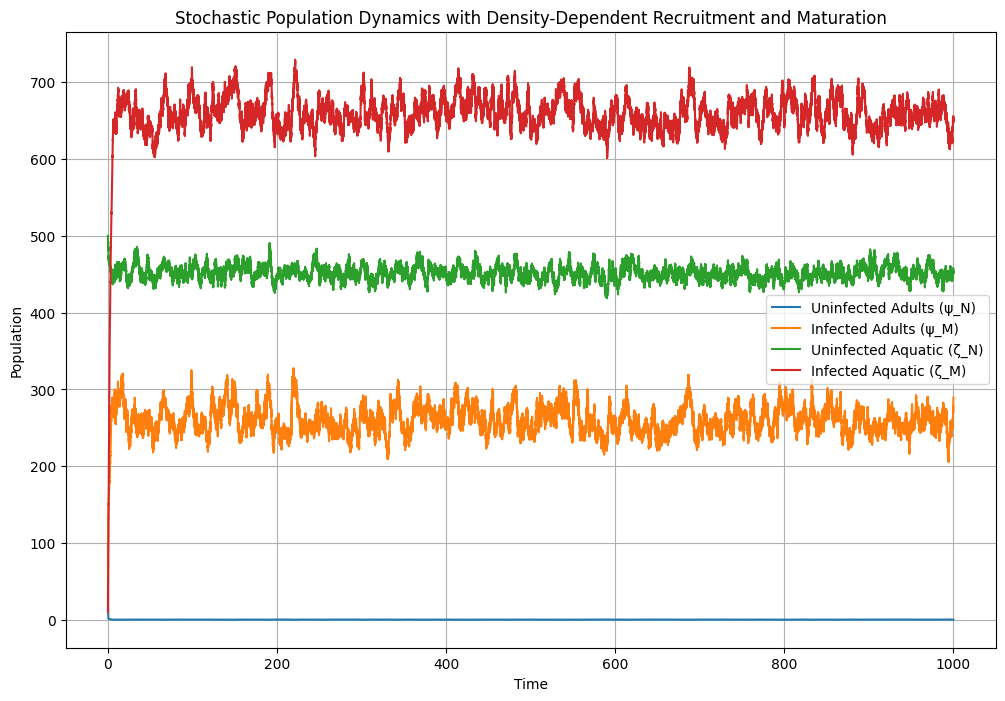

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
tau_N = 200      # Recruitment rate for uninfected aquatic mosquitoes
tau_M = 200      # Recruitment rate for infected aquatic mosquitoes
a_N = 0.30       # Mortality rate of uninfected aquatic mosquitoes
a_M = 0.30      # Mortality rate of infected aquatic mosquitoes
d_N = 0.22      # Mortality rate of uninfected adult mosquitoes
d_M = 0.22      # Mortality rate of infected adult mosquitoes
gamma_N = 0.2   # Maturation rate of uninfected aquatic mosquitoes
gamma_M = 0.2  # Maturation rate of infected aquatic mosquitoes
beta = 0.2      # Probability of uninfected adults becoming infected
theta = 0.7    # Probability of infected adults producing infected aquatic mosquitoes

# Volatility terms
sigma_psi_N = 0.05
sigma_psi_M = 0.05
sigma_zeta_N = 0.02
sigma_zeta_M = 0.02

# Carrying capacities
K_zeta = 1500  # Carrying capacity for aquatic stages
K_psi = 1000  # Carrying capacity for adult stages

T = 1000       # Total time   2920
dt = 0.01      # Smaller time step
N = int(T / dt) # Number of time steps

# Initial conditions
psi_N = np.zeros(N)
psi_M = np.zeros(N)
zeta_N = np.zeros(N)
zeta_M = np.zeros(N)

psi_N[0] = 100  # Initial uninfected adults
psi_M[0] = 20   # Initial infected adults
zeta_N[0] = 500  # Initial uninfected aquatic
zeta_M[0] = 10  # Initial infected aquatic

# Stochastic Milstein method
for t in range(1, N):
    dB_psi_N = np.sqrt(dt) * np.random.normal()
    dB_psi_M = np.sqrt(dt) * np.random.normal()
    dB_zeta_N = np.sqrt(dt) * np.random.normal()
    dB_zeta_M = np.sqrt(dt) * np.random.normal()

    # Aquatic phases
    d_zeta_N = (tau_N * (1 - (psi_N[t-1] + psi_M[t-1]) / K_psi) + (1 - theta) * psi_M[t-1]
                - a_N * zeta_N[t-1] - gamma_N * zeta_N[t-1])
    d_zeta_M = (tau_M * (1 - (psi_N[t-1] + psi_M[t-1]) / K_psi) + theta * psi_M[t-1]
                - a_M * zeta_M[t-1] - gamma_M * zeta_M[t-1])

    # Adult phases
    d_psi_N = (gamma_N * zeta_N[t-1] * (1 - (zeta_N[t-1] + zeta_M[t-1]) / K_zeta)
               - beta * psi_N[t-1] * psi_M[t-1] - d_N * psi_N[t-1])
    d_psi_M = (gamma_M * zeta_M[t-1] * (1 - (zeta_N[t-1] + zeta_M[t-1]) / K_zeta)
               + beta * psi_N[t-1] * psi_M[t-1] - d_M * psi_M[t-1])

    # Update with stochastic terms
    zeta_N[t] = zeta_N[t-1] + d_zeta_N * dt + sigma_zeta_N * zeta_N[t-1] * dB_zeta_N
    zeta_M[t] = zeta_M[t-1] + d_zeta_M * dt + sigma_zeta_M * zeta_M[t-1] * dB_zeta_M
    psi_N[t] = psi_N[t-1] + d_psi_N * dt + sigma_psi_N * psi_N[t-1] * dB_psi_N
    psi_M[t] = psi_M[t-1] + d_psi_M * dt + sigma_psi_M * psi_M[t-1] * dB_psi_M

    # Ensure non-negativity
    zeta_N[t] = max(0, zeta_N[t])
    zeta_M[t] = max(0, zeta_M[t])
    psi_N[t] = max(0, psi_N[t])
    psi_M[t] = max(0, psi_M[t])

# Plot results
time = np.linspace(0, T, N)

plt.figure(figsize=(12, 8))

plt.plot(time, psi_N, label="Uninfected Adults (\u03C8_N)")
plt.plot(time, psi_M, label="Infected Adults (\u03C8_M)")
plt.plot(time, zeta_N, label="Uninfected Aquatic (\u03B6_N)")
plt.plot(time, zeta_M, label="Infected Aquatic (\u03B6_M)")

plt.title("Stochastic Population Dynamics with Density-Dependent Recruitment and Maturation")
plt.xlabel("Time")
plt.ylabel("Population")
plt.legend()
plt.grid()
plt.show()


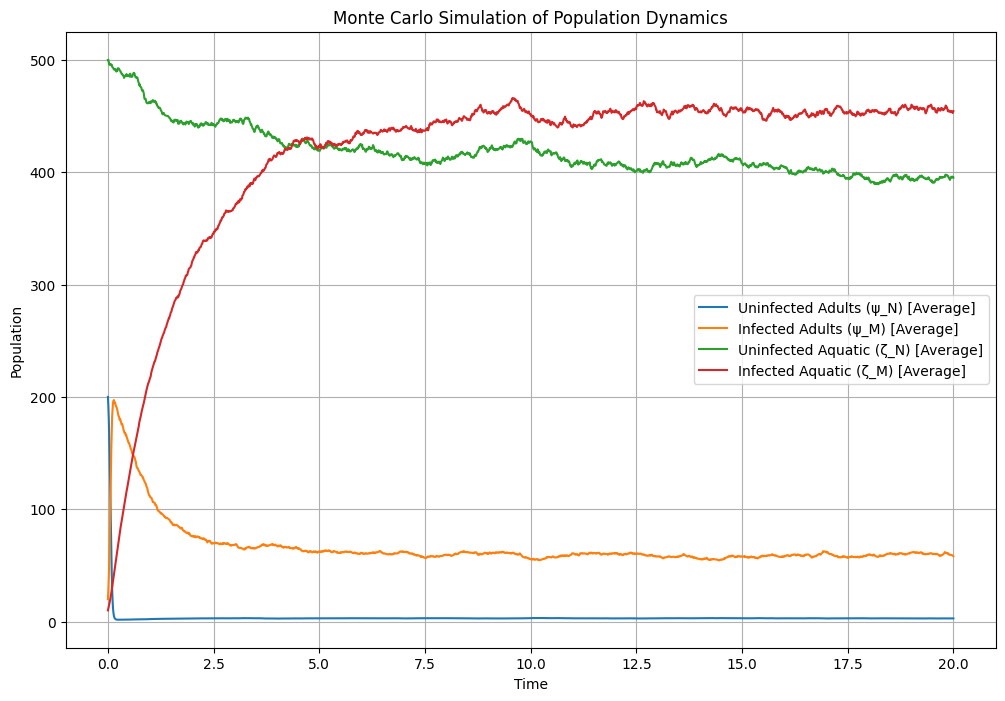

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
tau_N = 200      # Recruitment rate for uninfected aquatic mosquitoes
tau_M = 200      # Recruitment rate for infected aquatic mosquitoes
a_N = 0.30       # Mortality rate of uninfected aquatic mosquitoes
a_M = 0.30       # Mortality rate of infected aquatic mosquitoes
d_N = 0.22       # Mortality rate of uninfected adult mosquitoes
d_M = 0.22       # Mortality rate of infected adult mosquitoes
gamma_N = 0.2    # Maturation rate of uninfected aquatic mosquitoes
gamma_M = 0.2    # Maturation rate of infected aquatic mosquitoes
beta = 0.2       # Probability of uninfected adults becoming infected
theta = 0.7      # Probability of infected adults producing infected aquatic mosquitoes

# Volatility terms
sigma_psi_N = 0.05
sigma_psi_M = 0.05
sigma_zeta_N = 0.02
sigma_zeta_M = 0.02

# Carrying capacities
K_zeta = 1500  # Carrying capacity for aquatic stages
K_psi = 1000   # Carrying capacity for adult stages

T =  20      # Total time
dt = 0.01     # Time step
N = int(T / dt) # Number of time steps
MC_runs = 1  # Number of Monte Carlo runs

# Arrays to store results
psi_N_MC = np.zeros((MC_runs, N))
psi_M_MC = np.zeros((MC_runs, N))
zeta_N_MC = np.zeros((MC_runs, N))
zeta_M_MC = np.zeros((MC_runs, N))

# Monte Carlo simulation
for run in range(MC_runs):
    # Initial conditions for each run
    psi_N = np.zeros(N)
    psi_M = np.zeros(N)
    zeta_N = np.zeros(N)
    zeta_M = np.zeros(N)

    psi_N[0] = 200  # Initial uninfected adults
    psi_M[0] = 20   # Initial infected adults
    zeta_N[0] = 500  # Initial uninfected aquatic
    zeta_M[0] = 10   # Initial infected aquatic

    # Stochastic Milstein method
    for t in range(1, N):
        dB_psi_N = np.sqrt(dt) * np.random.normal()
        dB_psi_M = np.sqrt(dt) * np.random.normal()
        dB_zeta_N = np.sqrt(dt) * np.random.normal()
        dB_zeta_M = np.sqrt(dt) * np.random.normal()

        # Aquatic phases
        d_zeta_N = (tau_N * (1 - (psi_N[t-1] + psi_M[t-1]) / K_psi) + (1 - theta) * psi_M[t-1]
                    - a_N * zeta_N[t-1] - gamma_N * zeta_N[t-1])
        d_zeta_M = (tau_M * (1 - (psi_N[t-1] + psi_M[t-1]) / K_psi) + theta * psi_M[t-1]
                    - a_M * zeta_M[t-1] - gamma_M * zeta_M[t-1])

        # Adult phases
        d_psi_N = (gamma_N * zeta_N[t-1] * (1 - (zeta_N[t-1] + zeta_M[t-1]) / K_zeta)
                   - beta * psi_N[t-1] * psi_M[t-1] - d_N * psi_N[t-1])
        d_psi_M = (gamma_M * zeta_M[t-1] * (1 - (zeta_N[t-1] + zeta_M[t-1]) / K_zeta)
                   + beta * psi_N[t-1] * psi_M[t-1] - d_M * psi_M[t-1])

        # Update with stochastic terms
        zeta_N[t] = zeta_N[t-1] + d_zeta_N * dt + sigma_zeta_N * zeta_N[t-1] * dB_zeta_N
        zeta_M[t] = zeta_M[t-1] + d_zeta_M * dt + sigma_zeta_M * zeta_M[t-1] * dB_zeta_M
        psi_N[t] = psi_N[t-1] + d_psi_N * dt + sigma_psi_N * psi_N[t-1] * dB_psi_N
        psi_M[t] = psi_M[t-1] + d_psi_M * dt + sigma_psi_M * psi_M[t-1] * dB_psi_M

        # Ensure non-negativity
        zeta_N[t] = max(0, zeta_N[t])
        zeta_M[t] = max(0, zeta_M[t])
        psi_N[t] = max(0, psi_N[t])
        psi_M[t] = max(0, psi_M[t])

    # Store results
    psi_N_MC[run] = psi_N
    psi_M_MC[run] = psi_M
    zeta_N_MC[run] = zeta_N
    zeta_M_MC[run] = zeta_M

# Compute averages across Monte Carlo runs
avg_psi_N = np.mean(psi_N_MC, axis=0)
avg_psi_M = np.mean(psi_M_MC, axis=0)
avg_zeta_N = np.mean(zeta_N_MC, axis=0)
avg_zeta_M = np.mean(zeta_M_MC, axis=0)

# Plot results
time = np.linspace(0, T, N)

plt.figure(figsize=(12, 8))
plt.plot(time, avg_psi_N, label="Uninfected Adults (\u03C8_N) [Average]")
plt.plot(time, avg_psi_M, label="Infected Adults (\u03C8_M) [Average]")
plt.plot(time, avg_zeta_N, label="Uninfected Aquatic (\u03B6_N) [Average]")
plt.plot(time, avg_zeta_M, label="Infected Aquatic (\u03B6_M) [Average]")

plt.title("Monte Carlo Simulation of Population Dynamics")
plt.xlabel("Time")
plt.ylabel("Population")
plt.legend()
plt.grid()
plt.show()


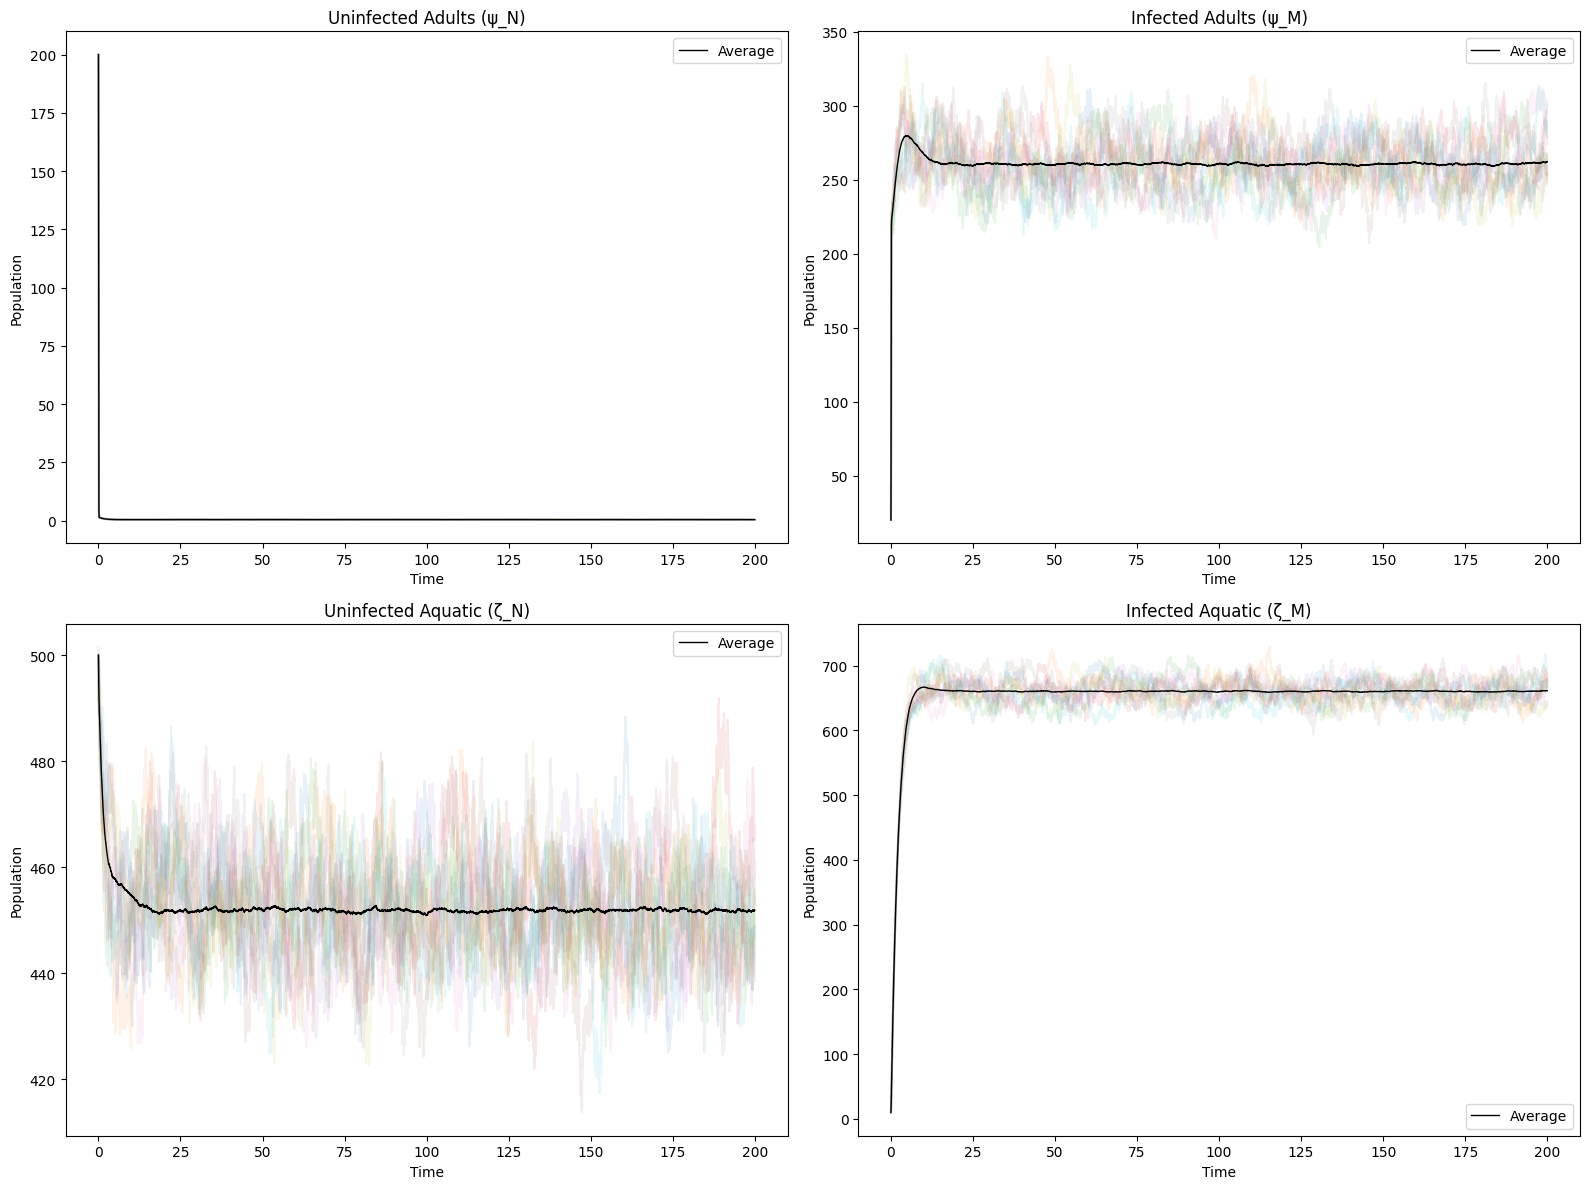

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
tau_N = 200
tau_M = 200
a_N = 0.30
a_M = 0.30
d_N = 0.22
d_M = 0.22
gamma_N = 0.2
gamma_M = 0.2
beta = 0.2
theta = 0.7

# Volatility terms
sigma_psi_N = 0.05
sigma_psi_M = 0.05
sigma_zeta_N = 0.02
sigma_zeta_M = 0.02

# Carrying capacities
K_zeta = 1500
K_psi = 1000

T = 200      # Total time
dt = 0.01    # Time step
N = int(T / dt)
MC_runs = 1000  # Number of Monte Carlo runs
sample_paths = 10  # Number of individual paths to plot

# Arrays to store results
psi_N_MC = np.zeros((MC_runs, N))
psi_M_MC = np.zeros((MC_runs, N))
zeta_N_MC = np.zeros((MC_runs, N))
zeta_M_MC = np.zeros((MC_runs, N))

# Monte Carlo simulation
for run in range(MC_runs):
    psi_N = np.zeros(N)
    psi_M = np.zeros(N)
    zeta_N = np.zeros(N)
    zeta_M = np.zeros(N)

    psi_N[0] = 200
    psi_M[0] = 20
    zeta_N[0] = 500
    zeta_M[0] = 10

    for t in range(1, N):
        dB_psi_N = np.sqrt(dt) * np.random.normal()
        dB_psi_M = np.sqrt(dt) * np.random.normal()
        dB_zeta_N = np.sqrt(dt) * np.random.normal()
        dB_zeta_M = np.sqrt(dt) * np.random.normal()

        d_zeta_N = (tau_N * (1 - (psi_N[t-1] + psi_M[t-1]) / K_psi) + (1 - theta) * psi_M[t-1]
                    - a_N * zeta_N[t-1] - gamma_N * zeta_N[t-1])
        d_zeta_M = (tau_M * (1 - (psi_N[t-1] + psi_M[t-1]) / K_psi) + theta * psi_M[t-1]
                    - a_M * zeta_M[t-1] - gamma_M * zeta_M[t-1])

        d_psi_N = (gamma_N * zeta_N[t-1] * (1 - (zeta_N[t-1] + zeta_M[t-1]) / K_zeta)
                   - beta * psi_N[t-1] * psi_M[t-1] - d_N * psi_N[t-1])
        d_psi_M = (gamma_M * zeta_M[t-1] * (1 - (zeta_N[t-1] + zeta_M[t-1]) / K_zeta)
                   + beta * psi_N[t-1] * psi_M[t-1] - d_M * psi_M[t-1])

        zeta_N[t] = zeta_N[t-1] + d_zeta_N * dt + sigma_zeta_N * zeta_N[t-1] * dB_zeta_N
        zeta_M[t] = zeta_M[t-1] + d_zeta_M * dt + sigma_zeta_M * zeta_M[t-1] * dB_zeta_M
        psi_N[t] = psi_N[t-1] + d_psi_N * dt + sigma_psi_N * psi_N[t-1] * dB_psi_N
        psi_M[t] = psi_M[t-1] + d_psi_M * dt + sigma_psi_M * psi_M[t-1] * dB_psi_M

        zeta_N[t] = max(0, zeta_N[t])
        zeta_M[t] = max(0, zeta_M[t])
        psi_N[t] = max(0, psi_N[t])
        psi_M[t] = max(0, psi_M[t])

    psi_N_MC[run] = psi_N
    psi_M_MC[run] = psi_M
    zeta_N_MC[run] = zeta_N
    zeta_M_MC[run] = zeta_M

# Compute averages
avg_psi_N = np.mean(psi_N_MC, axis=0)
avg_psi_M = np.mean(psi_M_MC, axis=0)
avg_zeta_N = np.mean(zeta_N_MC, axis=0)
avg_zeta_M = np.mean(zeta_M_MC, axis=0)

time = np.linspace(0, T, N)

# Plot results
plt.figure(figsize=(16, 12))

# Uninfected Adults
plt.subplot(2, 2, 1)
for i in range(sample_paths):
    plt.plot(time, psi_N_MC[i], alpha=0.1)
plt.plot(time, avg_psi_N, color='black', label='Average', linewidth=1)
plt.title('Uninfected Adults (\u03C8_N)')
plt.xlabel('Time')
plt.ylabel('Population')
plt.legend()

# Infected Adults
plt.subplot(2, 2, 2)
for i in range(sample_paths):
    plt.plot(time, psi_M_MC[i], alpha=0.1)
plt.plot(time, avg_psi_M, color='black', label='Average', linewidth=1)
plt.title('Infected Adults (\u03C8_M)')
plt.xlabel('Time')
plt.ylabel('Population')
plt.legend()

# Uninfected Aquatic
plt.subplot(2, 2, 3)
for i in range(sample_paths):
    plt.plot(time, zeta_N_MC[i], alpha=0.1)
plt.plot(time, avg_zeta_N, color='black', label='Average', linewidth=1)
plt.title('Uninfected Aquatic (\u03B6_N)')
plt.xlabel('Time')
plt.ylabel('Population')
plt.legend()

# Infected Aquatic
plt.subplot(2, 2, 4)
for i in range(sample_paths):
    plt.plot(time, zeta_M_MC[i], alpha=0.1)
plt.plot(time, avg_zeta_M, color='black', label='Average', linewidth=1)
plt.title('Infected Aquatic (\u03B6_M)')
plt.xlabel('Time')
plt.ylabel('Population')
plt.legend()

plt.tight_layout()
plt.show()


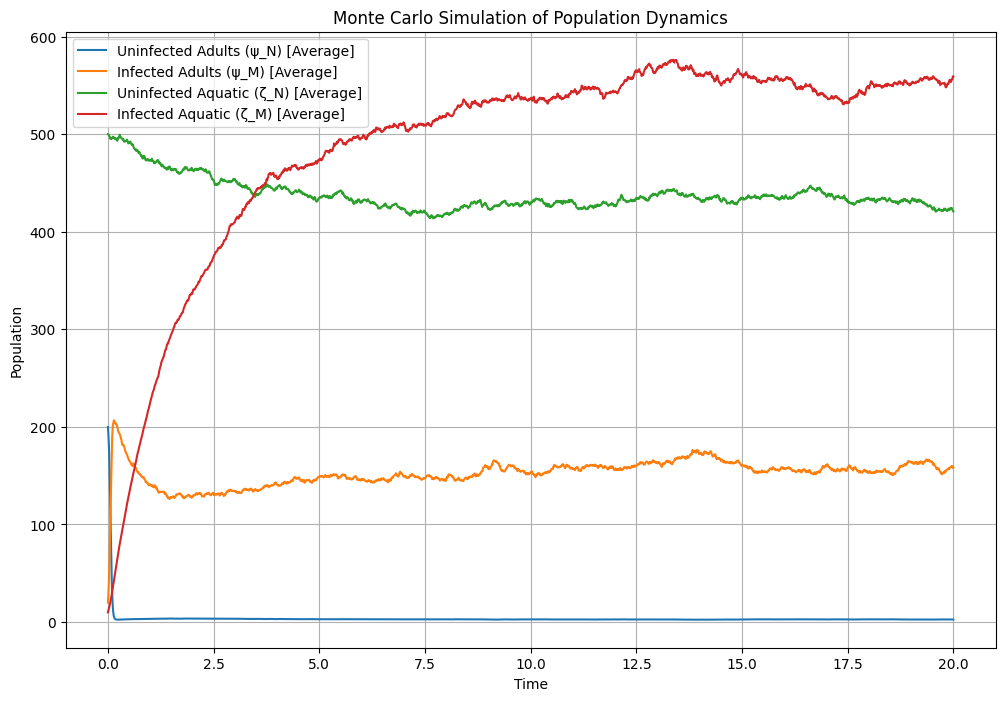

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
tau_N = 200      # Recruitment rate for uninfected aquatic mosquitoes
tau_M = 200      # Recruitment rate for infected aquatic mosquitoes
a_N = 0.30       # Mortality rate of uninfected aquatic mosquitoes
a_M = 0.30       # Mortality rate of infected aquatic mosquitoes
d_N = 0.22       # Mortality rate of uninfected adult mosquitoes
d_M = 0.22       # Mortality rate of infected adult mosquitoes
gamma_N = 0.2    # Maturation rate of uninfected aquatic mosquitoes
gamma_M = 0.2    # Maturation rate of infected aquatic mosquitoes
beta = 0.2       # Probability of uninfected adults becoming infected
theta = 0.7      # Probability of infected adults producing infected aquatic mosquitoes

# Volatility terms
sigma_psi_N = 0.05
sigma_psi_M = 0.05
sigma_zeta_N = 0.02
sigma_zeta_M = 0.02

# Carrying capacities
K_zeta = 1500  # Carrying capacity for aquatic stages
K_psi = 1000   # Carrying capacity for adult stages

T =  20      # Total time
dt = 0.01     # Time step
N = int(T / dt) # Number of time steps
MC_runs = 1  # Number of Monte Carlo runs

# Arrays to store results
psi_N_MC = np.zeros((MC_runs, N))
psi_M_MC = np.zeros((MC_runs, N))
zeta_N_MC = np.zeros((MC_runs, N))
zeta_M_MC = np.zeros((MC_runs, N))

# Monte Carlo simulation
for run in range(MC_runs):
    # Initial conditions for each run
    psi_N = np.zeros(N)
    psi_M = np.zeros(N)
    zeta_N = np.zeros(N)
    zeta_M = np.zeros(N)

    psi_N[0] = 200  # Initial uninfected adults
    psi_M[0] = 20   # Initial infected adults
    zeta_N[0] = 500  # Initial uninfected aquatic
    zeta_M[0] = 10   # Initial infected aquatic

    # Stochastic Milstein method
    for t in range(1, N):
        dB_psi_N = np.sqrt(dt) * np.random.normal()
        dB_psi_M = np.sqrt(dt) * np.random.normal()
        dB_zeta_N = np.sqrt(dt) * np.random.normal()
        dB_zeta_M = np.sqrt(dt) * np.random.normal()

        # Aquatic phases
        d_zeta_N = (tau_N * (1 - (psi_N[t-1] + psi_M[t-1]) / K_psi) + (1 - theta) * psi_M[t-1]
                    - a_N * zeta_N[t-1] - gamma_N * zeta_N[t-1])
        d_zeta_M = (tau_M * (1 - (psi_N[t-1] + psi_M[t-1]) / K_psi) + theta * psi_M[t-1]
                    - a_M * zeta_M[t-1] - gamma_M * zeta_M[t-1])

        # Adult phases
        d_psi_N = (gamma_N * zeta_N[t-1]
                   - beta * psi_N[t-1] * psi_M[t-1] - d_N * psi_N[t-1])
        d_psi_M = (gamma_M * zeta_M[t-1]
                   + beta * psi_N[t-1] * psi_M[t-1] - (1+d_M )* psi_M[t-1])

        # Update with stochastic terms
        zeta_N[t] = zeta_N[t-1] + d_zeta_N * dt + sigma_zeta_N * zeta_N[t-1] * dB_zeta_N
        zeta_M[t] = zeta_M[t-1] + d_zeta_M * dt + sigma_zeta_M * zeta_M[t-1] * dB_zeta_M
        psi_N[t] = psi_N[t-1] + d_psi_N * dt + sigma_psi_N * psi_N[t-1] * dB_psi_N
        psi_M[t] = psi_M[t-1] + d_psi_M * dt + sigma_psi_M * psi_M[t-1] * dB_psi_M

        # Ensure non-negativity
        zeta_N[t] = max(0, zeta_N[t])
        zeta_M[t] = max(0, zeta_M[t])
        psi_N[t] = max(0, psi_N[t])
        psi_M[t] = max(0, psi_M[t])

    # Store results
    psi_N_MC[run] = psi_N
    psi_M_MC[run] = psi_M
    zeta_N_MC[run] = zeta_N
    zeta_M_MC[run] = zeta_M

# Compute averages across Monte Carlo runs
avg_psi_N = np.mean(psi_N_MC, axis=0)
avg_psi_M = np.mean(psi_M_MC, axis=0)
avg_zeta_N = np.mean(zeta_N_MC, axis=0)
avg_zeta_M = np.mean(zeta_M_MC, axis=0)

# Plot results
time = np.linspace(0, T, N)

plt.figure(figsize=(12, 8))
plt.plot(time, avg_psi_N, label="Uninfected Adults (\u03C8_N) [Average]")
plt.plot(time, avg_psi_M, label="Infected Adults (\u03C8_M) [Average]")
plt.plot(time, avg_zeta_N, label="Uninfected Aquatic (\u03B6_N) [Average]")
plt.plot(time, avg_zeta_M, label="Infected Aquatic (\u03B6_M) [Average]")

plt.title("Monte Carlo Simulation of Population Dynamics")
plt.xlabel("Time")
plt.ylabel("Population")
plt.legend()
plt.grid()
plt.show()


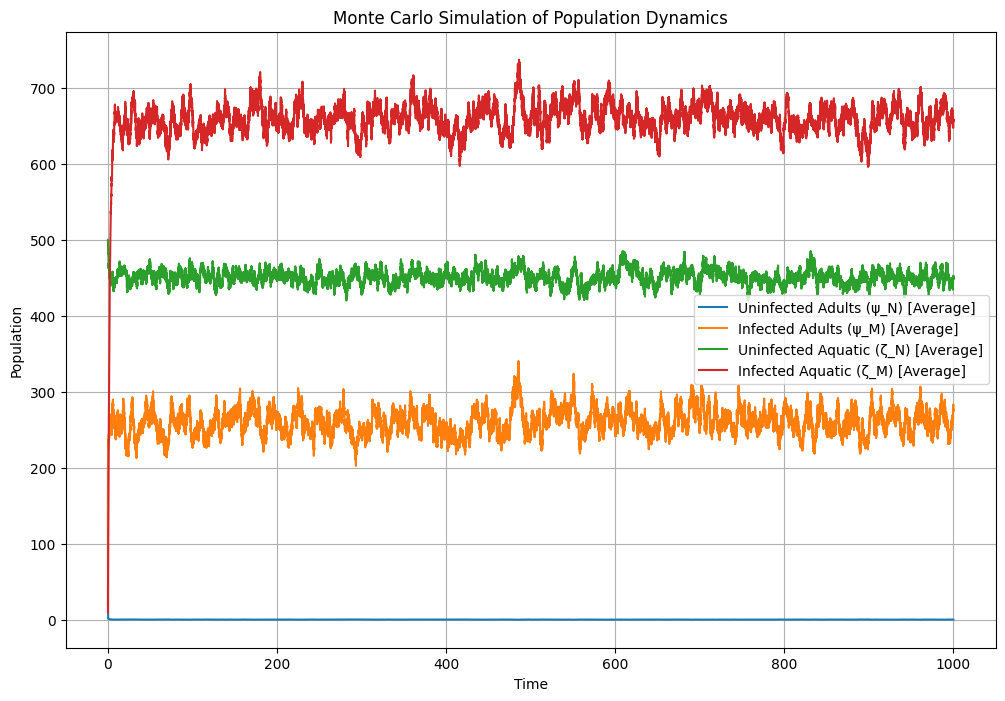

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
tau_N = 200      # Recruitment rate for uninfected aquatic mosquitoes
tau_M = 200      # Recruitment rate for infected aquatic mosquitoes
a_N = 0.30       # Mortality rate of uninfected aquatic mosquitoes
a_M = 0.30       # Mortality rate of infected aquatic mosquitoes
d_N = 0.22       # Mortality rate of uninfected adult mosquitoes
d_M = 0.22       # Mortality rate of infected adult mosquitoes
gamma_N = 0.2    # Maturation rate of uninfected aquatic mosquitoes
gamma_M = 0.2    # Maturation rate of infected aquatic mosquitoes
beta = 0.2       # Probability of uninfected adults becoming infected
theta = 0.7      # Probability of infected adults producing infected aquatic mosquitoes

# Volatility terms
sigma_psi_N = 0.05
sigma_psi_M = 0.05
sigma_zeta_N = 0.02
sigma_zeta_M = 0.02

# Carrying capacities
K_zeta = 1500  # Carrying capacity for aquatic stages
K_psi = 1000   # Carrying capacity for adult stages

T =  1000     # Total time
dt = 0.01     # Time step
N = int(T / dt) # Number of time steps
MC_runs = 1  # Number of Monte Carlo runs

# Arrays to store results
psi_N_MC = np.zeros((MC_runs, N))
psi_M_MC = np.zeros((MC_runs, N))
zeta_N_MC = np.zeros((MC_runs, N))
zeta_M_MC = np.zeros((MC_runs, N))

# Monte Carlo simulation
for run in range(MC_runs):
    # Initial conditions for each run
    psi_N = np.zeros(N)
    psi_M = np.zeros(N)
    zeta_N = np.zeros(N)
    zeta_M = np.zeros(N)

    psi_N[0] = 200  # Initial uninfected adults
    psi_M[0] = 20   # Initial infected adults
    zeta_N[0] = 500  # Initial uninfected aquatic
    zeta_M[0] = 10   # Initial infected aquatic

    # Stochastic Milstein method
    for t in range(1, N):
        dB_psi_N = np.sqrt(dt) * np.random.normal()
        dB_psi_M = np.sqrt(dt) * np.random.normal()
        dB_zeta_N = np.sqrt(dt) * np.random.normal()
        dB_zeta_M = np.sqrt(dt) * np.random.normal()

        # Aquatic phases
        d_zeta_N = (tau_N * (1 - (psi_N[t-1] + psi_M[t-1]) / K_psi) + (1 - theta) * psi_M[t-1]
                    - a_N * zeta_N[t-1] - gamma_N * zeta_N[t-1])
        d_zeta_M = (tau_M * (1 - (psi_N[t-1] + psi_M[t-1]) / K_psi) + theta * psi_M[t-1]
                    - a_M * zeta_M[t-1] - gamma_M * zeta_M[t-1])

        # Adult phases
        d_psi_N = (gamma_N * zeta_N[t-1] * (1 - (zeta_N[t-1] + zeta_M[t-1]) / K_zeta)
                   - beta * psi_N[t-1] * psi_M[t-1]*(1 - (psi_N[t-1] + psi_M[t-1]) / K_psi) - d_N * psi_N[t-1])
        d_psi_M = (gamma_M * zeta_M[t-1] * (1 - (zeta_N[t-1] + zeta_M[t-1]) / K_zeta)
                   + beta * psi_N[t-1] * psi_M[t-1]*(1 - (psi_N[t-1] + psi_M[t-1]) / K_psi) - d_M * psi_M[t-1])

        # Update with stochastic terms
        zeta_N[t] = zeta_N[t-1] + d_zeta_N * dt + sigma_zeta_N * zeta_N[t-1] * dB_zeta_N
        zeta_M[t] = zeta_M[t-1] + d_zeta_M * dt + sigma_zeta_M * zeta_M[t-1] * dB_zeta_M
        psi_N[t] = psi_N[t-1] + d_psi_N * dt + sigma_psi_N * psi_N[t-1] * dB_psi_N
        psi_M[t] = psi_M[t-1] + d_psi_M * dt + sigma_psi_M * psi_M[t-1] * dB_psi_M

        # Ensure non-negativity
        zeta_N[t] = max(0, zeta_N[t])
        zeta_M[t] = max(0, zeta_M[t])
        psi_N[t] = max(0, psi_N[t])
        psi_M[t] = max(0, psi_M[t])

    # Store results
    psi_N_MC[run] = psi_N
    psi_M_MC[run] = psi_M
    zeta_N_MC[run] = zeta_N
    zeta_M_MC[run] = zeta_M

# Compute averages across Monte Carlo runs
avg_psi_N = np.mean(psi_N_MC, axis=0)
avg_psi_M = np.mean(psi_M_MC, axis=0)
avg_zeta_N = np.mean(zeta_N_MC, axis=0)
avg_zeta_M = np.mean(zeta_M_MC, axis=0)

# Plot results
time = np.linspace(0, T, N)

plt.figure(figsize=(12, 8))
plt.plot(time, avg_psi_N, label="Uninfected Adults (\u03C8_N) [Average]")
plt.plot(time, avg_psi_M, label="Infected Adults (\u03C8_M) [Average]")
plt.plot(time, avg_zeta_N, label="Uninfected Aquatic (\u03B6_N) [Average]")
plt.plot(time, avg_zeta_M, label="Infected Aquatic (\u03B6_M) [Average]")

plt.title("Monte Carlo Simulation of Population Dynamics")
plt.xlabel("Time")
plt.ylabel("Population")
plt.legend()
plt.grid()
plt.show()


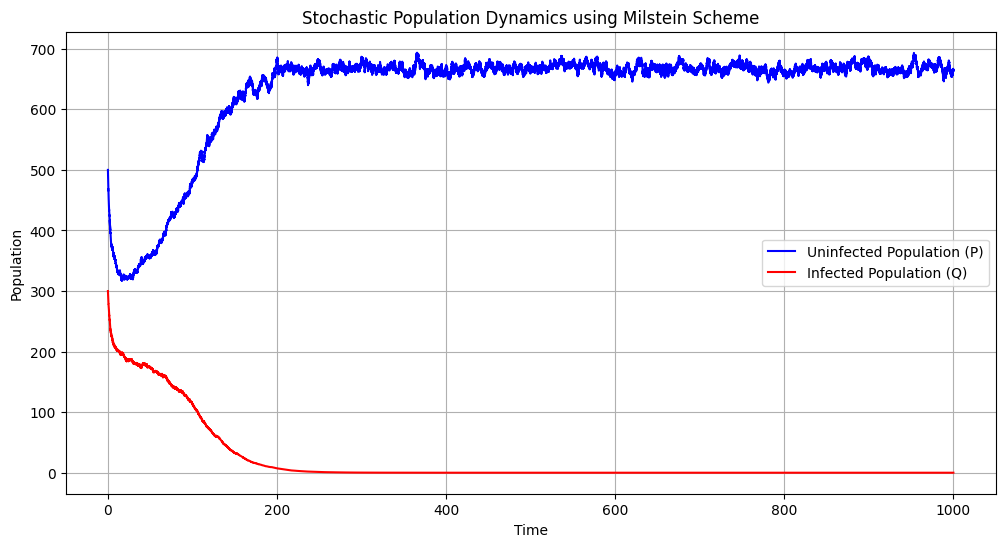

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Seed for reproducibility
np.random.seed(42)

# Parameters
K = 1000  # Constant carrying capacity
rho_11 = 0.6
rho_12 = 0.1
rho_21 = 0.5
rho_22 = 0.25
lambda_P = 0.2
lambda_Q = 0.2
sigma_P = 0.01
sigma_Q = 0.01

# Time parameters
T = 1000 # Total time
dt = 0.01  # Time step
N = int(T / dt)  # Number of steps

# Initialize populations
P0 = 500
Q0 = 300
P = np.zeros(N)
Q = np.zeros(N)
P[0] = P0
Q[0] = Q0

# Milstein discretization scheme
for t in range(1, N):
    dW_P = np.random.normal(0, np.sqrt(dt))  # Wiener increment for P
    dW_Q = np.random.normal(0, np.sqrt(dt))  # Wiener increment for Q

    # Drift terms
    drift_P = (
        (rho_11 * P[t - 1] + rho_12 * Q[t - 1]) * P[t - 1] / (P[t - 1] + Q[t - 1])
        * (1 - (P[t - 1] + Q[t - 1]) / K)
        - lambda_P * P[t - 1]
    )
    drift_Q = (
        (rho_21 * P[t - 1] + rho_22 * Q[t - 1]) * Q[t - 1] / (P[t - 1] + Q[t - 1])
        * (1 - (P[t - 1] + Q[t - 1]) / K)
        - lambda_Q * Q[t - 1]
    )

    # Diffusion terms
    diffusion_P = sigma_P * P[t - 1]
    diffusion_Q = sigma_Q * Q[t - 1]

    # Milstein scheme
    P[t] = P[t - 1] + drift_P * dt + diffusion_P * dW_P + 0.5 * sigma_P**2 * P[t - 1] * (dW_P**2 - dt)
    Q[t] = Q[t - 1] + drift_Q * dt + diffusion_Q * dW_Q + 0.5 * sigma_Q**2 * Q[t - 1] * (dW_Q**2 - dt)

    # Ensure populations remain non-negative
    P[t] = max(P[t], 0)
    Q[t] = max(Q[t], 0)

# Plotting results
time = np.linspace(0, T, N)

plt.figure(figsize=(12, 6))
plt.plot(time, P, label="Uninfected Population (P)", color="blue")
plt.plot(time, Q, label="Infected Population (Q)", color="red")
plt.title("Stochastic Population Dynamics using Milstein Scheme")
plt.xlabel("Time")
plt.ylabel("Population")
plt.legend()
plt.grid()
plt.show()


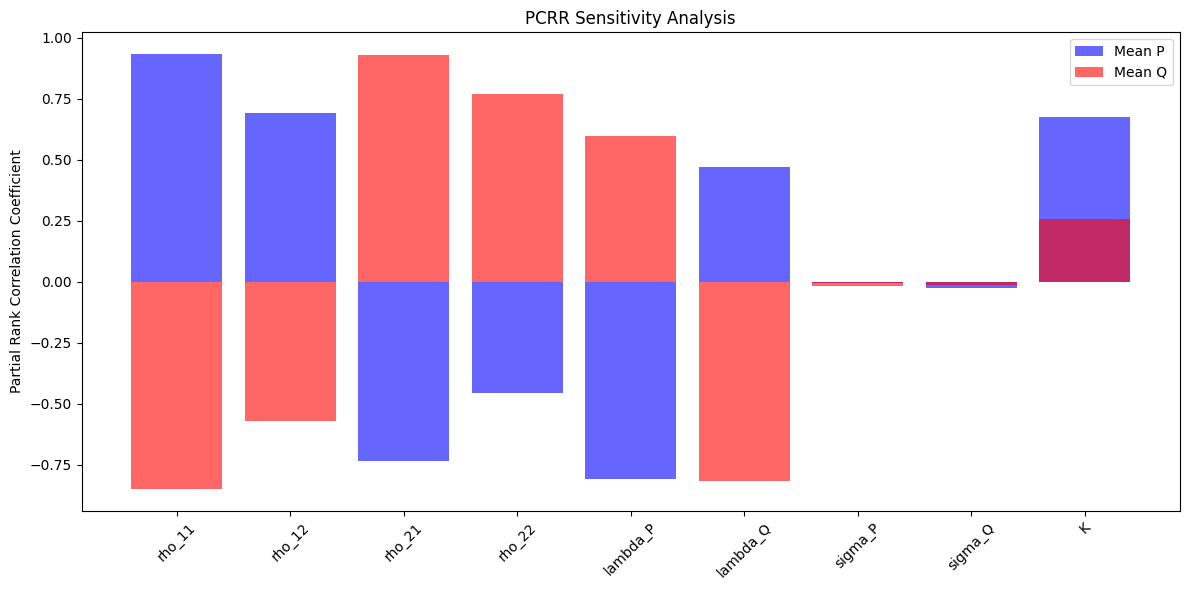

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression

# Set random seed for reproducibility
np.random.seed(42)

# Parameters for Monte Carlo Sampling
N = 1000  # Number of Monte Carlo samples
T = 100  # Total simulation time
dt = 0.01  # Time step
time_steps = int(T / dt)

# Parameter ranges
rho_11_range = [0.05, 0.15]
rho_12_range = [0.01, 0.1]
rho_21_range = [0.01, 0.1]
rho_22_range = [0.05, 0.15]
lambda_P_range = [0.01, 0.03]
lambda_Q_range = [0.01, 0.03]
sigma_P_range = [0.005, 0.02]
sigma_Q_range = [0.005, 0.02]
K_range = [800, 1200]

# Generate random parameter samples (Latin Hypercube Sampling can be added)
param_samples = np.random.uniform(
    low=[rho_11_range[0], rho_12_range[0], rho_21_range[0], rho_22_range[0],
         lambda_P_range[0], lambda_Q_range[0], sigma_P_range[0], sigma_Q_range[0], K_range[0]],
    high=[rho_11_range[1], rho_12_range[1], rho_21_range[1], rho_22_range[1],
          lambda_P_range[1], lambda_Q_range[1], sigma_P_range[1], sigma_Q_range[1], K_range[1]],
    size=(N, 9)
)

# Arrays to store results
mean_P = np.zeros(N)
mean_Q = np.zeros(N)

# Milstein Scheme Simulation
def simulate_stochastic_dynamics(params, time_steps, dt):
    rho_11, rho_12, rho_21, rho_22, lambda_P, lambda_Q, sigma_P, sigma_Q, K = params

    # Initialize populations
    P = np.zeros(time_steps)
    Q = np.zeros(time_steps)
    P[0] = 100  # Initial value for P
    Q[0] = 50   # Initial value for Q

    for t in range(1, time_steps):
        P_total = P[t-1] + Q[t-1]
        dW_P = np.random.normal(0, np.sqrt(dt))
        dW_Q = np.random.normal(0, np.sqrt(dt))

        # Dynamics of P
        growth_P = (rho_11 * P[t-1] + rho_12 * Q[t-1]) * (P[t-1] / P_total) * (1 - P_total / K)
        death_P = lambda_P * P[t-1]
        stochastic_P = sigma_P * P[t-1] * dW_P
        P[t] = max(P[t-1] + dt * (growth_P - death_P) + stochastic_P, 0)

        # Dynamics of Q
        growth_Q = (rho_21 * P[t-1] + rho_22 * Q[t-1]) * (Q[t-1] / P_total) * (1 - P_total / K)
        death_Q = lambda_Q * Q[t-1]
        stochastic_Q = sigma_Q * Q[t-1] * dW_Q
        Q[t] = max(Q[t-1] + dt * (growth_Q - death_Q) + stochastic_Q, 0)

    return P, Q

# Monte Carlo Simulations
for i, params in enumerate(param_samples):
    P, Q = simulate_stochastic_dynamics(params, time_steps, dt)
    mean_P[i] = np.mean(P)
    mean_Q[i] = np.mean(Q)

# Rank Inputs and Outputs
param_ranks = np.argsort(np.argsort(param_samples, axis=0), axis=0)
mean_P_ranks = np.argsort(np.argsort(mean_P))
mean_Q_ranks = np.argsort(np.argsort(mean_Q))

# PCRR Sensitivity Analysis for P
pccs_P = []
for i in range(param_samples.shape[1]):
    X = np.delete(param_ranks, i, axis=1)  # Remove current parameter
    y = param_ranks[:, i]  # Current parameter rank
    residual_y = y - LinearRegression().fit(X, y).predict(X)
    residual_output = mean_P_ranks - LinearRegression().fit(X, mean_P_ranks).predict(X)
    pccs_P.append(spearmanr(residual_y, residual_output).correlation)

# PCRR Sensitivity Analysis for Q
pccs_Q = []
for i in range(param_samples.shape[1]):
    X = np.delete(param_ranks, i, axis=1)  # Remove current parameter
    y = param_ranks[:, i]  # Current parameter rank
    residual_y = y - LinearRegression().fit(X, y).predict(X)
    residual_output = mean_Q_ranks - LinearRegression().fit(X, mean_Q_ranks).predict(X)
    pccs_Q.append(spearmanr(residual_y, residual_output).correlation)

# Plot Results
param_names = ["rho_11", "rho_12", "rho_21", "rho_22", "lambda_P", "lambda_Q", "sigma_P", "sigma_Q", "K"]

plt.figure(figsize=(12, 6))
plt.bar(param_names, pccs_P, color='b', alpha=0.6, label='Mean P')
plt.bar(param_names, pccs_Q, color='r', alpha=0.6, label='Mean Q')
plt.title("PCRR Sensitivity Analysis")
plt.ylabel("Partial Rank Correlation Coefficient")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


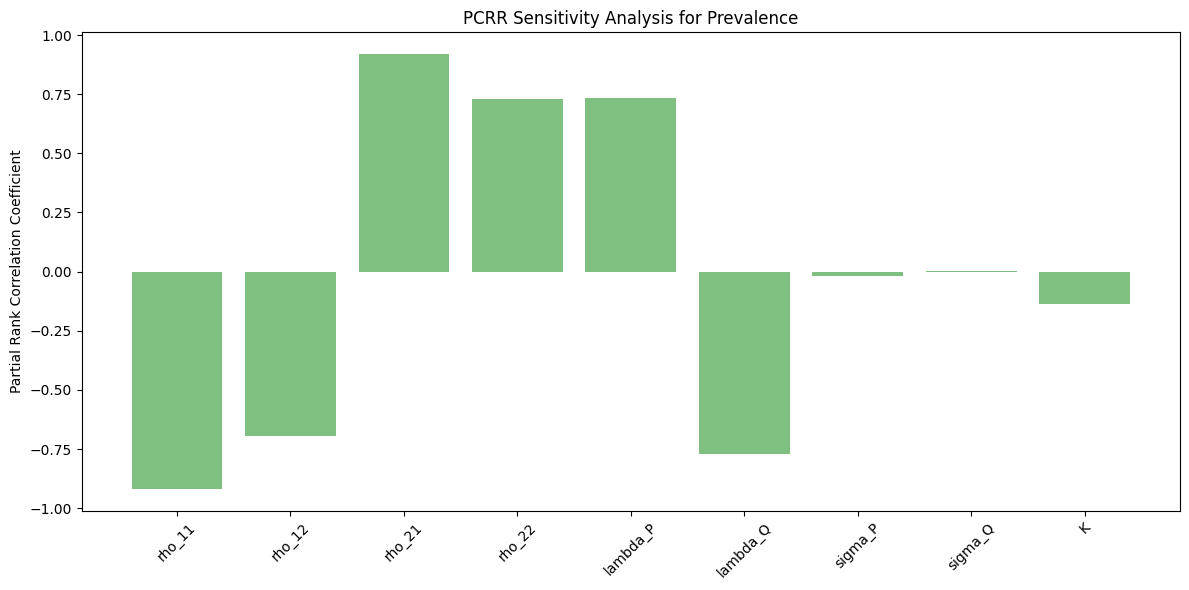

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression

# Set random seed for reproducibility
np.random.seed(42)

# Parameters for Monte Carlo Sampling
N = 1000  # Number of Monte Carlo samples
T = 100  # Total simulation time
dt = 0.01  # Time step
time_steps = int(T / dt)

# Parameter ranges
rho_11_range = [0.05, 0.15]
rho_12_range = [0.01, 0.1]
rho_21_range = [0.01, 0.1]
rho_22_range = [0.05, 0.15]
lambda_P_range = [0.01, 0.03]
lambda_Q_range = [0.01, 0.03]
sigma_P_range = [0.005, 0.02]
sigma_Q_range = [0.005, 0.02]
K_range = [800, 1200]

# Generate random parameter samples
param_samples = np.random.uniform(
    low=[rho_11_range[0], rho_12_range[0], rho_21_range[0], rho_22_range[0],
         lambda_P_range[0], lambda_Q_range[0], sigma_P_range[0], sigma_Q_range[0], K_range[0]],
    high=[rho_11_range[1], rho_12_range[1], rho_21_range[1], rho_22_range[1],
          lambda_P_range[1], lambda_Q_range[1], sigma_P_range[1], sigma_Q_range[1], K_range[1]],
    size=(N, 9)
)

# Arrays to store results
mean_prevalence = np.zeros(N)

# Milstein Scheme Simulation
def simulate_stochastic_dynamics(params, time_steps, dt):
    rho_11, rho_12, rho_21, rho_22, lambda_P, lambda_Q, sigma_P, sigma_Q, K = params

    # Initialize populations
    P = np.zeros(time_steps)
    Q = np.zeros(time_steps)
    P[0] = 100  # Initial value for P
    Q[0] = 50   # Initial value for Q

    for t in range(1, time_steps):
        P_total = P[t-1] + Q[t-1]
        dW_P = np.random.normal(0, np.sqrt(dt))
        dW_Q = np.random.normal(0, np.sqrt(dt))

        # Dynamics of P
        growth_P = (rho_11 * P[t-1] + rho_12 * Q[t-1]) * (P[t-1] / P_total) * (1 - P_total / K)
        death_P = lambda_P * P[t-1]
        stochastic_P = sigma_P * P[t-1] * dW_P
        P[t] = max(P[t-1] + dt * (growth_P - death_P) + stochastic_P, 0)

        # Dynamics of Q
        growth_Q = (rho_21 * P[t-1] + rho_22 * Q[t-1]) * (Q[t-1] / P_total) * (1 - P_total / K)
        death_Q = lambda_Q * Q[t-1]
        stochastic_Q = sigma_Q * Q[t-1] * dW_Q
        Q[t] = max(Q[t-1] + dt * (growth_Q - death_Q) + stochastic_Q, 0)

    return P, Q

# Monte Carlo Simulations
for i, params in enumerate(param_samples):
    P, Q = simulate_stochastic_dynamics(params, time_steps, dt)
    prevalence = Q / (P + Q)  # Compute prevalence at each time step
    mean_prevalence[i] = np.mean(prevalence)  # Store mean prevalence for this parameter set

# Rank Inputs and Outputs
param_ranks = np.argsort(np.argsort(param_samples, axis=0), axis=0)
mean_prevalence_ranks = np.argsort(np.argsort(mean_prevalence))

# PCRR Sensitivity Analysis for Prevalence
pccs_prevalence = []
for i in range(param_samples.shape[1]):
    X = np.delete(param_ranks, i, axis=1)  # Remove current parameter
    y = param_ranks[:, i]  # Current parameter rank
    residual_y = y - LinearRegression().fit(X, y).predict(X)
    residual_output = mean_prevalence_ranks - LinearRegression().fit(X, mean_prevalence_ranks).predict(X)
    pccs_prevalence.append(spearmanr(residual_y, residual_output).correlation)

# Plot Results
param_names = ["rho_11", "rho_12", "rho_21", "rho_22", "lambda_P", "lambda_Q", "sigma_P", "sigma_Q", "K"]

plt.figure(figsize=(12, 6))
plt.bar(param_names, pccs_prevalence, color='g', alpha=0.5)
plt.title("PCRR Sensitivity Analysis for Prevalence")
plt.ylabel("Partial Rank Correlation Coefficient")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


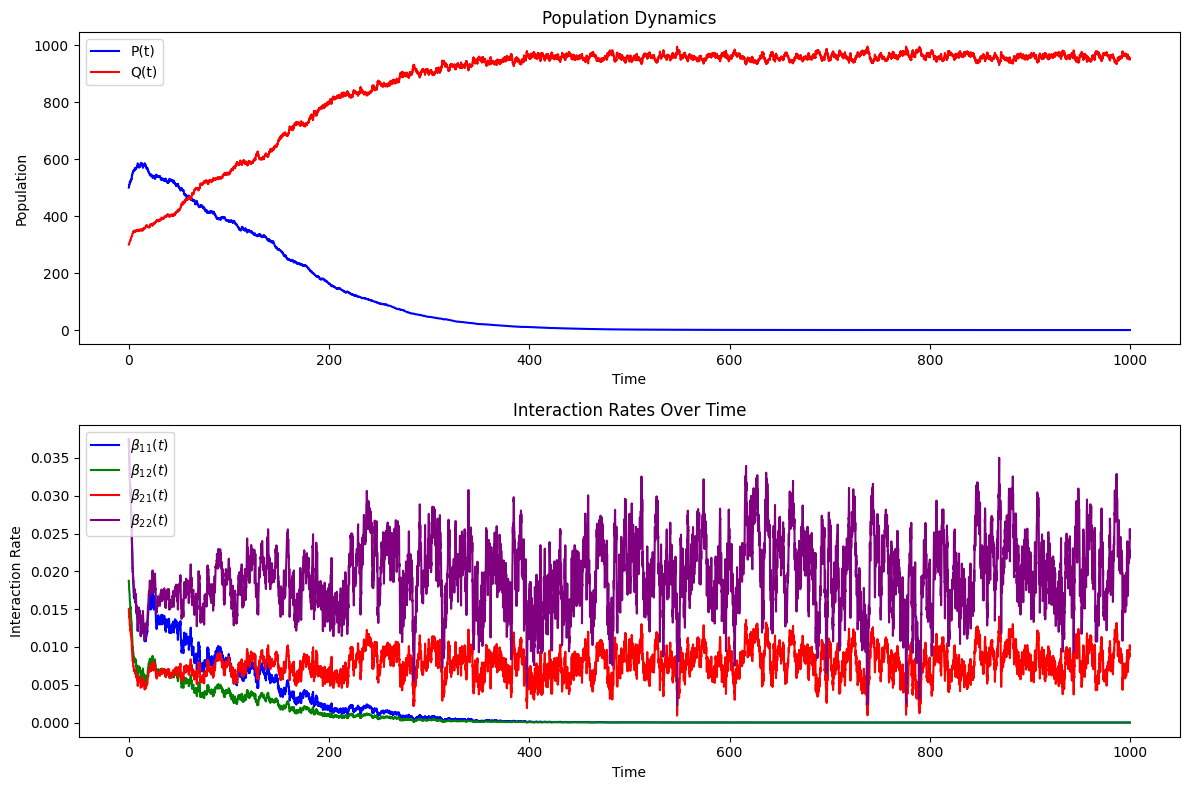

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
rho_11 = 0.3  # Interaction coefficient for P-P
rho_12 = 0.15  # Interaction coefficient for P-Q
rho_21 = 0.2  # Interaction coefficient for Q-P
rho_22 = 0.5  # Interaction coefficient for Q-Q
K = 1000  # Carrying capacity
lambda_P = 0.02  # Death rate for P
lambda_Q = 0.02  # Death rate for Q
sigma_P = 0.01  # Noise intensity for P
sigma_Q = 0.01  # Noise intensity for Q
T = 1000  # Total time
dt = 0.1  # Time step
N = int(T / dt)  # Number of steps

# Initial conditions
P0 = 500  # Initial population of P
Q0 = 300   # Initial population of Q

# Arrays to store results
P = np.zeros(N)
Q = np.zeros(N)
time = np.linspace(0, T, N)

# Initial populations
P[0] = P0
Q[0] = Q0

# Milstein method simulation
for t in range(1, N):
    P_total = P[t-1] + Q[t-1]
    dW_P = np.random.normal(0, np.sqrt(dt))
    dW_Q = np.random.normal(0, np.sqrt(dt))

    # Dynamics of P
    growth_P = (rho_11 * P[t-1] + rho_12 * Q[t-1]) * (P[t-1] / P_total) * (1 - P_total / K)
    death_P = lambda_P * P[t-1]
    stochastic_P = sigma_P * P[t-1] * dW_P
    P[t] = P[t-1] + dt * (growth_P - death_P) + stochastic_P + 0.5 * sigma_P * P[t-1] * (dW_P**2 - dt)

    # Dynamics of Q
    growth_Q = (rho_21 * P[t-1] + rho_22 * Q[t-1]) * (Q[t-1] / P_total) * (1 - P_total / K)
    death_Q = lambda_Q * Q[t-1]
    stochastic_Q = sigma_Q * Q[t-1] * dW_Q
    Q[t] = Q[t-1] + dt * (growth_Q - death_Q) + stochastic_Q + 0.5 * sigma_Q * Q[t-1] * (dW_Q**2 - dt)

# Calculate interaction rates
beta_11 = rho_11 * (P / (P + Q)) * (1 - (P + Q) / K)
beta_12 = rho_12 * (P / (P + Q)) * (1 - (P + Q) / K)
beta_21 = rho_21 * (Q / (P + Q)) * (1 - (P + Q) / K)
beta_22 = rho_22 * (Q / (P + Q)) * (1 - (P + Q) / K)

# Plotting
plt.figure(figsize=(12, 8))

# Plot populations
plt.subplot(2, 1, 1)
plt.plot(time, P, label='P(t)', color='blue')
plt.plot(time, Q, label='Q(t)', color='red')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Population Dynamics')
plt.legend()

# Plot interaction rates
plt.subplot(2, 1, 2)
plt.plot(time, beta_11, label=r'$\beta_{11}(t)$', color='blue')
plt.plot(time, beta_12, label=r'$\beta_{12}(t)$', color='green')
plt.plot(time, beta_21, label=r'$\beta_{21}(t)$', color='red')
plt.plot(time, beta_22, label=r'$\beta_{22}(t)$', color='purple')
plt.xlabel('Time')
plt.ylabel('Interaction Rate')
plt.title('Interaction Rates Over Time')
plt.legend()

plt.tight_layout()
plt.show()


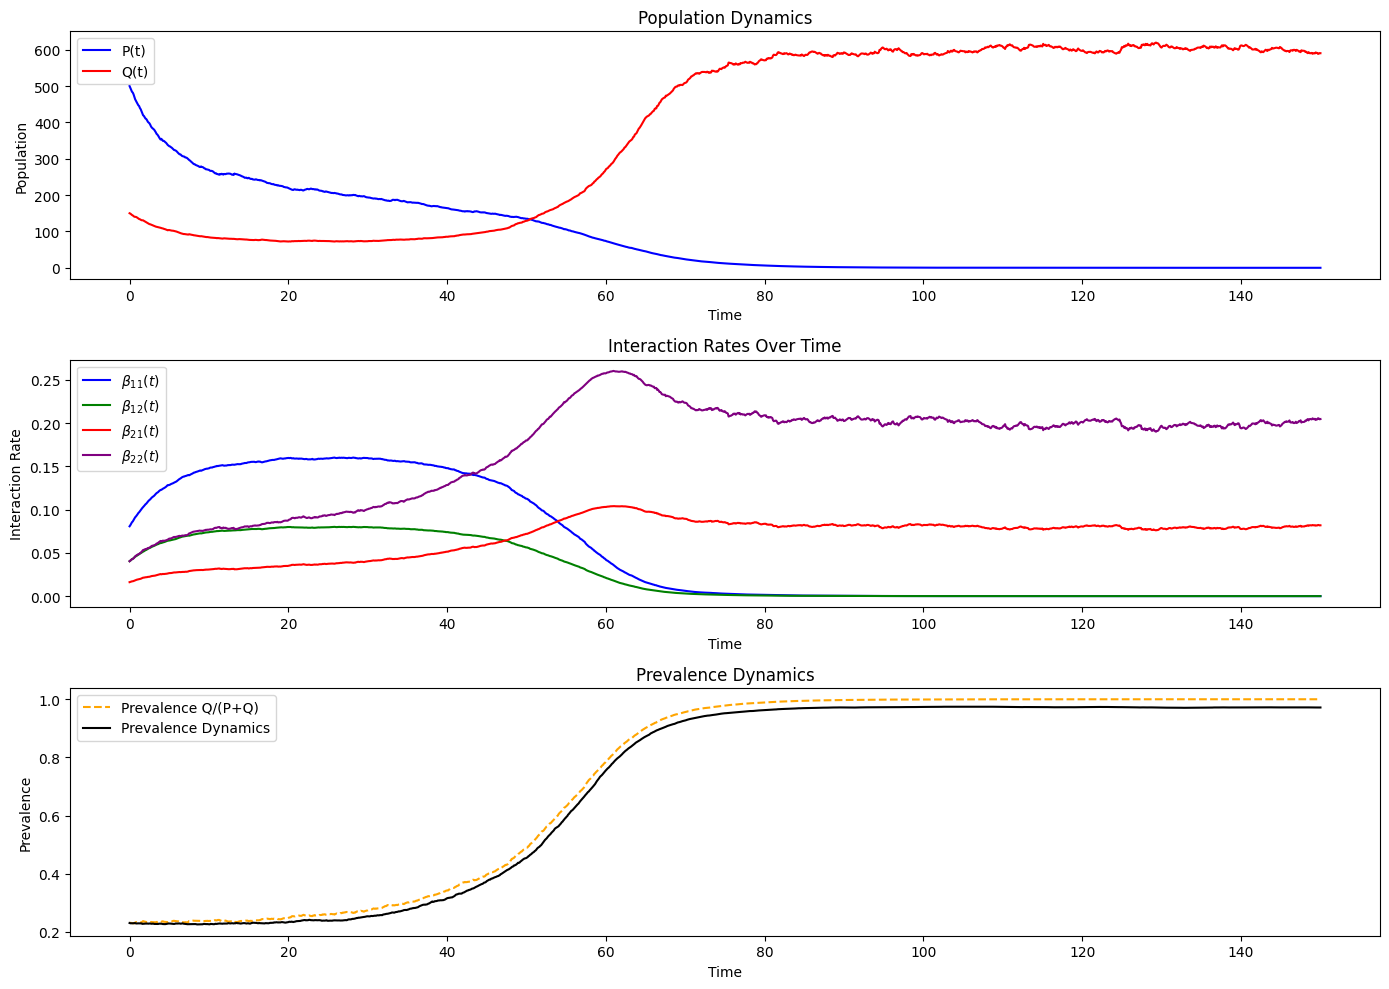

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
rho_11 = 0.3  # Interaction coefficient for P-P
rho_12 = 0.15  # Interaction coefficient for P-Q
rho_21 = 0.2  # Interaction coefficient for Q-P
rho_22 = 0.5  # Interaction coefficient for Q-Q
K = 1000  # Carrying capacity
lambda_P = 0.2  # Death rate for P
lambda_Q = 0.2  # Death rate for Q
sigma_P = 0.01  # Noise intensity for P
sigma_Q = 0.01  # Noise intensity for Q
gamma_P = 0.5  # Parameter for P
gamma_Q = 0.5  # Parameter for Q
sigma = 0.01  # Noise intensity for prevalence
T = 150  # Total time
dt = 0.1  # Time step
N = int(T / dt)  # Number of steps

# Initial conditions
P0 = 500  # Initial population of P
Q0 = 150  # Initial population of Q

# Arrays to store results
P = np.zeros(N)
Q = np.zeros(N)
time = np.linspace(0, T, N)
P[0] = P0
Q[0] = Q0

# Milstein method simulation
for t in range(1, N):
    S = P[t-1] + Q[t-1]  # Total population
    dW_P = np.random.normal(0, np.sqrt(dt))
    dW_Q = np.random.normal(0, np.sqrt(dt))

    # Dynamics of P
    growth_P = (rho_11 * P[t-1] + rho_12 * Q[t-1]) * (P[t-1] / S) * (1 - S / K)
    death_P = lambda_P * P[t-1]
    stochastic_P = sigma_P * P[t-1] * dW_P
    P[t] = P[t-1] + dt * (growth_P - death_P) + stochastic_P + 0.5 * sigma_P * P[t-1] * (dW_P**2 - dt)

    # Dynamics of Q
    growth_Q = (rho_21 * P[t-1] + rho_22 * Q[t-1]) * (Q[t-1] / S) * (1 - S / K)
    death_Q = lambda_Q * Q[t-1]
    stochastic_Q = sigma_Q * Q[t-1] * dW_Q
    Q[t] = Q[t-1] + dt * (growth_Q - death_Q) + stochastic_Q + 0.5 * sigma_Q * Q[t-1] * (dW_Q**2 - dt)

# Calculate interaction rates
beta_11 = rho_11 * (P / (P + Q)) * (1 - (P + Q) / K)
beta_12 = rho_12 * (P / (P + Q)) * (1 - (P + Q) / K)
beta_21 = rho_21 * (Q / (P + Q)) * (1 - (P + Q) / K)
beta_22 = rho_22 * (Q / (P + Q)) * (1 - (P + Q) / K)

# Calculate prevalence \mathcal{P}(t)
prevalence = Q / (P + Q)

# Dynamics of prevalence
prevalence_dynamics = np.zeros(N)
prevalence_dynamics[0] = prevalence[0]

for t in range(1, N):
    S = P[t] + Q[t]
    b_P = ((rho_11 * P[t] + rho_12 * Q[t]) / S) * P[t] * (1 - S / K) - lambda_P * P[t]
    b_Q = ((rho_21 * P[t] + rho_22 * Q[t]) / S) * Q[t] * (1 - S / K) - lambda_Q * Q[t]
    l_PQ = -2 * (sigma_Q**2 * Q[t]**2) / S**2 + (sigma_P**2 * P[t]**2 + sigma_Q**2 * Q[t]**2) * (2 * Q[t]) / S**3

    dp_dt = (
        (b_Q * (1 - prevalence_dynamics[t-1]) - (b_P + b_Q) * prevalence_dynamics[t-1] * (1 - prevalence_dynamics[t-1]) + S * l_PQ) / \
        (S * (1 - prevalence_dynamics[t-1]))
    )
    dW = np.random.normal(0, np.sqrt(dt))
    prevalence_dynamics[t] = (
        prevalence_dynamics[t-1] + dt * dp_dt + \
        sigma * prevalence_dynamics[t-1] * (1 - prevalence_dynamics[t-1]) * dW
    )

# Plotting
plt.figure(figsize=(14, 10))

# Plot populations
plt.subplot(3, 1, 1)
plt.plot(time, P, label='P(t)', color='blue')
plt.plot(time, Q, label='Q(t)', color='red')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Population Dynamics')
plt.legend()

# Plot interaction rates
plt.subplot(3, 1, 2)
plt.plot(time, beta_11, label=r'$\beta_{11}(t)$', color='blue')
plt.plot(time, beta_12, label=r'$\beta_{12}(t)$', color='green')
plt.plot(time, beta_21, label=r'$\beta_{21}(t)$', color='red')
plt.plot(time, beta_22, label=r'$\beta_{22}(t)$', color='purple')
plt.xlabel('Time')
plt.ylabel('Interaction Rate')
plt.title('Interaction Rates Over Time')
plt.legend()

# Plot prevalence
plt.subplot(3, 1, 3)
plt.plot(time, prevalence, label='Prevalence Q/(P+Q)', color='orange', linestyle='--')
plt.plot(time, prevalence_dynamics, label='Prevalence Dynamics', color='black')
plt.xlabel('Time')
plt.ylabel('Prevalence')
plt.title('Prevalence Dynamics')
plt.legend()

plt.tight_layout()
plt.show()


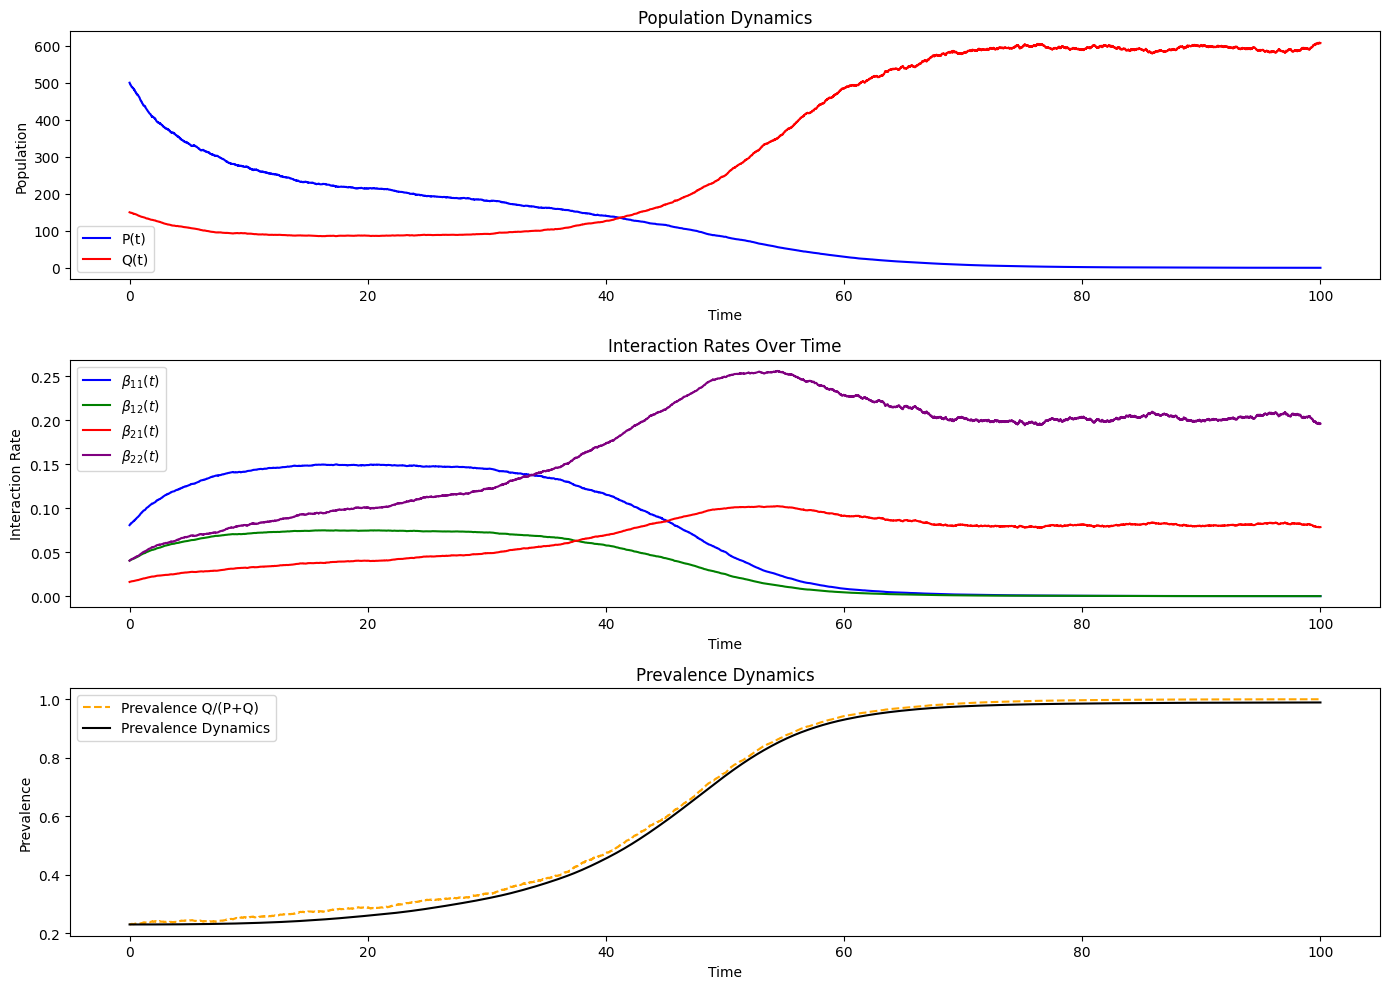

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
rho_11 = 0.3  # Interaction coefficient for P-P
rho_12 = 0.15  # Interaction coefficient for P-Q
rho_21 = 0.2  # Interaction coefficient for Q-P
rho_22 = 0.5  # Interaction coefficient for Q-Q
K = 1000  # Carrying capacity
lambda_P = 0.2  # Death rate for P
lambda_Q = 0.2  # Death rate for Q
sigma_P = 0.01  # Noise intensity for P
sigma_Q = 0.01  # Noise intensity for Q
gamma_P = 0.5  # Parameter for P
gamma_Q = 0.5  # Parameter for Q
sigma = sigma_Q * gamma_Q - sigma_P * gamma_P  # Adjusted noise intensity
T = 100  # Total time
dt = 0.01  # Time step
N = int(T / dt)  # Number of steps

# Initial conditions
P0 = 500  # Initial population of P
Q0 = 150  # Initial population of Q

# Arrays to store results
P = np.zeros(N)
Q = np.zeros(N)
time = np.linspace(0, T, N)
P[0] = P0
Q[0] = Q0

# Milstein method simulation
for t in range(1, N):
    S = P[t-1] + Q[t-1]  # Total population
    dW_P = np.random.normal(0, np.sqrt(dt))
    dW_Q = np.random.normal(0, np.sqrt(dt))

    # Dynamics of P
    growth_P = (rho_11 * P[t-1] + rho_12 * Q[t-1]) * (P[t-1] / S) * (1 - S / K)
    death_P = lambda_P * P[t-1]
    stochastic_P = sigma_P * P[t-1] * dW_P
    P[t] = P[t-1] + dt * (growth_P - death_P) + stochastic_P + 0.5 * sigma_P * P[t-1] * (dW_P**2 - dt)

    # Dynamics of Q
    growth_Q = (rho_21 * P[t-1] + rho_22 * Q[t-1]) * (Q[t-1] / S) * (1 - S / K)
    death_Q = lambda_Q * Q[t-1]
    stochastic_Q = sigma_Q * Q[t-1] * dW_Q
    Q[t] = Q[t-1] + dt * (growth_Q - death_Q) + stochastic_Q + 0.5 * sigma_Q * Q[t-1] * (dW_Q**2 - dt)

# Calculate interaction rates
beta_11 = rho_11 * (P / (P + Q)) * (1 - (P + Q) / K)
beta_12 = rho_12 * (P / (P + Q)) * (1 - (P + Q) / K)
beta_21 = rho_21 * (Q / (P + Q)) * (1 - (P + Q) / K)
beta_22 = rho_22 * (Q / (P + Q)) * (1 - (P + Q) / K)

# Calculate prevalence \mathcal{P}(t)
prevalence = Q / (P + Q)

# Dynamics of prevalence
prevalence_dynamics = np.zeros(N)
prevalence_dynamics[0] = prevalence[0]

for t in range(1, N):
    S = P[t] + Q[t]
    b_P = ((rho_11 * P[t] + rho_12 * Q[t]) / S) * P[t] * (1 - S / K) - lambda_P * P[t]
    b_Q = ((rho_21 * P[t] + rho_22 * Q[t]) / S) * Q[t] * (1 - S / K) - lambda_Q * Q[t]
    l_PQ = -2 * (sigma_Q**2 * Q[t]**2) / S**2 + (sigma_P**2 * P[t]**2 + sigma_Q**2 * Q[t]**2) * (2 * Q[t]) / S**3

    dp_dt = (
        (b_Q * (1 - prevalence_dynamics[t-1]) - (b_P + b_Q) * prevalence_dynamics[t-1] * (1 - prevalence_dynamics[t-1]) + S * l_PQ) / \
        (S * (1 - prevalence_dynamics[t-1]))
    )
    dW = np.random.normal(0, np.sqrt(dt))
    prevalence_dynamics[t] = (
        prevalence_dynamics[t-1] + dt * dp_dt + \
        sigma * prevalence_dynamics[t-1] * (1 - prevalence_dynamics[t-1]) * dW
    )

# Plotting
plt.figure(figsize=(14, 10))

# Plot populations
plt.subplot(3, 1, 1)
plt.plot(time, P, label='P(t)', color='blue')
plt.plot(time, Q, label='Q(t)', color='red')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Population Dynamics')
plt.legend()

# Plot interaction rates
plt.subplot(3, 1, 2)
plt.plot(time, beta_11, label=r'$\beta_{11}(t)$', color='blue')
plt.plot(time, beta_12, label=r'$\beta_{12}(t)$', color='green')
plt.plot(time, beta_21, label=r'$\beta_{21}(t)$', color='red')
plt.plot(time, beta_22, label=r'$\beta_{22}(t)$', color='purple')
plt.xlabel('Time')
plt.ylabel('Interaction Rate')
plt.title('Interaction Rates Over Time')
plt.legend()

# Plot prevalence
plt.subplot(3, 1, 3)
plt.plot(time, prevalence, label='Prevalence Q/(P+Q)', color='orange', linestyle='--')
plt.plot(time, prevalence_dynamics, label='Prevalence Dynamics', color='black')
plt.xlabel('Time')
plt.ylabel('Prevalence')
plt.title('Prevalence Dynamics')
plt.legend()

plt.tight_layout()
plt.show()


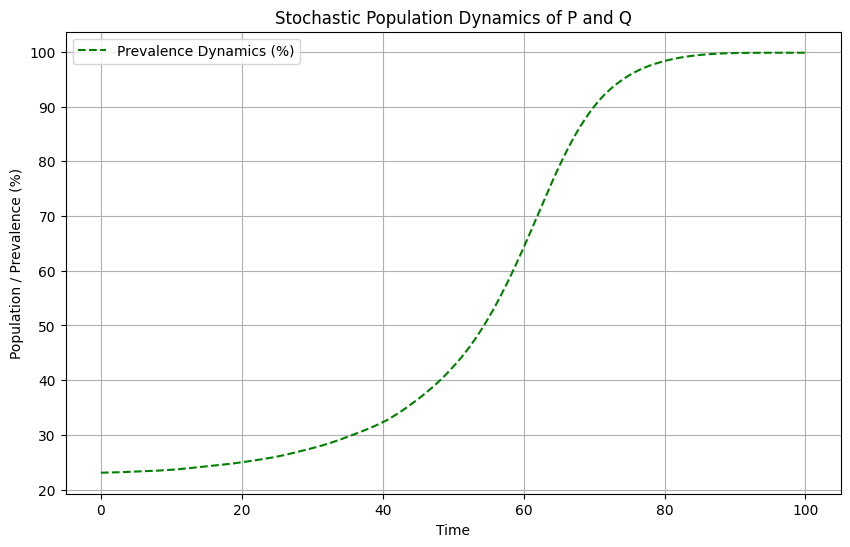

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
rho_11 = 0.3  # Interaction coefficient for P-P
rho_12 = 0.15  # Interaction coefficient for P-Q
rho_21 = 0.2  # Interaction coefficient for Q-P
rho_22 = 0.5  # Interaction coefficient for Q-Q
K = 1000  # Carrying capacity
lambda_P = 0.2  # Death rate for P
lambda_Q = 0.2  # Death rate for Q
sigma_P = 0.01  # Noise intensity for P
sigma_Q = 0.01  # Noise intensity for Q
gamma_P = 0.5
gamma_Q = 0.5
sigma = sigma_Q * gamma_Q - sigma_P * gamma_P  # Adjusted noise intensity

# Simulation parameters
T = 100  # Total time
dt = 0.01  # Time step
N = int(T / dt)  # Number of steps

# Initial conditions
P0 = 500  # Initial population of P
Q0 = 150  # Initial population of Q

# Arrays to store results
P = np.zeros(N)
Q = np.zeros(N)
time = np.linspace(0, T, N)
prevalence_dynamics = np.zeros(N)

# Initial values
P[0] = P0
Q[0] = Q0
prevalence_dynamics[0] = Q0 / (P0 + Q0)

# Simulation loop
for t in range(1, N):
    S = P[t-1] + Q[t-1]

    # Noise
    dW_P = np.random.normal(0, np.sqrt(dt))
    dW_Q = np.random.normal(0, np.sqrt(dt))

    # Dynamics for P
    growth_P = (rho_11 * P[t-1] + rho_12 * Q[t-1]) * (P[t-1] / S) * (1 - S / K)
    death_P = lambda_P * P[t-1]
    stochastic_P = sigma_P * P[t-1] * dW_P
    P[t] = P[t-1] + dt * (growth_P - death_P) + stochastic_P + 0.5 * sigma_P * P[t-1] * (dW_P**2 - dt)

    # Dynamics for Q
    growth_Q = (rho_21 * P[t-1] + rho_22 * Q[t-1]) * (Q[t-1] / S) * (1 - S / K)
    death_Q = lambda_Q * Q[t-1]
    stochastic_Q = sigma_Q * Q[t-1] * dW_Q
    Q[t] = Q[t-1] + dt * (growth_Q - death_Q) + stochastic_Q + 0.5 * sigma_Q * Q[t-1] * (dW_Q**2 - dt)

    # Prevalence dynamics
    l_PQ = -2 * (sigma_Q**2 * Q[t-1]**2) / S**2 + (sigma_P**2 * P[t-1]**2 + sigma_Q**2 * Q[t-1]**2) * (2 * Q[t-1]) / S**3
    b_P = ((rho_11 * P[t-1] + rho_12 * Q[t-1]) / S) * P[t-1] * (1 - S / K) - lambda_P * P[t-1]
    b_Q = ((rho_21 * P[t-1] + rho_22 * Q[t-1]) / S) * Q[t-1] * (1 - S / K) - lambda_Q * Q[t-1]

    dp_dt = (
        (b_Q * (1 - prevalence_dynamics[t-1]) - (b_P + b_Q) * prevalence_dynamics[t-1] * (1 - prevalence_dynamics[t-1]) + S * l_PQ) /
        (S * (1 - prevalence_dynamics[t-1]))
    )
    dW = np.random.normal(0, np.sqrt(dt))
    prevalence_dynamics[t] = prevalence_dynamics[t-1] + dt * dp_dt + sigma * prevalence_dynamics[t-1] * (1 - prevalence_dynamics[t-1]) * dW

# Plot results
plt.figure(figsize=(10, 6))
# plt.plot(time, P, label='Population P', color='blue')
# plt.plot(time, Q, label='Population Q', color='red')
plt.plot(time, prevalence_dynamics * 100, label='Prevalence Dynamics (%)', color='green', linestyle='--')
plt.title("Stochastic Population Dynamics of P and Q")
plt.xlabel("Time")
plt.ylabel("Population / Prevalence (%)")
plt.legend()
plt.grid()
plt.show()


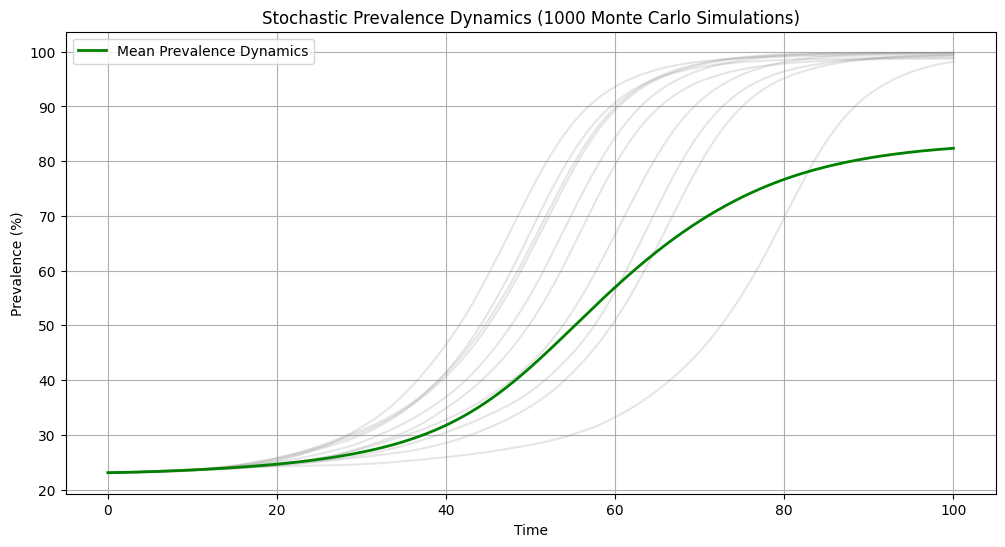

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
rho_11 = 0.3  # Interaction coefficient for P-P
rho_12 = 0.15  # Interaction coefficient for P-Q
rho_21 = 0.2  # Interaction coefficient for Q-P
rho_22 = 0.5  # Interaction coefficient for Q-Q
K = 1000  # Carrying capacity
lambda_P = 0.2  # Death rate for P
lambda_Q = 0.2  # Death rate for Q
sigma_P = 0.01  # Noise intensity for P
sigma_Q = 0.01  # Noise intensity for Q
gamma_P = 0.5
gamma_Q = 0.5
sigma = sigma_Q * gamma_Q - sigma_P * gamma_P  # Adjusted noise intensity

# Simulation parameters
T = 100        # Total time
dt = 0.01      # Time step
N = int(T / dt)  # Number of steps
MC_runs = 1000   # Number of Monte Carlo simulations

# Initial conditions
P0 = 500  # Initial population of P
Q0 = 150  # Initial population of Q

# Arrays to store results
prevalence_dynamics = np.zeros((MC_runs, N))
time = np.linspace(0, T, N)

# Monte Carlo Simulation Loop
for run in range(MC_runs):
    P = np.zeros(N)
    Q = np.zeros(N)
    prevalence = np.zeros(N)

    # Initial values
    P[0] = P0
    Q[0] = Q0
    prevalence[0] = Q0 / (P0 + Q0)

    # Time loop
    for t in range(1, N):
        S = P[t-1] + Q[t-1]

        # Noise
        dW_P = np.random.normal(0, np.sqrt(dt))
        dW_Q = np.random.normal(0, np.sqrt(dt))

        # Dynamics for P
        growth_P = (rho_11 * P[t-1] + rho_12 * Q[t-1]) * (P[t-1] / S) * (1 - S / K)
        death_P = lambda_P * P[t-1]
        stochastic_P = sigma_P * P[t-1] * dW_P
        P[t] = P[t-1] + dt * (growth_P - death_P) + stochastic_P + 0.5 * sigma_P * P[t-1] * (dW_P**2 - dt)

        # Dynamics for Q
        growth_Q = (rho_21 * P[t-1] + rho_22 * Q[t-1]) * (Q[t-1] / S) * (1 - S / K)
        death_Q = lambda_Q * Q[t-1]
        stochastic_Q = sigma_Q * Q[t-1] * dW_Q
        Q[t] = Q[t-1] + dt * (growth_Q - death_Q) + stochastic_Q + 0.5 * sigma_Q * Q[t-1] * (dW_Q**2 - dt)

        # Prevalence dynamics
        l_PQ = -2 * (sigma_Q**2 * Q[t-1]**2) / S**2 + (sigma_P**2 * P[t-1]**2 + sigma_Q**2 * Q[t-1]**2) * (2 * Q[t-1]) / S**3
        b_P = ((rho_11 * P[t-1] + rho_12 * Q[t-1]) / S) * P[t-1] * (1 - S / K) - lambda_P * P[t-1]
        b_Q = ((rho_21 * P[t-1] + rho_22 * Q[t-1]) / S) * Q[t-1] * (1 - S / K) - lambda_Q * Q[t-1]

        dp_dt = (
            (b_Q * (1 - prevalence[t-1]) - (b_P + b_Q) * prevalence[t-1] * (1 - prevalence[t-1]) + S * l_PQ) /
            (S * (1 - prevalence[t-1]))
        )
        dW = np.random.normal(0, np.sqrt(dt))
        prevalence[t] = prevalence[t-1] + dt * dp_dt + sigma * prevalence[t-1] * (1 - prevalence[t-1]) * dW

    prevalence_dynamics[run, :] = prevalence

# Compute the mean prevalence over all simulations
mean_prevalence = np.mean(prevalence_dynamics, axis=0)

# Plot results
plt.figure(figsize=(12, 6))
for i in range(0, MC_runs, 100):  # Plot a subset of trajectories
    plt.plot(time, prevalence_dynamics[i, :] * 100, color='gray', alpha=0.2)
plt.plot(time, mean_prevalence * 100, color='green', linewidth=2, label='Mean Prevalence Dynamics')

plt.title("Stochastic Prevalence Dynamics (1000 Monte Carlo Simulations)")
plt.xlabel("Time")
plt.ylabel("Prevalence (%)")
plt.legend()
plt.grid()
plt.show()


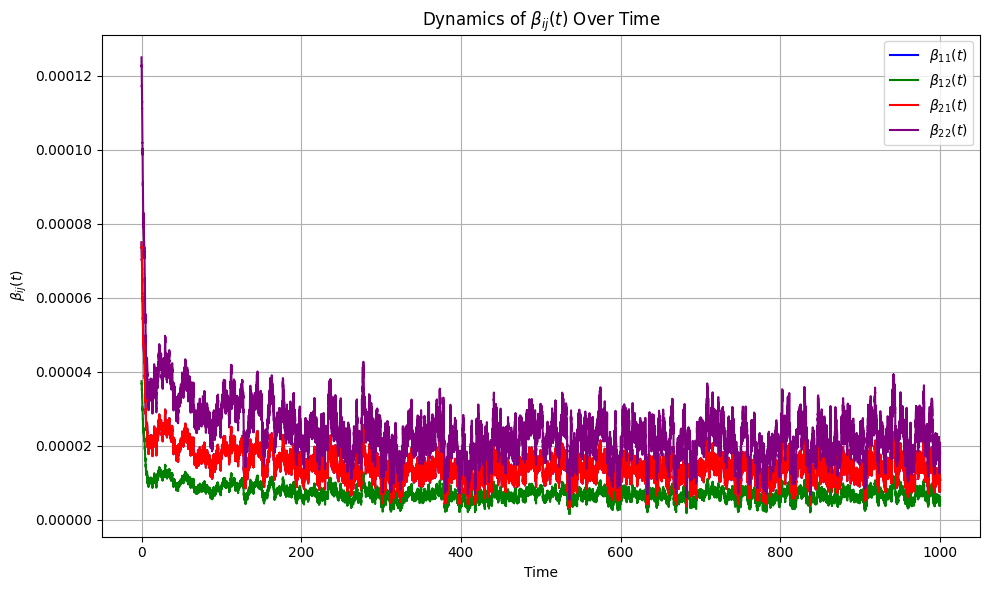

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
rho_11 = 0.3
rho_12 = 0.15
rho_21 = 0.3
rho_22 = 0.5
lambda_P = 0.02
lambda_Q = 0.02
sigma_P = 0.01
sigma_Q = 0.01
K = 1000  # Carrying capacity
T = 1000   # Total time
dt = 0.01  # Time step
time_steps = int(T / dt)
np.random.seed(42)  # Ensure reproducibility

# Initial conditions
P0 = 500
Q0 = 300

# Milstein discretization
def simulate_stochastic_dynamics(rho_11, rho_12, rho_21, rho_22, lambda_P, lambda_Q, sigma_P, sigma_Q, K, P0, Q0, time_steps, dt):
    P = np.zeros(time_steps)
    Q = np.zeros(time_steps)
    P[0] = P0
    Q[0] = Q0

    for t in range(1, time_steps):
        # Noise terms
        dW_P = np.sqrt(dt) * np.random.normal()
        dW_Q = np.sqrt(dt) * np.random.normal()

        # Population sizes
        total_population = P[t - 1] + Q[t - 1]

        # Calculate the drift terms
        drift_P = (rho_11 * P[t - 1] + rho_12 * Q[t - 1]) * (P[t - 1] / total_population) * (1 - total_population / K) - lambda_P * P[t - 1]
        drift_Q = (rho_21 * P[t - 1] + rho_22 * Q[t - 1]) * (Q[t - 1] / total_population) * (1 - total_population / K) - lambda_Q * Q[t - 1]

        # Calculate the diffusion terms
        diffusion_P = sigma_P * P[t - 1]
        diffusion_Q = sigma_Q * Q[t - 1]

        # Milstein scheme
        P[t] = P[t - 1] + drift_P * dt + diffusion_P * dW_P + 0.5 * sigma_P**2 * P[t - 1] * (dW_P**2 - dt)
        Q[t] = Q[t - 1] + drift_Q * dt + diffusion_Q * dW_Q + 0.5 * sigma_Q**2 * Q[t - 1] * (dW_Q**2 - dt)

        # Ensure non-negativity
        P[t] = max(P[t], 0)
        Q[t] = max(Q[t], 0)

    return P, Q

# Simulate the dynamics
P, Q = simulate_stochastic_dynamics(rho_11, rho_12, rho_21, rho_22, lambda_P, lambda_Q, sigma_P, sigma_Q, K, P0, Q0, time_steps, dt)

# Calculate beta values
beta_11 = rho_11 / (P + Q) * (1 - (P + Q) / K)
beta_12 = rho_12 / (P + Q) * (1 - (P + Q) / K)
beta_21 = rho_21 / (P + Q) * (1 - (P + Q) / K)
beta_22 = rho_22 / (P + Q) * (1 - (P + Q) / K)

# Time axis
time = np.arange(0, T, dt)

# Plot beta functions
plt.figure(figsize=(10, 6))
plt.plot(time, beta_11, label=r"$\beta_{11}(t)$", color="blue")
plt.plot(time, beta_12, label=r"$\beta_{12}(t)$", color="green")
plt.plot(time, beta_21, label=r"$\beta_{21}(t)$", color="red")
plt.plot(time, beta_22, label=r"$\beta_{22}(t)$", color="purple")

# Formatting the plot
plt.title("Dynamics of $\\beta_{ij}(t)$ Over Time")
plt.xlabel("Time")
plt.ylabel("$\\beta_{ij}(t)$")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


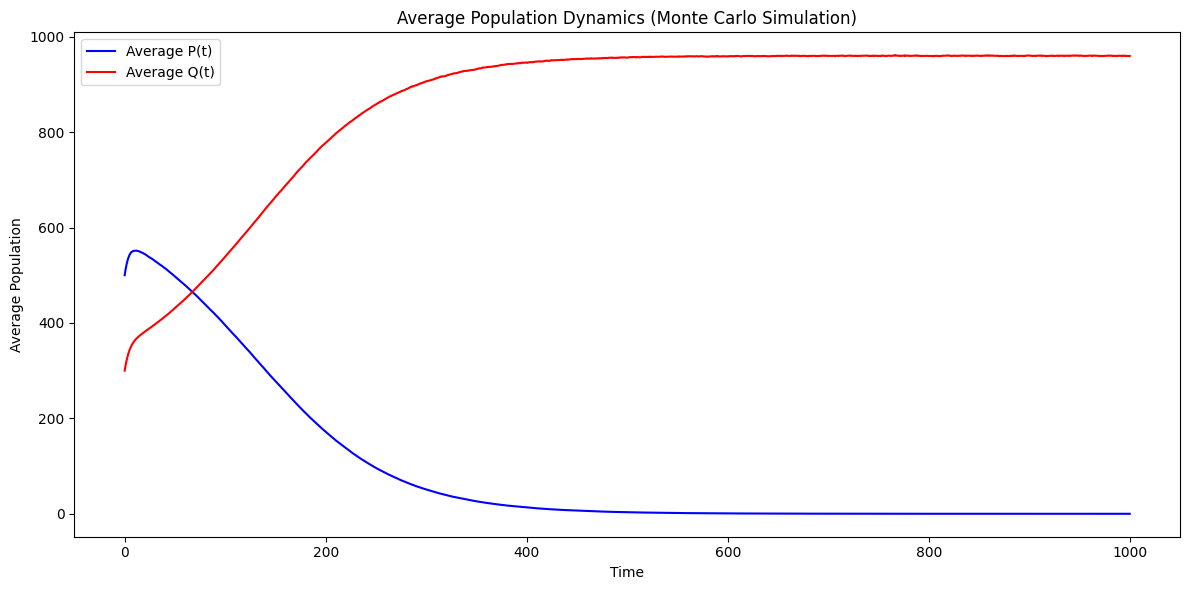

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
rho_11 = 0.3  # Interaction coefficient for P-P
rho_12 = 0.15  # Interaction coefficient for P-Q
rho_21 = 0.2  # Interaction coefficient for Q-P
rho_22 = 0.5  # Interaction coefficient for Q-Q
K = 1000  # Carrying capacity
lambda_P = 0.02  # Death rate for P
lambda_Q = 0.02  # Death rate for Q
sigma_P = 0.01  # Noise intensity for P
sigma_Q = 0.01  # Noise intensity for Q
T = 1000  # Total time
dt = 0.1  # Time step
N = int(T / dt)  # Number of steps
num_simulations = 1000  # Number of Monte Carlo simulations

# Initial conditions
P0 = 500  # Initial population of P
Q0 = 300  # Initial population of Q

# Arrays to store averaged results
P_avg = np.zeros(N)
Q_avg = np.zeros(N)
time = np.linspace(0, T, N)

# Monte Carlo simulations
for sim in range(num_simulations):
    P = np.zeros(N)
    Q = np.zeros(N)

    # Initial populations
    P[0] = P0
    Q[0] = Q0

    # Milstein method simulation
    for t in range(1, N):
        P_total = P[t-1] + Q[t-1]
        dW_P = np.random.normal(0, np.sqrt(dt))
        dW_Q = np.random.normal(0, np.sqrt(dt))

        # Dynamics of P
        growth_P = (rho_11 * P[t-1] + rho_12 * Q[t-1]) * (P[t-1] / P_total) * (1 - P_total / K)
        death_P = lambda_P * P[t-1]
        stochastic_P = sigma_P * P[t-1] * dW_P
        P[t] = P[t-1] + dt * (growth_P - death_P) + stochastic_P + 0.5 * sigma_P * P[t-1] * (dW_P**2 - dt)

        # Dynamics of Q
        growth_Q = (rho_21 * P[t-1] + rho_22 * Q[t-1]) * (Q[t-1] / P_total) * (1 - P_total / K)
        death_Q = lambda_Q * Q[t-1]
        stochastic_Q = sigma_Q * Q[t-1] * dW_Q
        Q[t] = Q[t-1] + dt * (growth_Q - death_Q) + stochastic_Q + 0.5 * sigma_Q * Q[t-1] * (dW_Q**2 - dt)

    # Accumulate results
    P_avg += P
    Q_avg += Q

# Compute averages
P_avg /= num_simulations
Q_avg /= num_simulations

# Plotting
plt.figure(figsize=(12, 6))

# Plot averaged populations
plt.plot(time, P_avg, label='Average P(t)', color='blue')
plt.plot(time, Q_avg, label='Average Q(t)', color='red')
plt.xlabel('Time')
plt.ylabel('Average Population')
plt.title('Average Population Dynamics (Monte Carlo Simulation)')
plt.legend()

plt.tight_layout()
plt.show()


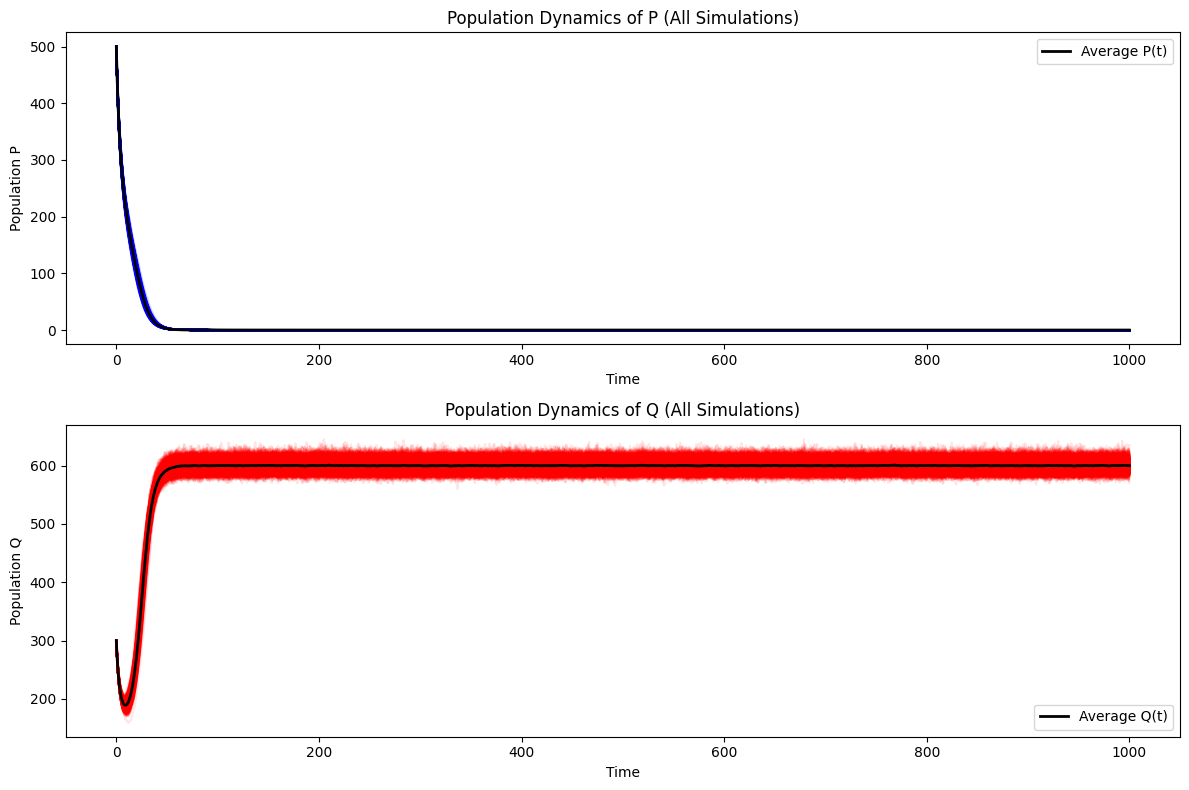

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
rho_11 = 0.3  # Interaction coefficient for P-P
rho_12 = 0.15  # Interaction coefficient for P-Q
rho_21 = 0.2  # Interaction coefficient for Q-P
rho_22 = 0.5  # Interaction coefficient for Q-Q
K = 1000  # Carrying capacity
lambda_P = 0.2  # Death rate for P
lambda_Q = 0.2  # Death rate for Q
sigma_P = 0.01  # Noise intensity for P
sigma_Q = 0.01  # Noise intensity for Q
gamma_P = 0.5  # Parameter for P
gamma_Q = 0.5  # Parameter for Q
T = 1000  # Total time
dt = 0.1  # Time step
N = int(T / dt)  # Number of steps
num_simulations = 1000  # Number of Monte Carlo simulations

# Initial conditions
P0 = 500  # Initial population of P
Q0 = 300  # Initial population of Q

# Arrays to store averaged results
P_avg = np.zeros(N)
Q_avg = np.zeros(N)
time = np.linspace(0, T, N)

# Array to store all simulations for visualization
all_P = np.zeros((num_simulations, N))
all_Q = np.zeros((num_simulations, N))

# Monte Carlo simulations
for sim in range(num_simulations):
    P = np.zeros(N)
    Q = np.zeros(N)

    # Initial populations
    P[0] = P0
    Q[0] = Q0

    # Milstein method simulation
    for t in range(1, N):
        P_total = P[t-1] + Q[t-1]
        dW_P = np.random.normal(0, np.sqrt(dt))
        dW_Q = np.random.normal(0, np.sqrt(dt))

        # Dynamics of P
        growth_P = (rho_11 * P[t-1] + rho_12 * Q[t-1]) * (P[t-1] / P_total) * (1 - P_total / K)
        death_P = lambda_P * P[t-1]
        stochastic_P = sigma_P * P[t-1] * dW_P
        P[t] = P[t-1] + dt * (growth_P - death_P) + stochastic_P + 0.5 * sigma_P * P[t-1] * (dW_P**2 - dt)

        # Dynamics of Q
        growth_Q = (rho_21 * P[t-1] + rho_22 * Q[t-1]) * (Q[t-1] / P_total) * (1 - P_total / K)
        death_Q = lambda_Q * Q[t-1]
        stochastic_Q = sigma_Q * Q[t-1] * dW_Q
        Q[t] = Q[t-1] + dt * (growth_Q - death_Q) + stochastic_Q + 0.5 * sigma_Q * Q[t-1] * (dW_Q**2 - dt)

    # Store individual simulation results
    all_P[sim, :] = P
    all_Q[sim, :] = Q

    # Accumulate results
    P_avg += P
    Q_avg += Q

# Compute averages
P_avg /= num_simulations
Q_avg /= num_simulations

# Plotting
plt.figure(figsize=(12, 8))

# Plot all simulations for P
plt.subplot(2, 1, 1)
for sim in range(num_simulations):
    plt.plot(time, all_P[sim, :], color='blue', alpha=0.1)
plt.plot(time, P_avg, label='Average P(t)', color='black', linewidth=2)
plt.xlabel('Time')
plt.ylabel('Population P')
plt.title('Population Dynamics of P (All Simulations)')
plt.legend()

# Plot all simulations for Q
plt.subplot(2, 1, 2)
for sim in range(num_simulations):
    plt.plot(time, all_Q[sim, :], color='red', alpha=0.1)
plt.plot(time, Q_avg, label='Average Q(t)', color='black', linewidth=2)
plt.xlabel('Time')
plt.ylabel('Population Q')
plt.title('Population Dynamics of Q (All Simulations)')
plt.legend()

plt.tight_layout()
plt.show()


<ipython-input-11-e185781eea48>:79: RuntimeWarning: overflow encountered in scalar multiply
  stochastic_prevalence[t] = P_t + (1 / sigma_Q) * dt * P_t * (1 - P_t) * dW
<ipython-input-11-e185781eea48>:79: RuntimeWarning: invalid value encountered in scalar add
  stochastic_prevalence[t] = P_t + (1 / sigma_Q) * dt * P_t * (1 - P_t) * dW


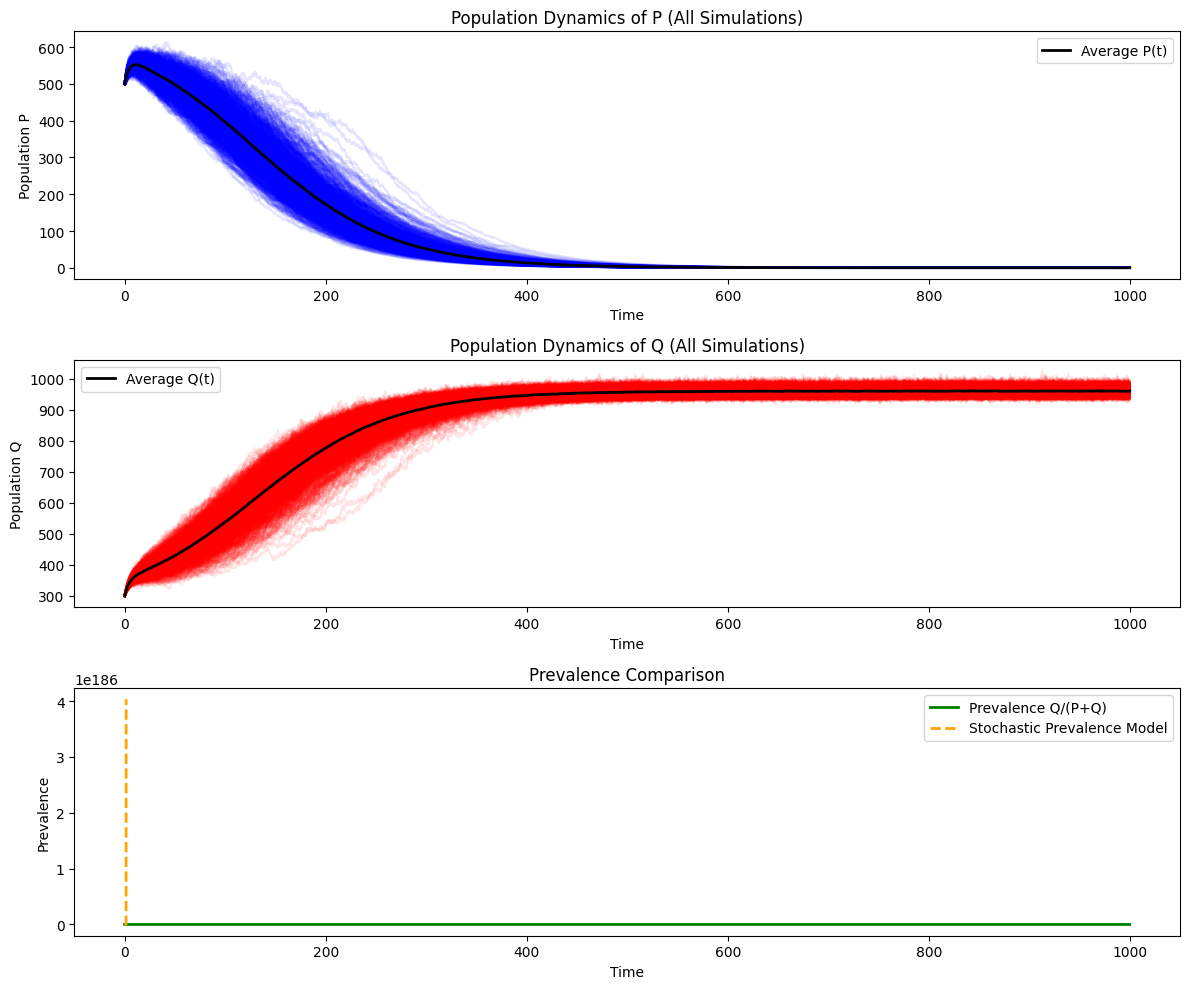

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
rho_11 = 0.3  # Interaction coefficient for P-P
rho_12 = 0.15  # Interaction coefficient for P-Q
rho_21 = 0.2  # Interaction coefficient for Q-P
rho_22 = 0.5  # Interaction coefficient for Q-Q
K = 1000  # Carrying capacity
lambda_P = 0.02  # Death rate for P
lambda_Q = 0.02  # Death rate for Q
sigma_P = 0.01  # Noise intensity for P
sigma_Q = 0.01  # Noise intensity for Q
T = 1000  # Total time
dt = 0.1  # Time step
N = int(T / dt)  # Number of steps
num_simulations = 1000  # Number of Monte Carlo simulations

# Initial conditions
P0 = 500  # Initial population of P
Q0 = 300  # Initial population of Q

# Arrays to store averaged results
P_avg = np.zeros(N)
Q_avg = np.zeros(N)
time = np.linspace(0, T, N)

# Array to store all simulations for visualization
all_P = np.zeros((num_simulations, N))
all_Q = np.zeros((num_simulations, N))

# Monte Carlo simulations
for sim in range(num_simulations):
    P = np.zeros(N)
    Q = np.zeros(N)

    # Initial populations
    P[0] = P0
    Q[0] = Q0

    # Milstein method simulation
    for t in range(1, N):
        P_total = P[t-1] + Q[t-1]
        dW_P = np.random.normal(0, np.sqrt(dt))
        dW_Q = np.random.normal(0, np.sqrt(dt))

        # Dynamics of P
        growth_P = (rho_11 * P[t-1] + rho_12 * Q[t-1]) * (P[t-1] / P_total) * (1 - P_total / K)
        death_P = lambda_P * P[t-1]
        stochastic_P = sigma_P * P[t-1] * dW_P
        P[t] = P[t-1] + dt * (growth_P - death_P) + stochastic_P + 0.5 * sigma_P * P[t-1] * (dW_P**2 - dt)

        # Dynamics of Q
        growth_Q = (rho_21 * P[t-1] + rho_22 * Q[t-1]) * (Q[t-1] / P_total) * (1 - P_total / K)
        death_Q = lambda_Q * Q[t-1]
        stochastic_Q = sigma_Q * Q[t-1] * dW_Q
        Q[t] = Q[t-1] + dt * (growth_Q - death_Q) + stochastic_Q + 0.5 * sigma_Q * Q[t-1] * (dW_Q**2 - dt)

    # Store individual simulation results
    all_P[sim, :] = P
    all_Q[sim, :] = Q

    # Accumulate results
    P_avg += P
    Q_avg += Q

# Compute averages
P_avg /= num_simulations
Q_avg /= num_simulations

# Calculate prevalence and stochastic prevalence model
prevalence = Q_avg / (P_avg + Q_avg)
stochastic_prevalence = np.zeros(N)
stochastic_prevalence[0] = Q0 / (P0 + Q0)  # Initial prevalence

for t in range(1, N):
    dW = np.random.normal(0, np.sqrt(dt))
    P_t = stochastic_prevalence[t-1]
    stochastic_prevalence[t] = P_t + (1 / sigma_Q) * dt * P_t * (1 - P_t) * dW

# Plotting
plt.figure(figsize=(12, 10))

# Plot all simulations for P
plt.subplot(3, 1, 1)
for sim in range(num_simulations):
    plt.plot(time, all_P[sim, :], color='blue', alpha=0.1)
plt.plot(time, P_avg, label='Average P(t)', color='black', linewidth=2)
plt.xlabel('Time')
plt.ylabel('Population P')
plt.title('Population Dynamics of P (All Simulations)')
plt.legend()

# Plot all simulations for Q
plt.subplot(3, 1, 2)
for sim in range(num_simulations):
    plt.plot(time, all_Q[sim, :], color='red', alpha=0.1)
plt.plot(time, Q_avg, label='Average Q(t)', color='black', linewidth=2)
plt.xlabel('Time')
plt.ylabel('Population Q')
plt.title('Population Dynamics of Q (All Simulations)')
plt.legend()

# Plot prevalence comparison
plt.subplot(3, 1, 3)
plt.plot(time, prevalence, label='Prevalence Q/(P+Q)', color='green', linewidth=2)
plt.plot(time, stochastic_prevalence, label='Stochastic Prevalence Model', color='orange', linestyle='--', linewidth=2)
plt.xlabel('Time')
plt.ylabel('Prevalence')
plt.title('Prevalence Comparison')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
# import sympy as sp

# # Define variables
# P, Q, t = sp.symbols('P Q t', positive=True)
# rho_11, rho_12, rho_21, rho_22, k, lambda_P, lambda_Q, sigma_P, sigma_Q = sp.symbols(
#     'rho_11 rho_12 rho_21 rho_22 k lambda_P lambda_Q sigma_P sigma_Q', positive=True)

# # Define drift terms
# F_P = ((rho_11 * P + rho_12 * Q) / (P + Q)) * P * (1 - (P + Q) / k) - lambda_P * P
# F_Q = ((rho_21 * P + rho_22 * Q) / (P + Q)) * Q * (1 - (P + Q) / k) - lambda_Q * Q

# # Define diffusion terms
# G1 = sigma_P * P
# G2 = sigma_Q * Q

# # Gradient of diffusion terms
# Grad_G1 = sp.Matrix([sp.diff(G1, P), sp.diff(G1, Q)])
# Grad_G2 = sp.Matrix([sp.diff(G2, P), sp.diff(G2, Q)])

# # Drift field
# F = sp.Matrix([F_P, F_Q])

# # Compute commutators
# Lie_FG1 = F.jacobian([P, Q]) * Grad_G1 - Grad_G1.jacobian([P, Q]) * F
# Lie_FG2 = F.jacobian([P, Q]) * Grad_G2 - Grad_G2.jacobian([P, Q]) * F

# # Output the results
# print("Lie Bracket [F, G1]:")
# sp.pprint(Lie_FG1)

# print("\nLie Bracket [F, G2]:")
# sp.pprint(Lie_FG2)


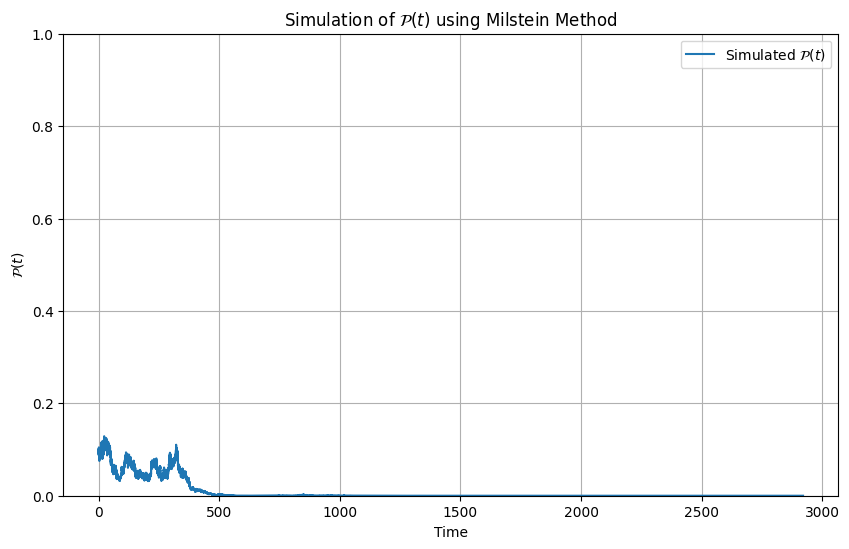

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(77)
# Parameters
sigma = 0.1  # Volatility
P0 = 0.1  # Initial condition for P(t)
T = 2920.0  # Total time
dt = 0.01  # Time step
N = int(T / dt)  # Number of steps
time = np.linspace(0, T, N)

# Milstein method
def milstein(P0, sigma, T, dt):
    N = int(T / dt)
    P = np.zeros(N)
    P[0] = P0
    W = np.random.normal(0, np.sqrt(dt), N - 1)  # Wiener increments

    for i in range(1, N):
        P_t = P[i - 1]
        if P_t <= 0 or P_t >= 1:  # Prevent leaving the (0, 1) interval
            break

        drift = 0  # No explicit drift term in the given SDE
        diffusion = sigma * P_t * (1 - P_t)
        derivative_diffusion = sigma * (1 - 2 * P_t)  # Derivative wrt P

        P[i] = P_t + drift * dt + diffusion * W[i - 1] + 0.5 * diffusion * derivative_diffusion * (W[i - 1] ** 2 - dt)

    return P

# Simulate
P = milstein(P0, sigma, T, dt)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(time, P, label="Simulated $\mathcal{P}(t)$")
plt.title("Simulation of $\mathcal{P}(t)$ using Milstein Method")
plt.xlabel("Time")
plt.ylabel("$\mathcal{P}(t)$")
plt.ylim(0, 1)
plt.grid()
plt.legend()
plt.show()


/usr/local/lib/python3.10/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


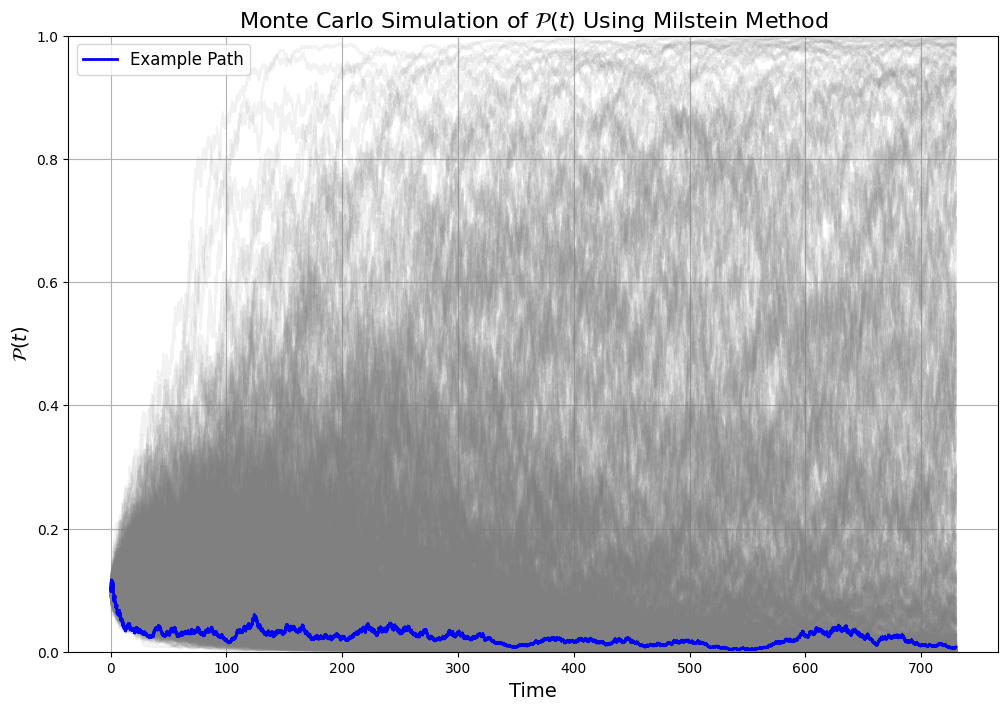

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
sigma = 0.1  # Volatility
P0 = 0.1  # Initial condition for P(t)
T = 730.0  # Total time
dt = 0.01  # Time step
N = int(T / dt)  # Number of steps
time = np.linspace(0, T, N)
num_simulations = 1000  # Number of Monte Carlo simulations

# Milstein method
def milstein(P0, sigma, T, dt):
    N = int(T / dt)
    P = np.zeros(N)
    P[0] = P0
    W = np.random.normal(0, np.sqrt(dt), N - 1)  # Wiener increments

    for i in range(1, N):
        P_t = P[i - 1]
        if P_t <= 0 or P_t >= 1:  # Prevent leaving the (0, 1) interval
            break

        drift = 0  # No explicit drift term in the given SDE
        diffusion = sigma * P_t * (1 - P_t)
        derivative_diffusion = sigma * (1 - 2 * P_t)  # Derivative wrt P

        P[i] = P_t + drift * dt + diffusion * W[i - 1] + 0.5 * diffusion * derivative_diffusion * (W[i - 1] ** 2 - dt)

    return P

# Monte Carlo simulation
all_paths = np.zeros((num_simulations, N))
for i in range(num_simulations):
    all_paths[i, :] = milstein(P0, sigma, T, dt)

# Plotting the paths
plt.figure(figsize=(12, 8))
for i in range(num_simulations):
    plt.plot(time, all_paths[i, :], color='grey', alpha=0.1)  # Grey paths for individual simulations

# Highlight one path for clarity
plt.plot(time, all_paths[0, :], color='blue', linewidth=2, label="Example Path")

# Add labels and title
plt.title("Monte Carlo Simulation of $\mathcal{P}(t)$ Using Milstein Method", fontsize=16)
plt.xlabel("Time", fontsize=14)
plt.ylabel("$\mathcal{P}(t)$", fontsize=14)
plt.ylim(0, 1)
plt.grid()
plt.legend(fontsize=12)
plt.show()


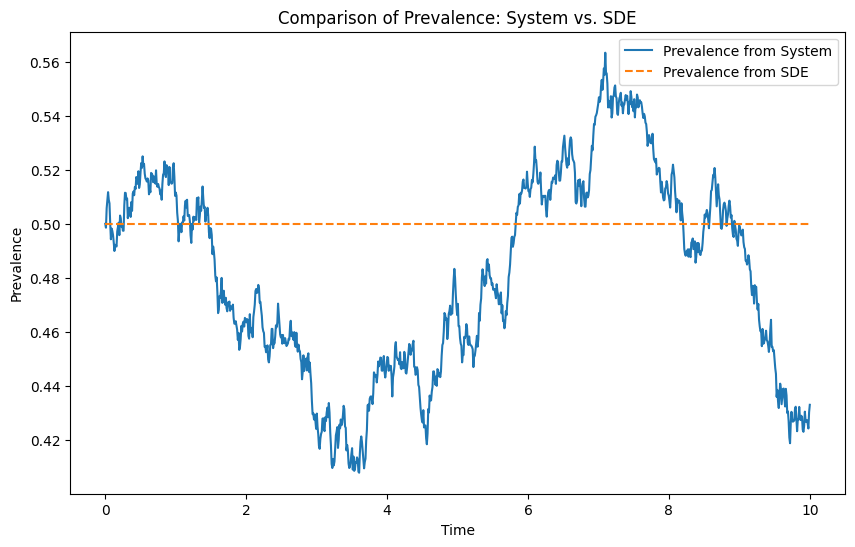

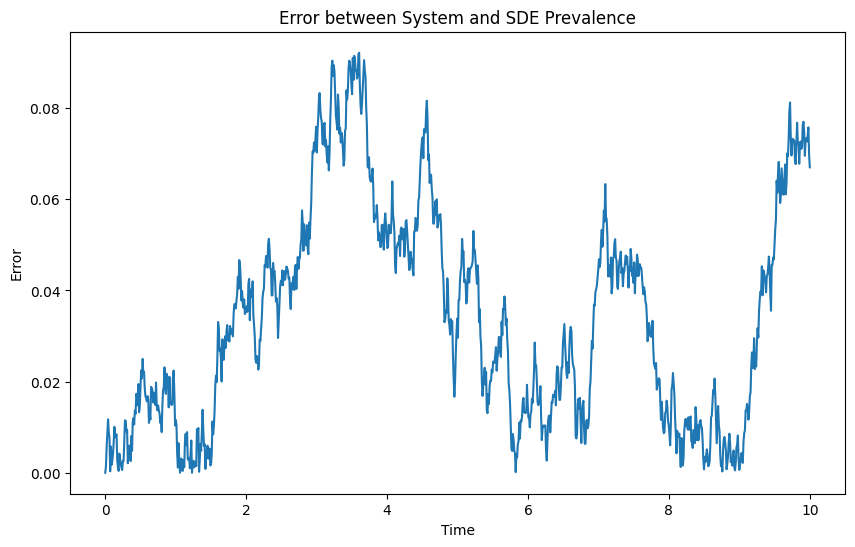

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define parameters
sigma_P = 0.1  # Volatility for P
sigma_Q = 0.1  # Volatility for Q
gamma_P = 0.5  # Parameter for P
gamma_Q = 0.5  # Parameter for Q
K = 1000       # Carrying capacity
lambda_P = 0.1 # Death rate for P
lambda_Q = 0.1 # Death rate for Q
rho_11 = 0.2   # Interaction term for P
rho_12 = 0.1   # Interaction term for Q
rho_21 = 0.1   # Interaction term for P
rho_22 = 0.2   # Interaction term for Q
P0 = 10         # Initial P
Q0 = 10         # Initial Q
T = 10          # Total time
dt = 0.01       # Time step
N = int(T / dt) # Number of steps

# Initialize arrays
time = np.linspace(0, T, N)
P = np.zeros(N)
Q = np.zeros(N)
P[0] = P0
Q[0] = Q0

# Simulate P and Q based on the given system
for i in range(1, N):
    # Brownian increments for P and Q
    dW_P = np.random.normal(0, np.sqrt(dt))
    dW_Q = np.random.normal(0, np.sqrt(dt))

    # System equations for dP and dQ
    dP = ((rho_11 * P[i-1] + rho_12 * Q[i-1]) / (P[i-1] + Q[i-1]) * P[i-1] * (1 - (P[i-1] + Q[i-1]) / K) - lambda_P * P[i-1]) * dt + sigma_P * P[i-1] * dW_P
    dQ = ((rho_21 * P[i-1] + rho_22 * Q[i-1]) / (P[i-1] + Q[i-1]) * Q[i-1] * (1 - (P[i-1] + Q[i-1]) / K) - lambda_Q * Q[i-1]) * dt + sigma_Q * Q[i-1] * dW_Q

    # Update P and Q
    P[i] = P[i-1] + dP
    Q[i] = Q[i-1] + dQ

# Calculate prevalence from system
P_sys = P / (P + Q)

# Prevalence from SDE (numerically solve SDE for P(t))
# Assuming a simple Euler method for the SDE
sigma = sigma_Q * gamma_Q - sigma_P * gamma_P
P_SDE = np.zeros(N)
P_SDE[0] = P0 / (P0 + Q0)
for i in range(1, N):
    dW = np.random.normal(0, np.sqrt(dt))
    dP_SDE = sigma * P_SDE[i-1] * (1 - P_SDE[i-1]) * dW
    P_SDE[i] = P_SDE[i-1] + dP_SDE

# Calculate error between the two models
error = np.abs(P_sys - P_SDE)

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(time, P_sys, label="Prevalence from System")
plt.plot(time, P_SDE, label="Prevalence from SDE", linestyle='--')
plt.xlabel("Time")
plt.ylabel("Prevalence")
plt.legend()
plt.title("Comparison of Prevalence: System vs. SDE")
plt.show()

# Plot the error
plt.figure(figsize=(10, 6))
plt.plot(time, error)
plt.xlabel("Time")
plt.ylabel("Error")
plt.title("Error between System and SDE Prevalence")
plt.show()


Mean Absolute Error (MAE): 0.1350
Mean Squared Error (MSE): 0.0192
Root Mean Squared Error (RMSE): 0.1387
Maximum Error: 0.2019
R-squared: -254.2380


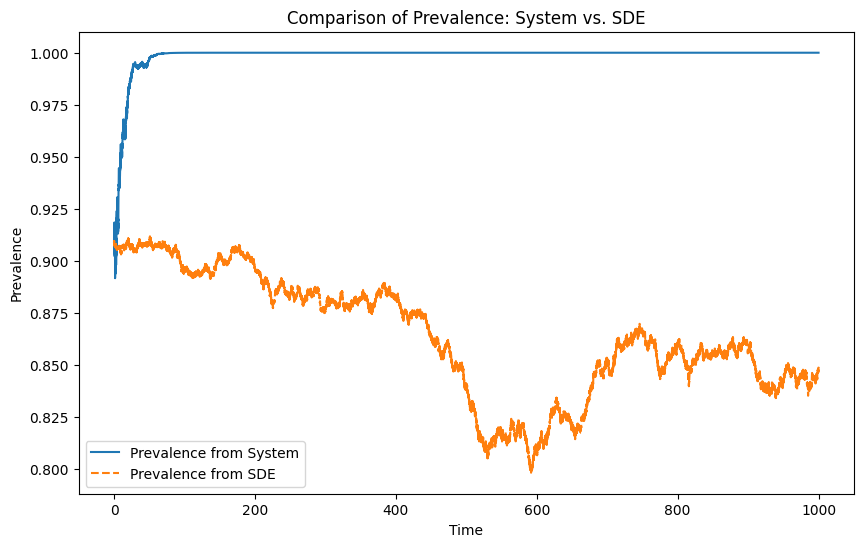

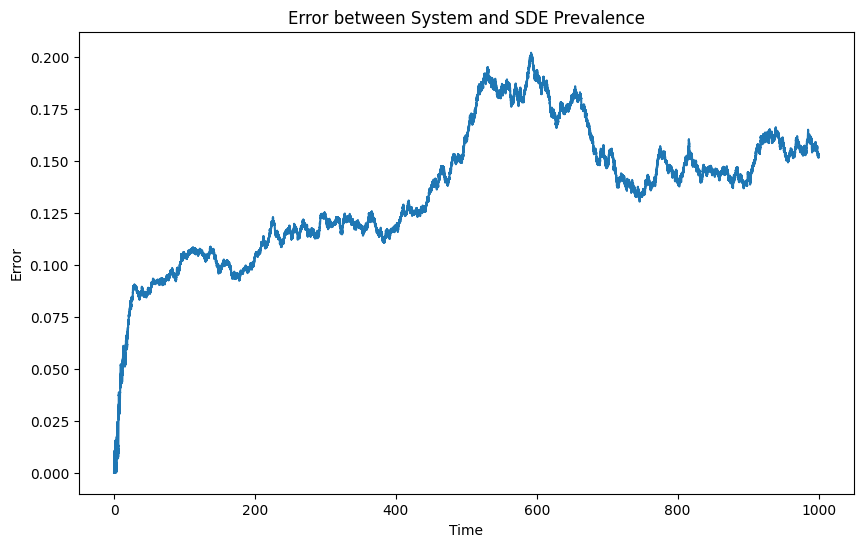

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define parameters
sigma_P = 0.1  # Volatility for P
sigma_Q = 0.1  # Volatility for Q
gamma_P = 0.1  # Parameter for P
gamma_Q = 0.25  # Parameter for Q
K = 1000       # Carrying capacity
lambda_P = 0.221 # Death rate for P
lambda_Q = 0.21 # Death rate for Q
rho_11 = 0.2   # Interaction term for P
rho_12 = 0.1   # Interaction term for Q
rho_21 = 0.1   # Interaction term for P
rho_22 = 0.2   # Interaction term for Q
P0 = 100         # Initial P
Q0 = 10         # Initial Q
T = 1000         # Total time
dt = 0.01       # Time step
N = int(T / dt) # Number of steps

# Initialize arrays
time = np.linspace(0, T, N)
P = np.zeros(N)
Q = np.zeros(N)
P[0] = P0
Q[0] = Q0

# Simulate P and Q based on the given system
for i in range(1, N):
    # Brownian increments for P and Q
    dW_P = np.random.normal(0, np.sqrt(dt))
    dW_Q = np.random.normal(0, np.sqrt(dt))

    # System equations for dP and dQ
    dP = ((rho_11 * P[i-1] + rho_12 * Q[i-1]) / (P[i-1] + Q[i-1]) * P[i-1] * (1 - (P[i-1] + Q[i-1]) / K) - lambda_P * P[i-1]) * dt + sigma_P * P[i-1] * dW_P
    dQ = ((rho_21 * P[i-1] + rho_22 * Q[i-1]) / (P[i-1] + Q[i-1]) * Q[i-1] * (1 - (P[i-1] + Q[i-1]) / K) - lambda_Q * Q[i-1]) * dt + sigma_Q * Q[i-1] * dW_Q

    # Update P and Q
    P[i] = P[i-1] + dP
    Q[i] = Q[i-1] + dQ

# Calculate prevalence from system
P_sys = P / (P + Q)

# Prevalence from SDE (numerically solve SDE for P(t))
# Assuming a simple Euler method for the SDE
sigma = sigma_Q * gamma_Q - sigma_P * gamma_P
P_SDE = np.zeros(N)
P_SDE[0] = P0 / (P0 + Q0)
for i in range(1, N):
    dW = np.random.normal(0, np.sqrt(dt))
    dP_SDE = sigma * P_SDE[i-1] * (1 - P_SDE[i-1]) * dW
    P_SDE[i] = P_SDE[i-1] + dP_SDE

# Calculate error between the two models
error = np.abs(P_sys - P_SDE)
mean_error = np.mean(error)
max_error = np.max(error)
mse = np.mean(error**2)
rmse = np.sqrt(mse)

# R-squared calculation
ss_total = np.sum((P_sys - np.mean(P_sys))**2)
ss_residual = np.sum((P_sys - P_SDE)**2)
r_squared = 1 - (ss_residual / ss_total)

# Print out results
print(f"Mean Absolute Error (MAE): {mean_error:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Maximum Error: {max_error:.4f}")
print(f"R-squared: {r_squared:.4f}")

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(time, P_sys, label="Prevalence from System")
plt.plot(time, P_SDE, label="Prevalence from SDE", linestyle='--')
plt.xlabel("Time")
plt.ylabel("Prevalence")
plt.legend()
plt.title("Comparison of Prevalence: System vs. SDE")
plt.show()

# Plot the error
plt.figure(figsize=(10, 6))
plt.plot(time, error)
plt.xlabel("Time")
plt.ylabel("Error")
plt.title("Error between System and SDE Prevalence")
plt.show()


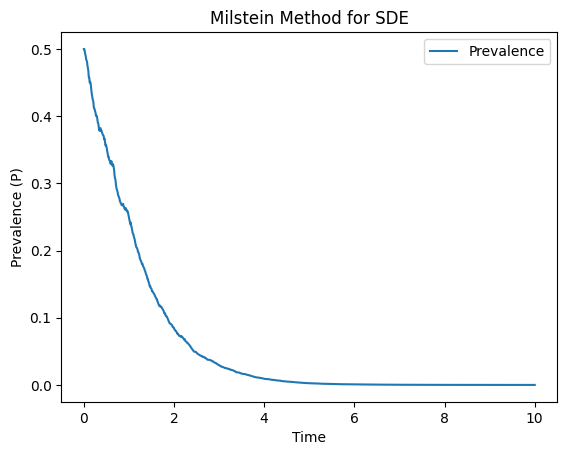

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
T = 10.0  # total simulation time
dt = 0.01  # time step
N = int(T / dt)  # number of steps
sigma = 0.1  # diffusion coefficient
lambda_P = 0.05
lambda_Q = 0.03
K = 100  # carrying capacity (constant for simplicity)
rho_21 = lambda t: 0.02  # example time-dependent function
rho_22 = lambda t: 0.01

# Initial condition
P0 = 0.5
P = np.zeros(N)
P[0] = P0

# Time vector
t = np.linspace(0, T, N)

# Milstein method
for n in range(N - 1):
    A = (
        P[n] * (1 - P[n]) * (rho_21(t[n]) * (1 - P[n]) + rho_22(t[n]) * P[n])
        - P[n] * (1 - P[n]) * (1 - 1 / K)
        - lambda_Q * P[n]
        - (lambda_P + lambda_Q) * P[n] * (1 - P[n])
    )
    diffusion = sigma * P[n] * (1 - P[n])
    dW = np.sqrt(dt) * np.random.randn()
    P[n + 1] = P[n] + A * dt + diffusion * dW + 0.5 * sigma**2 * P[n] * (1 - P[n]) * (1 - 2 * P[n]) * (dW**2 - dt)

# Plot the result
plt.plot(t, P, label="Prevalence")
plt.xlabel("Time")
plt.ylabel("Prevalence (P)")
plt.title("Milstein Method for SDE")
plt.legend()
plt.show()


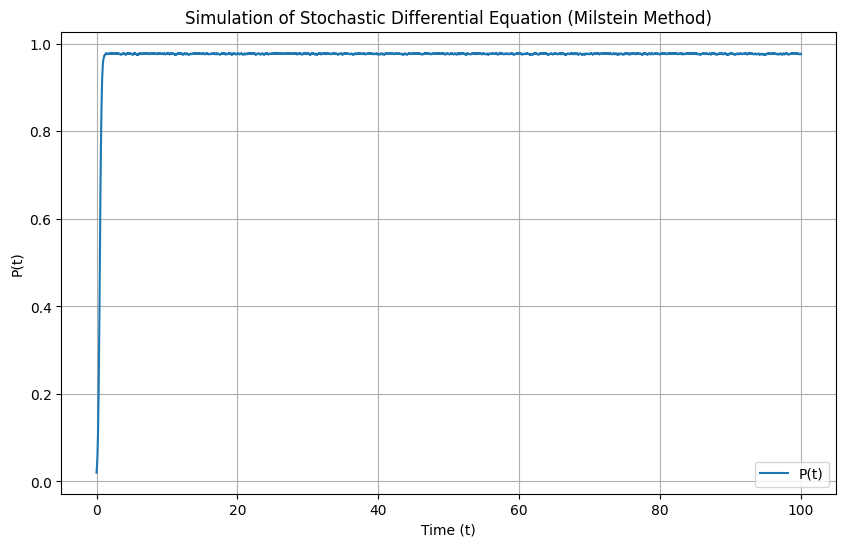

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

def simulate_sde_milstein(
    T, dt, P0, rho21, rho22, K, lambdaP, lambdaQ, sigma
):
    """
    Simulate and plot the given SDE using the Milstein method:
    dP(t) = [P(1-P)(rho21(t)(1-P) + rho22(t)P) - P(1-P)(1-K(t)) - lambdaQ*P - (lambdaP+lambdaQ)*P(1-P)]dt
            + sigma*P(t)*(1-P(t))dW(t)

    Parameters:
    T: Total simulation time.
    dt: Time step size.
    P0: Initial value of P.
    rho21: Function rho21(t).
    rho22: Function rho22(t).
    K: Function K(t).
    lambdaP: Constant lambdaP.
    lambdaQ: Constant lambdaQ.
    sigma: Volatility coefficient.
    """
    n_steps = int(T / dt)
    P = np.zeros(n_steps)
    P[0] = P0
    time = np.linspace(0, T, n_steps)

    for i in range(1, n_steps):
        t = time[i - 1]
        Wt = np.sqrt(dt) * np.random.normal()

        drift = (
            P[i - 1] * (1 - P[i - 1]) * (rho21(t) * (1 - P[i - 1]) + rho22(t) * P[i - 1])
            - P[i - 1] * (1 - P[i - 1]) * (1 - K(t))
            - lambdaQ * P[i - 1]
            - (lambdaP + lambdaQ) * P[i - 1] * (1 - P[i - 1])
        )

        diffusion = sigma * P[i - 1] * (1 - P[i - 1])

        # Milstein correction term
        milstein_correction = 0.5 * sigma**2 * (1 - 2 * P[i - 1]) * diffusion * Wt

        P[i] = P[i - 1] + drift * dt + diffusion * Wt + milstein_correction

        # Keep P within [0,1]
        P[i] = max(0, min(1, P[i]))

    # Plot the results
    plt.figure(figsize=(10, 6))
    plt.plot(time, P, label="P(t)")
    plt.title("Simulation of Stochastic Differential Equation (Milstein Method)")
    plt.xlabel("Time (t)")
    plt.ylabel("P(t)")
    plt.legend()
    plt.grid()
    plt.show()

# Example usage:
T = 100         # Total time
dt = 0.01      # Time step size
P0 = 0.02       # Initial value of P
lambdaP = 0.21  # Constant lambdaP
lambdaQ = 0.2  # Constant lambdaQ
sigma = 0.13    # Volatility coefficient

def rho21(t):
    return 0.1  # Example constant function for rho21

def rho22(t):
    return 0.2  # Example constant function for rho22

def K(t):
    return 10  # Example constant function for K

simulate_sde_milstein(T, dt, P0, rho21, rho22, K, lambdaP, lambdaQ, sigma)

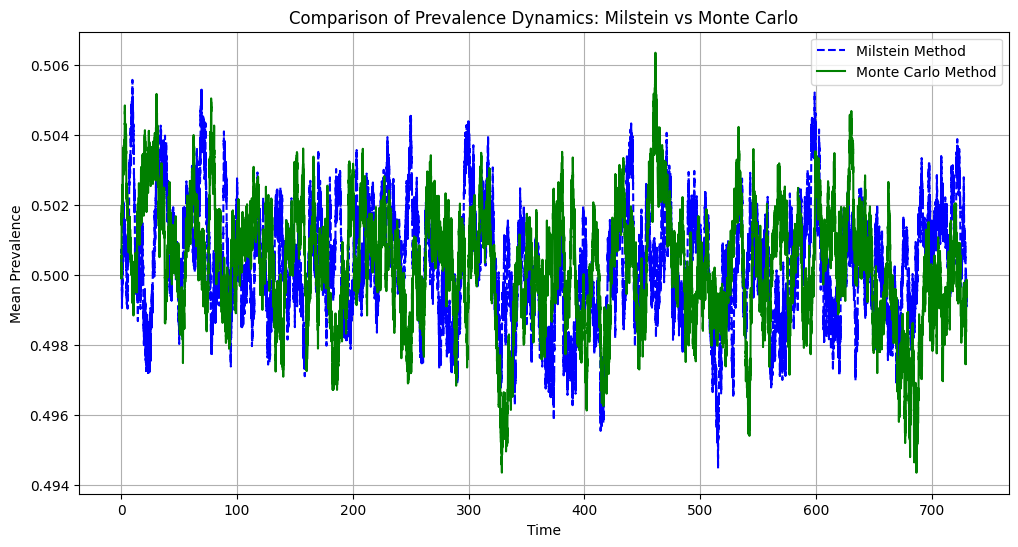

Mean Absolute Error (MAE): 0.0017
Mean Squared Error (MSE): 0.0000
Root Mean Squared Error (RMSE): 0.0022
R-squared: -0.9003


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Parameters (example values)
sigma_P = 0.1  # Volatility for P(t)
sigma_Q = 0.1  # Volatility for Q(t)
gamma_P = 0.5  # Correlation coefficient for P(t)
gamma_Q = 0.5  # Correlation coefficient for Q(t)
K = 1000  # Carrying capacity (example)
P0 = 0.1  # Initial prevalence for P(t)
Q0 = 0.1  # Initial prevalence for Q(t)
T = 730  # Total time (2 years)
dt = 0.01  # Time step
N = int(T / dt)  # Number of steps
time = np.linspace(0, T, N)
n_simulations = 1000  # Number of Monte Carlo simulations

# Seed for reproducibility
np.random.seed(42)

# Milstein method for solving SDEs
def milstein_method(sigma_P, sigma_Q, gamma_P, gamma_Q, P0, Q0, T, dt, n_simulations):
    P = np.zeros((n_simulations, N))
    Q = np.zeros((n_simulations, N))
    W_P = np.zeros((n_simulations, N))  # Wiener process for P(t)
    W_Q = np.zeros((n_simulations, N))  # Wiener process for Q(t)

    for j in range(n_simulations):
        P[j, 0] = P0
        Q[j, 0] = Q0
        for i in range(1, N):
            # Generate Wiener increments
            dW_P = np.random.normal(0, np.sqrt(dt))
            dW_Q = np.random.normal(0, np.sqrt(dt))
            W_P[j, i] = W_P[j, i-1] + dW_P
            W_Q[j, i] = W_Q[j, i-1] + dW_Q

            # Apply the Milstein method (with discretization of the SDE)
            drift_P = (gamma_P * P[j, i-1] * (1 - P[j, i-1])) * (P[j, i-1] / (P[j, i-1] + Q[j, i-1])) * (1 - (P[j, i-1] + Q[j, i-1]) / K)
            drift_Q = (gamma_Q * Q[j, i-1] * (1 - Q[j, i-1])) * (Q[j, i-1] / (P[j, i-1] + Q[j, i-1])) * (1 - (P[j, i-1] + Q[j, i-1]) / K)

            # Milstein's method for stochastic differential equations (SDE)
            P[j, i] = P[j, i-1] + drift_P * dt + sigma_P * P[j, i-1] * dW_P + 0.5 * sigma_P * P[j, i-1] * (dW_P**2 - dt)
            Q[j, i] = Q[j, i-1] + drift_Q * dt + sigma_Q * Q[j, i-1] * dW_Q + 0.5 * sigma_Q * Q[j, i-1] * (dW_Q**2 - dt)

    return P, Q

# Monte Carlo simulation for prevalence model based on your system
def monte_carlo_simulation(sigma_P, sigma_Q, gamma_P, gamma_Q, P0, Q0, T, dt, n_simulations):
    P = np.zeros((n_simulations, N))
    Q = np.zeros((n_simulations, N))
    W_P = np.zeros((n_simulations, N))  # Wiener process for P(t)
    W_Q = np.zeros((n_simulations, N))  # Wiener process for Q(t)

    for j in range(n_simulations):
        P[j, 0] = P0
        Q[j, 0] = Q0
        for i in range(1, N):
            # Generate Wiener increments
            dW_P = np.random.normal(0, np.sqrt(dt))
            dW_Q = np.random.normal(0, np.sqrt(dt))
            W_P[j, i] = W_P[j, i-1] + dW_P
            W_Q[j, i] = W_Q[j, i-1] + dW_Q

            # Apply the dynamics for P(t) and Q(t)
            drift_P = (gamma_P * P[j, i-1] * (1 - P[j, i-1])) * (P[j, i-1] / (P[j, i-1] + Q[j, i-1])) * (1 - (P[j, i-1] + Q[j, i-1]) / K)
            drift_Q = (gamma_Q * Q[j, i-1] * (1 - Q[j, i-1])) * (Q[j, i-1] / (P[j, i-1] + Q[j, i-1])) * (1 - (P[j, i-1] + Q[j, i-1]) / K)

            # Stochastic differential equation for P(t) and Q(t)
            P[j, i] = P[j, i-1] + drift_P * dt + sigma_P * P[j, i-1] * dW_P
            Q[j, i] = Q[j, i-1] + drift_Q * dt + sigma_Q * Q[j, i-1] * dW_Q

    return P, Q

# Run the simulations
P_milstein, Q_milstein = milstein_method(sigma_P, sigma_Q, gamma_P, gamma_Q, P0, Q0, T, dt, n_simulations)
P_monte_carlo, Q_monte_carlo = monte_carlo_simulation(sigma_P, sigma_Q, gamma_P, gamma_Q, P0, Q0, T, dt, n_simulations)

# Calculate prevalence (P(t) / (P(t) + Q(t))) for each simulation
prevalence_milstein = P_milstein / (P_milstein + Q_milstein)
prevalence_monte_carlo = P_monte_carlo / (P_monte_carlo + Q_monte_carlo)

# Calculate the mean prevalence over all simulations
mean_prevalence_milstein = np.mean(prevalence_milstein, axis=0)
mean_prevalence_monte_carlo = np.mean(prevalence_monte_carlo, axis=0)

# Plot the comparison
plt.figure(figsize=(12, 6))
plt.plot(time, mean_prevalence_milstein, label="Milstein Method", color='blue', linestyle='--')
plt.plot(time, mean_prevalence_monte_carlo, label="Monte Carlo Method", color='green', linestyle='-')
plt.title("Comparison of Prevalence Dynamics: Milstein vs Monte Carlo")
plt.xlabel("Time")
plt.ylabel("Mean Prevalence")
plt.legend()
plt.grid(True)
plt.show()

# Calculate error metrics between Milstein and Monte Carlo methods
mae = mean_absolute_error(mean_prevalence_milstein, mean_prevalence_monte_carlo)
mse = mean_squared_error(mean_prevalence_milstein, mean_prevalence_monte_carlo)
rmse = np.sqrt(mse)
r_squared = r2_score(mean_prevalence_milstein, mean_prevalence_monte_carlo)

# Print out the error metrics
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared: {r_squared:.4f}")


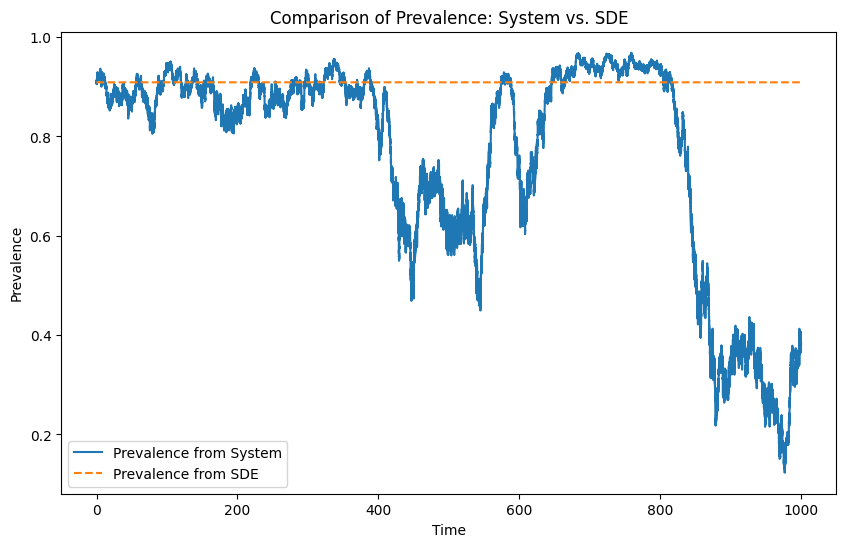

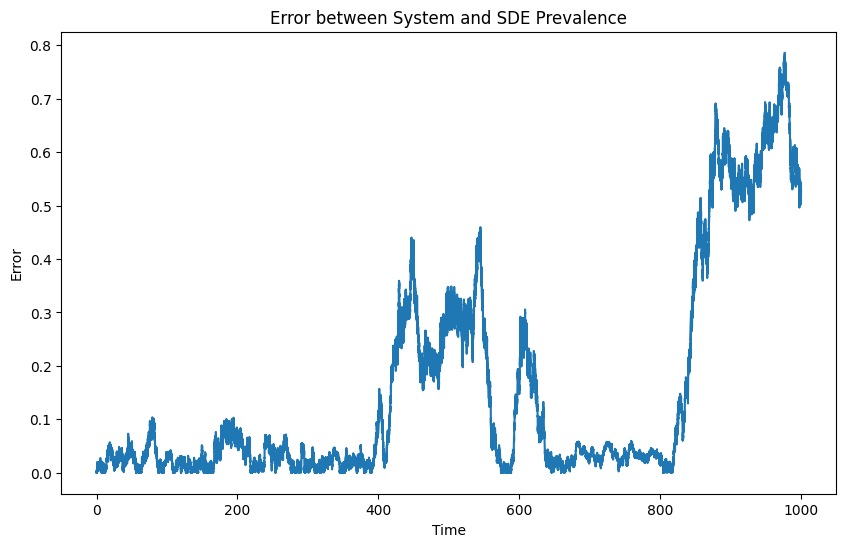

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define parameters
sigma_P = 0.1  # Volatility for P
sigma_Q = 0.1  # Volatility for Q
gamma_P = 0.5  # Parameter for P
gamma_Q = 0.5  # Parameter for Q
K = 1000       # Carrying capacity
lambda_P = 0.0 # Death rate for P
lambda_Q = 0.0 # Death rate for Q
rho_11 = 0.0   # Interaction term for P
rho_12 = 0.0   # Interaction term for Q
rho_21 = 0.0   # Interaction term for P
rho_22 = 0.0   # Interaction term for Q
P0 = 100         # Initial P
Q0 = 10         # Initial Q
T = 1000          # Total time
dt = 0.01       # Time step
N = int(T / dt) # Number of steps

# Initialize arrays
time = np.linspace(0, T, N)
P = np.zeros(N)
Q = np.zeros(N)
P[0] = P0
Q[0] = Q0

# Simulate P and Q based on the given system
for i in range(1, N):
    # Brownian increments for P and Q
    dW_P = np.random.normal(0, np.sqrt(dt))
    dW_Q = np.random.normal(0, np.sqrt(dt))

    # System equations for dP and dQ
    dP = ((rho_11 * P[i-1] + rho_12 * Q[i-1]) / (P[i-1] + Q[i-1]) * P[i-1] * (1 - (P[i-1] + Q[i-1]) / K) - lambda_P * P[i-1]) * dt + sigma_P * P[i-1] * dW_P
    dQ = ((rho_21 * P[i-1] + rho_22 * Q[i-1]) / (P[i-1] + Q[i-1]) * Q[i-1] * (1 - (P[i-1] + Q[i-1]) / K) - lambda_Q * Q[i-1]) * dt + sigma_Q * Q[i-1] * dW_Q

    # Update P and Q
    P[i] = P[i-1] + dP
    Q[i] = Q[i-1] + dQ

# Calculate prevalence from system
P_sys = P / (P + Q)

# Prevalence from SDE (numerically solve SDE for P(t))
# Assuming a simple Euler method for the SDE
sigma = sigma_Q * gamma_Q - sigma_P * gamma_P
P_SDE = np.zeros(N)
P_SDE[0] = P0 / (P0 + Q0)
for i in range(1, N):
    dW = np.random.normal(0, np.sqrt(dt))
    dP_SDE = sigma * P_SDE[i-1] * (1 - P_SDE[i-1]) * dW
    P_SDE[i] = P_SDE[i-1] + dP_SDE

# Calculate error between the two models
error = np.abs(P_sys - P_SDE)

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(time, P_sys, label="Prevalence from System")
plt.plot(time, P_SDE, label="Prevalence from SDE", linestyle='--')
plt.xlabel("Time")
plt.ylabel("Prevalence")
plt.legend()
plt.title("Comparison of Prevalence: System vs. SDE")
plt.show()

# Plot the error
plt.figure(figsize=(10, 6))
plt.plot(time, error)
plt.xlabel("Time")
plt.ylabel("Error")
plt.title("Error between System and SDE Prevalence")
plt.show()


In [ ]:
import sympy as sp

# Define symbolic variables
P, Q, t, rho_11, rho_12, rho_21, rho_22, S, K, lambda_P, lambda_Q, sigma_P, sigma_Q, mathcal_P = sp.symbols(
    'P Q t rho_11 rho_12 rho_21 rho_22 S K lambda_P lambda_Q sigma_P sigma_Q mathcal_P', positive=True
)

# Define b_P and b_Q
b_P = (
    (rho_11 * P + rho_12 * Q) / S * P * (1 - S / K) - lambda_P * P
)
b_Q = (
    (rho_21 * P + rho_22 * Q) / S * Q * (1 - S / K) - lambda_Q * Q
)

# Define l(P, Q)
l = (
    -2 * sigma_Q**2 * Q**2 / S**2
    + (sigma_P**2 * P**2 + sigma_Q**2 * Q**2) * (2 * Q / S**3)
)

# Drift term mu(mathcal_P)
mu_mathcal_P = (
    b_Q * P * mathcal_P - (b_P + b_Q) * Q * mathcal_P * (1 - mathcal_P) + P * Q * l
) / (P * Q)

# First derivative of mu with respect to mathcal_P
dmu_dmathcal_P = sp.diff(mu_mathcal_P, mathcal_P)

# Radius of curvature formula
R = ((1 + mu_mathcal_P**2)**(3/2)) / sp.Abs(dmu_dmathcal_P * mu_mathcal_P)

# Simplify the expression for better readability
R_simplified = sp.simplify(R)

R_simplified


(K**2*P**2*S**6 + (2*K*P*Q*(-P**2*sigma_P**2 - Q**2*sigma_Q**2 + Q*S*sigma_Q**2) + S**2*mathcal_P*(P*(K*S*lambda_Q - (K - S)*(P*rho_21 + Q*rho_22)) + (mathcal_P - 1)*(K*S*(P*lambda_P + Q*lambda_Q) - P*(K - S)*(P*rho_11 + Q*rho_12) - Q*(K - S)*(P*rho_21 + Q*rho_22))))**2)**1.5/(K**1.0*P**1.0*S**5.0*Abs((2*K*P*Q*(P**2*sigma_P**2 + Q**2*sigma_Q**2 - Q*S*sigma_Q**2) - S**2*mathcal_P*(P*(K*S*lambda_Q - (K - S)*(P*rho_21 + Q*rho_22)) - (mathcal_P - 1)*(-K*S*(P*lambda_P + Q*lambda_Q) + P*(K - S)*(P*rho_11 + Q*rho_12) + Q*(K - S)*(P*rho_21 + Q*rho_22))))*(-P*(K*S*lambda_Q - (K - S)*(P*rho_21 + Q*rho_22)) + mathcal_P*(-K*S*(P*lambda_P + Q*lambda_Q) + P*(K - S)*(P*rho_11 + Q*rho_12) + Q*(K - S)*(P*rho_21 + Q*rho_22)) + (mathcal_P - 1)*(-K*S*(P*lambda_P + Q*lambda_Q) + P*(K - S)*(P*rho_11 + Q*rho_12) + Q*(K - S)*(P*rho_21 + Q*rho_22)))))

In [ ]:
pip install matplotlib networkx


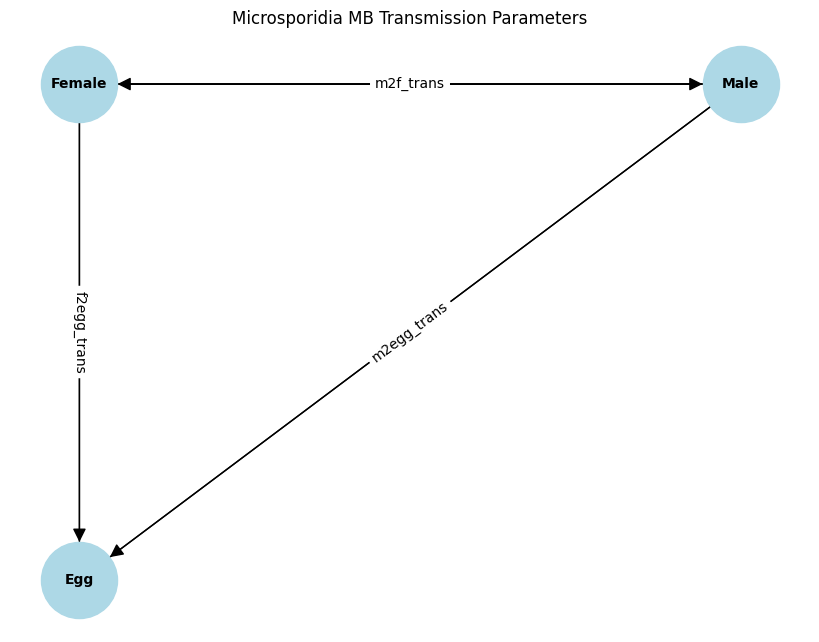

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

# Create a directed graph
G = nx.DiGraph()

# Add nodes for Female, Male, and Egg
G.add_node("Female", pos=(0, 1))  # Female node
G.add_node("Male", pos=(2, 1))    # Male node
G.add_node("Egg", pos=(0, -1))    # Egg node

# Add edges with labels for transmission rates
edges = [
    ("Female", "Male", "f2m_trans"),   # Female-to-Male
    ("Male", "Female", "m2f_trans"),   # Male-to-Female
    ("Female", "Egg", "f2egg_trans"),  # Female-to-Egg
    ("Male", "Egg", "m2egg_trans"),    # Male-to-Egg
]

# Add edges to the graph
for source, target, label in edges:
    G.add_edge(source, target, label=label)

# Extract positions
pos = nx.get_node_attributes(G, "pos")

# Set up the figure
plt.figure(figsize=(8, 6))

# Draw nodes
nx.draw(G, pos, with_labels=True, node_size=3000, node_color="lightblue",
        font_size=10, font_weight="bold", arrowsize=20)

# Draw edges
nx.draw_networkx_edges(G, pos, edgelist=G.edges(), arrowstyle='-|>', arrowsize=20)

# Add edge labels
edge_labels = {(u, v): d['label'] for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=10, label_pos=0.5)

# Add a title
plt.title("Microsporidia MB Transmission Parameters")

# Show the plot
plt.show()


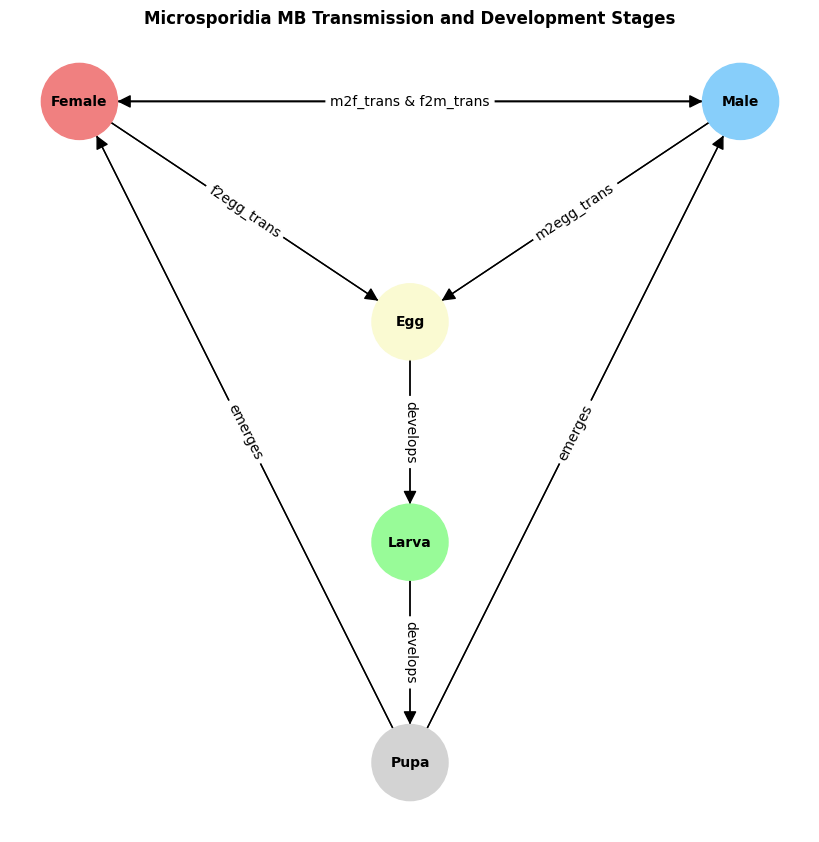

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

# Create a directed graph
G = nx.DiGraph()

# Add nodes for Adult stages and Immature stages
G.add_node("Female", pos=(0, 2))  # Female node
G.add_node("Male", pos=(2, 2))    # Male node
G.add_node("Egg", pos=(1, 1))     # Egg node
G.add_node("Larva", pos=(1, 0))   # Larva node
G.add_node("Pupa", pos=(1, -1))   # Pupa node

# Add edges with transmission parameters
edges = [
    ("Female", "Male", "f2m_trans"),    # Female-to-Male
    ("Male", "Female", "m2f_trans & f2m_trans"),    # Male-to-Female
    ("Female", "Egg", "f2egg_trans"),   # Female-to-Egg
    ("Male", "Egg", "m2egg_trans"),     # Male-to-Egg
    ("Egg", "Larva", "develops"),       # Egg-to-Larva
    ("Larva", "Pupa", "develops"),      # Larva-to-Pupa
    ("Pupa", "Female", "emerges"),      # Pupa-to-Female
    ("Pupa", "Male", "emerges"),        # Pupa-to-Male
]

# Add edges to the graph
for source, target, label in edges:
    G.add_edge(source, target, label=label)

# Define positions for nodes
pos = nx.get_node_attributes(G, "pos")

# Node colors
node_colors = {
    "Female": "lightcoral",
    "Male": "lightskyblue",
    "Egg": "lightgoldenrodyellow",
    "Larva": "palegreen",
    "Pupa": "lightgray"
}

# Set up the figure
plt.figure(figsize=(8, 8))

# Draw nodes with colors
node_list = G.nodes()
colors = [node_colors[node] for node in node_list]
nx.draw(G, pos, with_labels=True, node_size=3000, node_color=colors,
        font_size=10, font_weight="bold", arrowsize=20)

# Draw edges
nx.draw_networkx_edges(G, pos, edgelist=G.edges(), arrowstyle='-|>', arrowsize=20)

# Add edge labels
edge_labels = {(u, v): d['label'] for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=10, label_pos=0.5)

# Add a title
plt.title("Microsporidia MB Transmission and Development Stages", fontsize=12, fontweight="bold")

# Show the plot
plt.show()


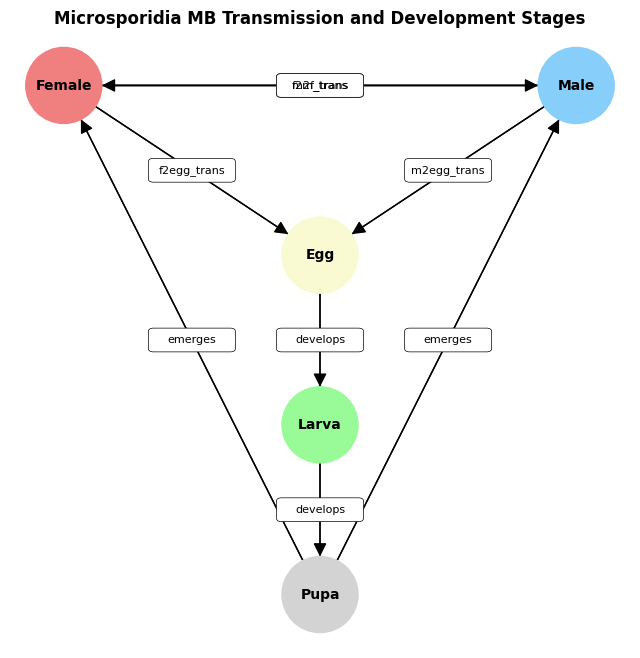

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import FancyBboxPatch

# Create a directed graph
G = nx.DiGraph()

# Add nodes for Adult stages and Immature stages
G.add_node("Female", pos=(0, 2))  # Female node
G.add_node("Male", pos=(2, 2))    # Male node
G.add_node("Egg", pos=(1, 1))     # Egg node
G.add_node("Larva", pos=(1, 0))   # Larva node
G.add_node("Pupa", pos=(1, -1))   # Pupa node

# Add edges with transmission parameters
edges = [
    ("Female", "Male", "f2m_trans"),           # Female-to-Male
    ("Male", "Female", "m2f_trans"),           # Male-to-Female
    ("Female", "Egg", "f2egg_trans"),          # Female-to-Egg
    ("Male", "Egg", "m2egg_trans"),            # Male-to-Egg
    ("Egg", "Larva", "develops"),              # Egg-to-Larva
    ("Larva", "Pupa", "develops"),             # Larva-to-Pupa
    ("Pupa", "Female", "emerges"),             # Pupa-to-Female
    ("Pupa", "Male", "emerges"),               # Pupa-to-Male
]

# Add edges to the graph
for source, target, label in edges:
    G.add_edge(source, target, label=label)

# Define positions for nodes
pos = nx.get_node_attributes(G, "pos")

# Node colors
node_colors = {
    "Female": "lightcoral",
    "Male": "lightskyblue",
    "Egg": "lightgoldenrodyellow",
    "Larva": "palegreen",
    "Pupa": "lightgray"
}

# Set up the figure
fig, ax = plt.subplots(figsize=(8, 8))

# Draw nodes with colors
node_list = G.nodes()
colors = [node_colors[node] for node in node_list]
nx.draw(G, pos, with_labels=True, node_size=3000, node_color=colors,
        font_size=10, font_weight="bold", arrowsize=20, ax=ax)

# Draw edges
nx.draw_networkx_edges(G, pos, edgelist=G.edges(), arrowstyle='-|>', arrowsize=20, ax=ax)

# Add edge labels with rectangular boxes
edge_labels = {(u, v): d['label'] for u, v, d in G.edges(data=True)}
for (u, v), label in edge_labels.items():
    x = (pos[u][0] + pos[v][0]) / 2  # Midpoint X
    y = (pos[u][1] + pos[v][1]) / 2  # Midpoint Y

    # Add a box behind the label
    patch = FancyBboxPatch(
        (x - 0.15, y - 0.05), 0.3, 0.1,
        boxstyle="round,pad=0.02",
        facecolor="white", edgecolor="black", linewidth=0.5
    )
    ax.add_patch(patch)
    # Add the label text on top of the box
    plt.text(x, y, label, fontsize=8, ha="center", va="center", zorder=5)

# Add a title
plt.title("Microsporidia MB Transmission and Development Stages", fontsize=12, fontweight="bold")

# Show the plot
plt.show()


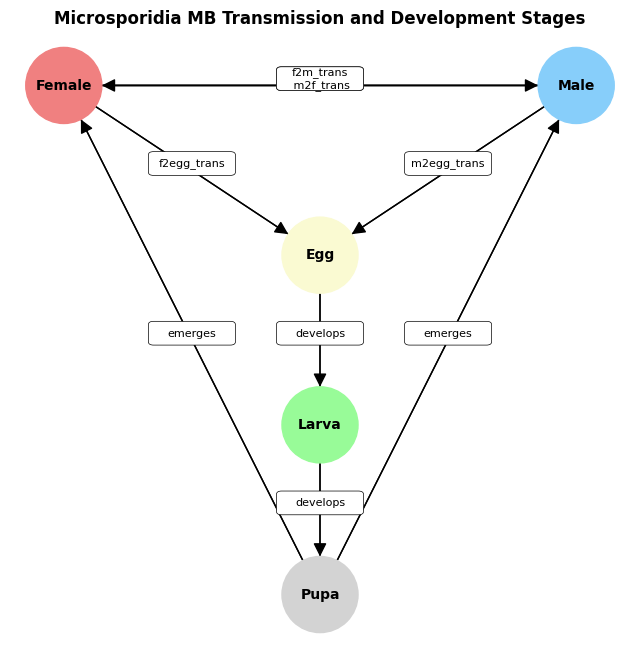

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import FancyBboxPatch

# Create a directed graph
G = nx.DiGraph()

# Add nodes for Adult stages and Immature stages
G.add_node("Female", pos=(0, 2))  # Female node
G.add_node("Male", pos=(2, 2))    # Male node
G.add_node("Egg", pos=(1, 1))     # Egg node
G.add_node("Larva", pos=(1, 0))   # Larva node
G.add_node("Pupa", pos=(1, -1))   # Pupa node

# Add edges with transmission parameters
edges = [
    ("Female", "Male", ""),           # Female-to-Male
    ("Male", "Female", "f2m_trans\n m2f_trans"),           # Male-to-Female
    ("Female", "Egg", "f2egg_trans"),          # Female-to-Egg
    ("Male", "Egg", "m2egg_trans"),            # Male-to-Egg
    ("Egg", "Larva", "develops"),              # Egg-to-Larva
    ("Larva", "Pupa", "develops"),             # Larva-to-Pupa
    ("Pupa", "Female", "emerges"),             # Pupa-to-Female
    ("Pupa", "Male", "emerges"),               # Pupa-to-Male
]

# Add edges to the graph
for source, target, label in edges:
    G.add_edge(source, target, label=label)

# Define positions for nodes
pos = nx.get_node_attributes(G, "pos")

# Node colors
node_colors = {
    "Female": "lightcoral",
    "Male": "lightskyblue",
    "Egg": "lightgoldenrodyellow",
    "Larva": "palegreen",
    "Pupa": "lightgray"
}

# Set up the figure
fig, ax = plt.subplots(figsize=(8, 8))

# Draw nodes with colors
node_list = G.nodes()
colors = [node_colors[node] for node in node_list]
nx.draw(G, pos, with_labels=True, node_size=3000, node_color=colors,
        font_size=10, font_weight="bold", arrowsize=20, ax=ax)

# Draw edges
nx.draw_networkx_edges(G, pos, edgelist=G.edges(), arrowstyle='-|>', arrowsize=20, ax=ax)

# Add edge labels with rectangular boxes
edge_labels = {(u, v): d['label'] for u, v, d in G.edges(data=True)}

# To handle label overlap, adjust the vertical position of the labels
label_offsets = {}

for (u, v), label in edge_labels.items():
    x = (pos[u][0] + pos[v][0]) / 2  # Midpoint X
    y = (pos[u][1] + pos[v][1]) / 2  # Midpoint Y

    # If the label already has an offset, increment it
    if (u, v) in label_offsets:
        label_offsets[(u, v)] += 0.1
    else:
        label_offsets[(u, v)] = 0.04

    # Adjust the Y position of the label to avoid overlap
    adjusted_y = y + label_offsets[(u, v)]

    # Add a box behind the label
    patch = FancyBboxPatch(
        (x - 0.15, adjusted_y - 0.05), 0.3, 0.1,
        boxstyle="round,pad=0.02",
        facecolor="white", edgecolor="black", linewidth=0.5
    )
    ax.add_patch(patch)
    # Add the label text on top of the box
    plt.text(x, adjusted_y, label, fontsize=8, ha="center", va="center", zorder=10)

# Add a title
plt.title("Microsporidia MB Transmission and Development Stages", fontsize=12, fontweight="bold")

# Show the plot
plt.show()


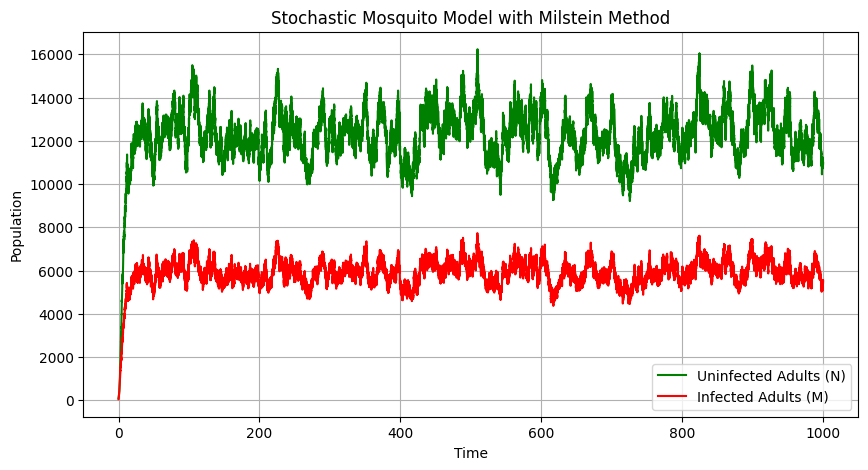

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Time parameters
T = 1000  # Total time
dt = 0.01  # Time step
N_steps = int(T / dt)  # Number of time steps

# Model parameters
b_N = 2.0
b_M = 1.8
lambda_A = 0.3
lambda_N = 0.2
lambda_M = 0.25
beta_A = 0.5
sigma_A = 0.1
sigma_N = 0.05
sigma_M = 0.07
K = 1000  # Carrying capacity

# Initial conditions
A0 = 300
N0 = 100
M0 = 50

# Initialize arrays
A = np.zeros(N_steps)
N = np.zeros(N_steps)
M = np.zeros(N_steps)

# Set initial values
A[0] = A0
N[0] = N0
M[0] = M0

# Function to compute growth rates
def rho_matrix(t):
    rho_11, rho_12 = 0.3, 0.2
    rho_21, rho_22 = 0.5, 0.7
    return np.array([[rho_11, rho_12], [rho_21, rho_22]])

# Simulate using the Milstein method
for t in range(1, N_steps):
    # Compute current values
    At, Nt, Mt = A[t-1], N[t-1], M[t-1]

    # Compute interaction terms
    rho = rho_matrix(t * dt)
    N_frac = Nt / (Nt + Mt) if (Nt + Mt) > 0 else 0
    M_frac = Mt / (Nt + Mt) if (Nt + Mt) > 0 else 0

    # Compute drift terms
    dA_dt = b_N * Nt + b_M * Mt - lambda_A * At
    dN_dt = (rho[0, 0] * N_frac + rho[0, 1] * M_frac) * Nt * (1 - (Nt + Mt) / K) - lambda_N * Nt + beta_A * At
    dM_dt = (rho[1, 0] * N_frac + rho[1, 1] * M_frac) * Mt * (1 - (Nt + Mt) / K) - lambda_M * Mt + beta_A * At

    # Compute diffusion terms
    dW_A = np.sqrt(dt) * np.random.randn()
    dW_N = np.sqrt(dt) * np.random.randn()
    dW_M = np.sqrt(dt) * np.random.randn()

    gA = sigma_A * At
    gN = sigma_N * Nt
    gM = sigma_M * Mt

    # Milstein correction terms
    gA_prime = sigma_A  # Assuming gA = sigma_A * A, so gA' = sigma_A
    gN_prime = sigma_N  # Assuming gN = sigma_N * N, so gN' = sigma_N
    gM_prime = sigma_M  # Assuming gM = sigma_M * M, so gM' = sigma_M

    # Milstein updates
    A[t] = At + dA_dt * dt + gA * dW_A + 0.5 * gA * gA_prime * (dW_A**2 - dt)
    N[t] = Nt + dN_dt * dt + gN * dW_N + 0.5 * gN * gN_prime * (dW_N**2 - dt)
    M[t] = Mt + dM_dt * dt + gM * dW_M + 0.5 * gM * gM_prime * (dW_M**2 - dt)

    # Ensure non-negative populations
    A[t] = max(A[t], 0)
    N[t] = max(N[t], 0)
    M[t] = max(M[t], 0)

# Plot the results
time = np.linspace(0, T, N_steps)
plt.figure(figsize=(10, 5))
# plt.plot(time, A, label="Aquatic Stage (A)", color='blue')
plt.plot(time, N, label="Uninfected Adults (N)", color='green')
plt.plot(time, M, label="Infected Adults (M)", color='red')
plt.xlabel("Time")
plt.ylabel("Population")
plt.title("Stochastic Mosquito Model with Milstein Method")
plt.legend()
plt.grid()
plt.show()


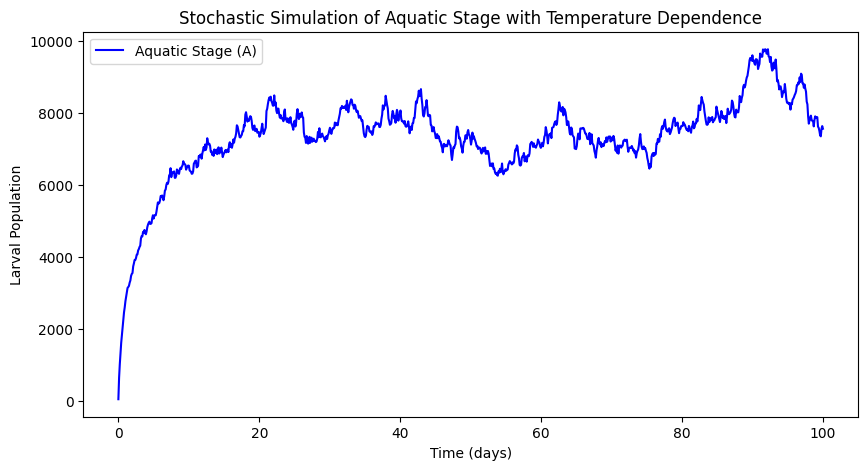

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
beta_max = 50    # Max oviposition rate (eggs per day)
T_opt = 27       # Optimal temperature (Celsius)
alpha = 0.02     # Temperature sensitivity
lambda_A = 0.1   # Larval mortality rate
K_A = 1000       # Carrying capacity for aquatic stage
sigma_A = 0.05   # Noise intensity
T = 30           # Current temperature

def beta_A(T):
    """Temperature-dependent oviposition rate."""
    return beta_max * np.exp(-alpha * (T - T_opt)**2)

# Stochastic Differential Equation
def dA(A, N, M, dt, dW):
    beta = beta_A(T)
    drift = (beta * (N + M) / (1 + A / K_A)) - lambda_A * A
    diffusion = sigma_A * A
    return drift * dt + diffusion * dW + 0.5 * sigma_A * (dW**2 - dt)

# Simulation Parameters
dt = 0.1  # Time step
T_sim = 100  # Simulation time
steps = int(T_sim / dt)

# Initial Conditions
A = np.zeros(steps)
A[0] = 50  # Initial larvae population
N, M = 100, 50  # Initial adult populations

# Milstein Simulation
np.random.seed(42)
for i in range(steps - 1):
    dW = np.random.normal(0, np.sqrt(dt))  # Wiener process
    A[i+1] = max(A[i] + dA(A[i], N, M, dt, dW), 0)  # Ensure non-negative A

# Plot Results
plt.figure(figsize=(10, 5))
plt.plot(np.linspace(0, T_sim, steps), A, label="Aquatic Stage (A)", color='b')
plt.xlabel("Time (days)")
plt.ylabel("Larval Population")
plt.title("Stochastic Simulation of Aquatic Stage with Temperature Dependence")
plt.legend()
plt.show()


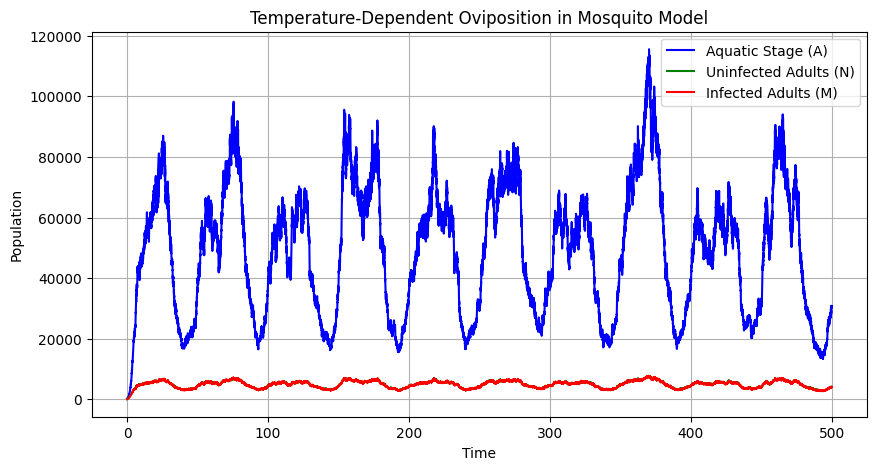

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Time parameters
T = 500  # Total time
dt = 0.01  # Time step
N_steps = int(T / dt)  # Number of time steps

# Mortality rates
lambda_A = 0.3
lambda_N = 0.2
lambda_M = 0.25
beta_A = 0.5
sigma_A = 0.1
sigma_N = 0.05
sigma_M = 0.07
K = 1000  # Carrying capacity

# Initial conditions
A0 = 300
N0 = 100
M0 = 50

# Initialize arrays
A = np.zeros(N_steps)
N = np.zeros(N_steps)
M = np.zeros(N_steps)

# Set initial values
A[0] = A0
N[0] = N0
M[0] = M0

# Function for temperature-dependent oviposition rate
def oviposition_rate(T):
    T_opt = 27  # Optimal temperature for oviposition
    return 2.0 * np.exp(-((T - T_opt) ** 2) / (2 * 5 ** 2))  # Gaussian response

# Function for temperature variation (sinusoidal for daily cycle)
def temperature(t):
    return 25 + 5 * np.sin(2 * np.pi * t / 50)  # Varies between 20 and 30°C

# Function to compute growth rates
def rho_matrix(t):
    rho_11, rho_12 = 0.8, 0.2
    rho_21, rho_22 = 0.3, 0.7
    return np.array([[rho_11, rho_12], [rho_21, rho_22]])

# Simulate using the Milstein method
for t in range(1, N_steps):
    # Current values
    At, Nt, Mt = A[t-1], N[t-1], M[t-1]

    # Compute current temperature and oviposition rate
    T_current = temperature(t * dt)
    b_N = oviposition_rate(T_current)
    b_M = 0.9 * b_N  # Assume infected mosquitoes lay slightly fewer eggs

    # Compute interaction terms
    rho = rho_matrix(t * dt)
    N_frac = Nt / (Nt + Mt) if (Nt + Mt) > 0 else 0
    M_frac = Mt / (Nt + Mt) if (Nt + Mt) > 0 else 0

    # Compute drift terms
    dA_dt = b_N * Nt + b_M * Mt - lambda_A * At
    dN_dt = (rho[0, 0] * N_frac + rho[0, 1] * M_frac) * Nt * (1 - (Nt + Mt) / K) - lambda_N * Nt + beta_A * At
    dM_dt = (rho[1, 0] * N_frac + rho[1, 1] * M_frac) * Mt * (1 - (Nt + Mt) / K) - lambda_M * Mt + beta_A * At

    # Compute diffusion terms
    dW_A = np.sqrt(dt) * np.random.randn()
    dW_N = np.sqrt(dt) * np.random.randn()
    dW_M = np.sqrt(dt) * np.random.randn()

    gA = sigma_A * At
    gN = sigma_N * Nt
    gM = sigma_M * Mt

    # Milstein correction terms
    gA_prime = sigma_A
    gN_prime = sigma_N
    gM_prime = sigma_M

    # Milstein updates
    A[t] = At + dA_dt * dt + gA * dW_A + 0.5 * gA * gA_prime * (dW_A**2 - dt)
    N[t] = Nt + dN_dt * dt + gN * dW_N + 0.5 * gN * gN_prime * (dW_N**2 - dt)
    M[t] = Mt + dM_dt * dt + gM * dW_M + 0.5 * gM * gM_prime * (dW_M**2 - dt)

    # Ensure non-negative populations
    A[t] = max(A[t], 0)
    N[t] = max(N[t], 0)
    M[t] = max(M[t], 0)

# Plot the results
time = np.linspace(0, T, N_steps)
plt.figure(figsize=(10, 5))
plt.plot(time, A, label="Aquatic Stage (A)", color='blue')
plt.plot(time, N, label="Uninfected Adults (N)", color='green')
plt.plot(time, M, label="Infected Adults (M)", color='red')
plt.xlabel("Time")
plt.ylabel("Population")
plt.title("Temperature-Dependent Oviposition in Mosquito Model")
plt.legend()
plt.grid()
plt.show()


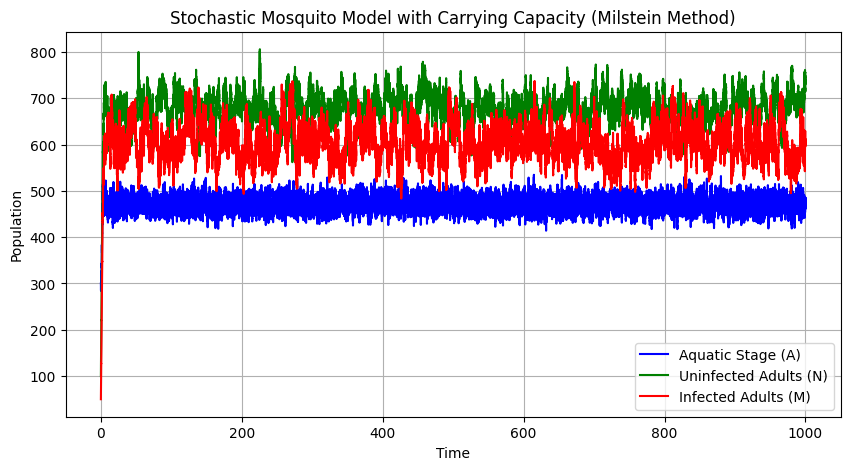

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Time parameters
T = 1000  # Total time
dt = 0.01  # Time step
N_steps = int(T / dt)  # Number of time steps

# Model parameters
b_N = 2.0  # Oviposition rate by uninfected adults
b_M = 1.8  # Oviposition rate by infected adults
lambda_A = 0.3  # Mortality rate of aquatic stage
lambda_N = 0.2  # Mortality rate of uninfected adults
lambda_M = 0.25  # Mortality rate of infected adults
beta_A = 0.5  # Emergence rate from aquatic stage
sigma_A = 0.1  # Noise intensity for A
sigma_N = 0.05  # Noise intensity for N
sigma_M = 0.07  # Noise intensity for M
K_A = 500  # Carrying capacity of aquatic stage
K = 1000  # Carrying capacity of adult population

# Initial conditions
A0 = 300
N0 = 100
M0 = 50

# Initialize arrays
A = np.zeros(N_steps)
N = np.zeros(N_steps)
M = np.zeros(N_steps)

# Set initial values
A[0] = A0
N[0] = N0
M[0] = M0

# Function to compute recruitment rates
def rho_matrix(t):
    rho_11, rho_12 = 0.8, 0.2
    rho_21, rho_22 = 0.3, 0.7
    return np.array([[rho_11, rho_12], [rho_21, rho_22]])

# Simulate using Milstein method
for t in range(1, N_steps):
    At, Nt, Mt = A[t-1], N[t-1], M[t-1]

    # Compute interaction terms
    rho = rho_matrix(t * dt)
    N_frac = Nt / (Nt + Mt) if (Nt + Mt) > 0 else 0
    M_frac = Mt / (Nt + Mt) if (Nt + Mt) > 0 else 0

    # Drift terms with carrying capacity constraints
    dA_dt = (b_N * Nt + b_M * Mt) * (1 - At / K_A) - lambda_A * At
    dN_dt = (rho[0, 0] * N_frac + rho[0, 1] * M_frac) * Nt * (1 - (Nt + Mt) / K) - lambda_N * Nt + beta_A * At
    dM_dt = (rho[1, 0] * N_frac + rho[1, 1] * M_frac) * Mt * (1 - (Nt + Mt) / K) - lambda_M * Mt + beta_A * At

    # Diffusion terms
    dW_A, dW_N, dW_M = np.sqrt(dt) * np.random.randn(3)
    gA, gN, gM = sigma_A * At, sigma_N * Nt, sigma_M * Mt

    # Milstein correction terms
    gA_prime, gN_prime, gM_prime = sigma_A, sigma_N, sigma_M

    # Milstein updates
    A[t] = At + dA_dt * dt + gA * dW_A + 0.5 * gA * gA_prime * (dW_A**2 - dt)
    N[t] = Nt + dN_dt * dt + gN * dW_N + 0.5 * gN * gN_prime * (dW_N**2 - dt)
    M[t] = Mt + dM_dt * dt + gM * dW_M + 0.5 * gM * gM_prime * (dW_M**2 - dt)

    # Ensure non-negative populations
    A[t] = max(A[t], 0)
    N[t] = max(N[t], 0)
    M[t] = max(M[t], 0)

# Plot the results
time = np.linspace(0, T, N_steps)
plt.figure(figsize=(10, 5))
plt.plot(time, A, label="Aquatic Stage (A)", color='blue')
plt.plot(time, N, label="Uninfected Adults (N)", color='green')
plt.plot(time, M, label="Infected Adults (M)", color='red')
plt.xlabel("Time")
plt.ylabel("Population")
plt.title("Stochastic Mosquito Model with Carrying Capacity (Milstein Method)")
plt.legend()
plt.grid()
plt.show()


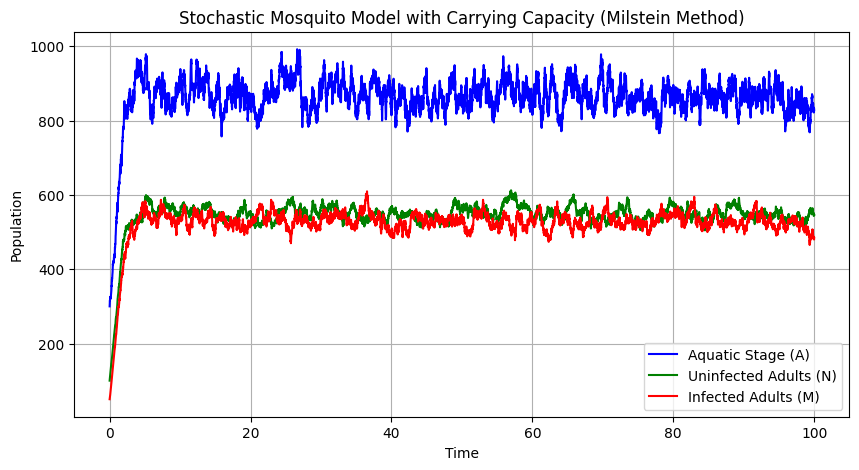

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Time parameters
T = 100  # Total time
dt = 0.01  # Time step
N_steps = int(T / dt)  # Number of time steps

# Model parameters
b_N = 2.0  # Oviposition rate by uninfected adults
b_M = 1.8  # Oviposition rate by infected adults
lambda_A = 0.3  # Mortality rate of aquatic stage
lambda_N = 0.2  # Mortality rate of uninfected adults
lambda_M = 0.25  # Mortality rate of infected adults
beta_A = 0.5  # Emergence rate from aquatic stage
sigma_A = 0.1  # Noise intensity for A
sigma_N = 0.05  # Noise intensity for N
sigma_M = 0.07  # Noise intensity for M
K_A = 1000  # Carrying capacity of aquatic stage
K = 500  # Carrying capacity of adult population

# Initial conditions
A0 = 300
N0 = 100
M0 = 50

# Initialize arrays
A = np.zeros(N_steps)
N = np.zeros(N_steps)
M = np.zeros(N_steps)

# Set initial values
A[0] = A0
N[0] = N0
M[0] = M0

# Function to compute recruitment rates
def rho_matrix(t):
    rho_11, rho_12 = 0.8, 0.2
    rho_21, rho_22 = 0.3, 0.7
    return np.array([[rho_11, rho_12], [rho_21, rho_22]])

# Simulate using Milstein method
for t in range(1, N_steps):
    At, Nt, Mt = A[t-1], N[t-1], M[t-1]

    # Compute interaction terms
    rho = rho_matrix(t * dt)
    N_frac = Nt / (Nt + Mt) if (Nt + Mt) > 0 else 0
    M_frac = Mt / (Nt + Mt) if (Nt + Mt) > 0 else 0

    # Drift terms with carrying capacity constraints
    dA_dt = (b_N * Nt + b_M * Mt) * (1 - At / K_A) - lambda_A * At
    dN_dt = (rho[0, 0] * N_frac + rho[0, 1] * M_frac) * Nt * (1 - (Nt + Mt) / K) - lambda_N * Nt + beta_A * At
    dM_dt = (rho[1, 0] * N_frac + rho[1, 1] * M_frac) * Mt * (1 - (Nt + Mt) / K) - lambda_M * Mt + beta_A * At

    # Diffusion terms
    dW_A, dW_N, dW_M = np.sqrt(dt) * np.random.randn(3)
    gA, gN, gM = sigma_A * At, sigma_N * Nt, sigma_M * Mt

    # Milstein correction terms
    gA_prime, gN_prime, gM_prime = sigma_A, sigma_N, sigma_M

    # Milstein updates
    A[t] = At + dA_dt * dt + gA * dW_A + 0.5 * gA * gA_prime * (dW_A**2 - dt)
    N[t] = Nt + dN_dt * dt + gN * dW_N + 0.5 * gN * gN_prime * (dW_N**2 - dt)
    M[t] = Mt + dM_dt * dt + gM * dW_M + 0.5 * gM * gM_prime * (dW_M**2 - dt)

    # Ensure non-negative populations
    A[t] = max(A[t], 0)
    N[t] = max(N[t], 0)
    M[t] = max(M[t], 0)

# Plot the results
time = np.linspace(0, T, N_steps)
plt.figure(figsize=(10, 5))
plt.plot(time, A, label="Aquatic Stage (A)", color='blue')
plt.plot(time, N, label="Uninfected Adults (N)", color='green')
plt.plot(time, M, label="Infected Adults (M)", color='red')
plt.xlabel("Time")
plt.ylabel("Population")
plt.title("Stochastic Mosquito Model with Carrying Capacity (Milstein Method)")
plt.legend()
plt.grid()
plt.show()


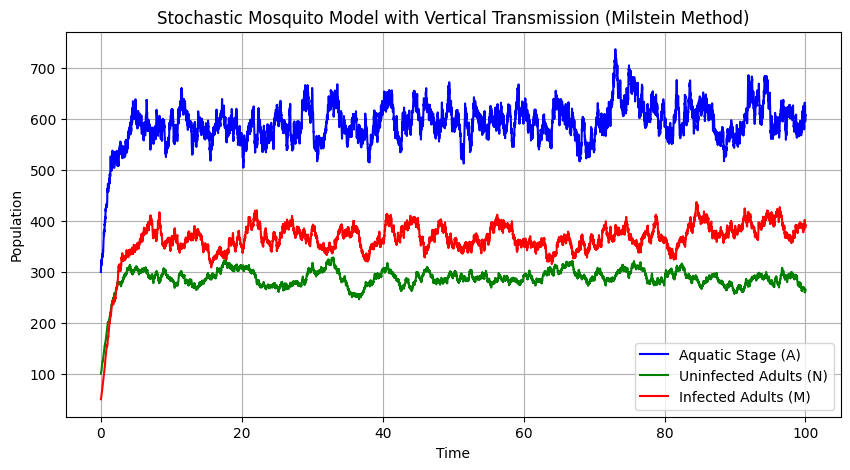

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Time parameters
T = 100  # Total time
dt = 0.01  # Time step
N_steps = int(T / dt)  # Number of time steps

# Model parameters
b_N = 2.0  # Oviposition rate by uninfected adults
b_M = 1.8  # Oviposition rate by infected adults
lambda_A = 0.3  # Mortality rate of aquatic stage
lambda_N = 0.2  # Mortality rate of uninfected adults
lambda_M = 0.25  # Mortality rate of infected adults
beta_A = 0.5  # Emergence rate from aquatic stage
sigma_A = 0.1  # Noise intensity for A
sigma_N = 0.05  # Noise intensity for N
sigma_M = 0.07  # Noise intensity for M
K_A = 700  # Carrying capacity of aquatic stage
K = 500  # Carrying capacity of adult population

# Vertical transmission rate (proportion of infected offspring from infected mothers)
alpha = 0.6  # 60% of offspring from infected mothers are infected

# Initial conditions
A0 = 300
N0 = 100
M0 = 50

# Initialize arrays
A = np.zeros(N_steps)
N = np.zeros(N_steps)
M = np.zeros(N_steps)

# Set initial values
A[0] = A0
N[0] = N0
M[0] = M0

# Function to compute recruitment rates
def rho_matrix(t):
    rho_11, rho_12 = 0.8, 0.6
    rho_21, rho_22 = 0.8, 0.7
    return np.array([[rho_11, rho_12], [rho_21, rho_22]])

# Simulate using Milstein method
for t in range(1, N_steps):
    At, Nt, Mt = A[t-1], N[t-1], M[t-1]

    # Compute interaction terms
    rho = rho_matrix(t * dt)
    N_frac = Nt / (Nt + Mt) if (Nt + Mt) > 0 else 0
    M_frac = Mt / (Nt + Mt) if (Nt + Mt) > 0 else 0

    # Drift terms with carrying capacity constraints and vertical transmission
    dA_dt = (b_N * Nt + b_M * Mt) * (1 - At / K_A) - lambda_A * At
    dN_dt = ((1 - alpha) * beta_A * At + (rho[0, 0] * N_frac + rho[0, 1] * M_frac) * Nt * (1 - (Nt + Mt) / K)) - lambda_N * Nt
    dM_dt = (alpha * beta_A * At + (rho[1, 0] * N_frac + rho[1, 1] * M_frac) * Mt * (1 - (Nt + Mt) / K)) - lambda_M * Mt

    # Diffusion terms
    dW_A, dW_N, dW_M = np.sqrt(dt) * np.random.randn(3)
    gA, gN, gM = sigma_A * At, sigma_N * Nt, sigma_M * Mt

    # Milstein correction terms
    gA_prime, gN_prime, gM_prime = sigma_A, sigma_N, sigma_M

    # Milstein updates
    A[t] = At + dA_dt * dt + gA * dW_A + 0.5 * gA * gA_prime * (dW_A**2 - dt)
    N[t] = Nt + dN_dt * dt + gN * dW_N + 0.5 * gN * gN_prime * (dW_N**2 - dt)
    M[t] = Mt + dM_dt * dt + gM * dW_M + 0.5 * gM * gM_prime * (dW_M**2 - dt)

    # Ensure non-negative populations
    A[t] = max(A[t], 0)
    N[t] = max(N[t], 0)
    M[t] = max(M[t], 0)

# Plot the results
time = np.linspace(0, T, N_steps)
plt.figure(figsize=(10, 5))
plt.plot(time, A, label="Aquatic Stage (A)", color='blue')
plt.plot(time, N, label="Uninfected Adults (N)", color='green')
plt.plot(time, M, label="Infected Adults (M)", color='red')
plt.xlabel("Time")
plt.ylabel("Population")
plt.title("Stochastic Mosquito Model with Vertical Transmission (Milstein Method)")
plt.legend()
plt.grid()
plt.show()


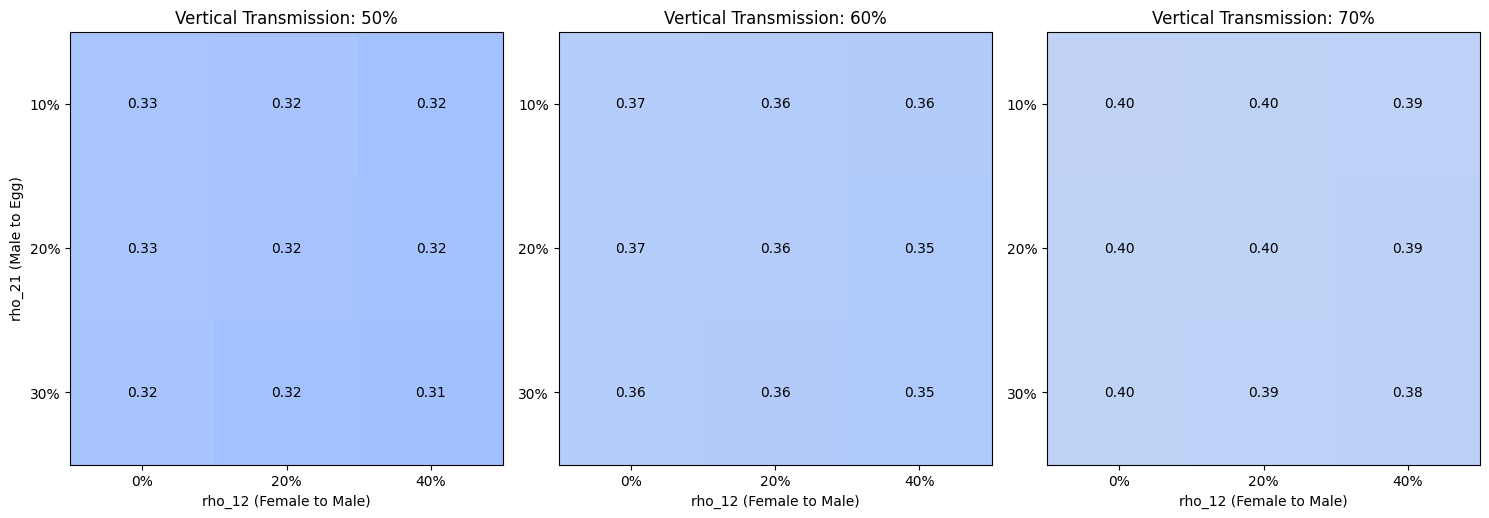

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation parameters
T = 100  # Total time
dt = 0.01  # Time step
N_steps = int(T / dt)  # Number of time steps
N_sim = 100  # Number of Monte Carlo simulations

# Model parameters
b_N = 2.0  # Oviposition rate by uninfected adults
b_M = 1.8  # Oviposition rate by infected adults
lambda_A = 0.3  # Mortality rate of aquatic stage
lambda_N = 0.2  # Mortality rate of uninfected adults
lambda_M = 0.25  # Mortality rate of infected adults
beta_A = 0.5  # Emergence rate from aquatic stage
sigma_A = 0.1  # Noise intensity for A
sigma_N = 0.05  # Noise intensity for N
sigma_M = 0.07  # Noise intensity for M
K_A = 500  # Carrying capacity of aquatic stage
K = 1000  # Carrying capacity of adult population

# Vertical transmission rates (Mother to Offspring)
vertical_transmission_values = [0.5, 0.6, 0.7]  # 50%, 60%, 70%

# Horizontal transmission values (rho_12, rho_21)
rho_12_values = [0.0, 0.2, 0.4]
rho_21_values = [0.1, 0.2, 0.3]

# Function to compute rho_matrix
def rho_matrix(rho_12, rho_21):
    rho_11, rho_22 = 1 - rho_12, 1 - rho_21
    return np.array([[rho_11, rho_12], [rho_21, rho_22]])

# Function to run Monte Carlo simulations and compute average prevalence
def compute_average_prevalence(alpha):
    prevalence_matrix = np.zeros((len(rho_21_values), len(rho_12_values)))

    for i, rho_21 in enumerate(rho_21_values):
        for j, rho_12 in enumerate(rho_12_values):
            rho = rho_matrix(rho_12, rho_21)
            prevalence_samples = []

            for _ in range(N_sim):
                # Initialize variables for a single simulation
                A, N, M = 300, 100, 50

                for _ in range(N_steps):
                    N_frac = N / (N + M) if (N + M) > 0 else 0
                    M_frac = M / (N + M) if (N + M) > 0 else 0

                    # Drift terms with carrying capacity constraints
                    dA_dt = (b_N * N + b_M * M) * (1 - A / K_A) - lambda_A * A
                    dN_dt = ((rho[0, 0] * N_frac + rho[0, 1] * M_frac) * N * (1 - (N + M) / K)
                             - lambda_N * N + beta_A * A)
                    dM_dt = ((rho[1, 0] * N_frac + rho[1, 1] * M_frac) * M * (1 - (N + M) / K)
                             - lambda_M * M + alpha * beta_A * A)

                    # Diffusion terms
                    dW_A, dW_N, dW_M = np.sqrt(dt) * np.random.randn(3)
                    gA, gN, gM = sigma_A * A, sigma_N * N, sigma_M * M

                    # Milstein updates
                    A += dA_dt * dt + gA * dW_A + 0.5 * sigma_A * gA * (dW_A**2 - dt)
                    N += dN_dt * dt + gN * dW_N + 0.5 * sigma_N * gN * (dW_N**2 - dt)
                    M += dM_dt * dt + gM * dW_M + 0.5 * sigma_M * gM * (dW_M**2 - dt)

                    # Ensure non-negative populations
                    A, N, M = max(A, 0), max(N, 0), max(M, 0)

                # Compute prevalence at final time step
                prevalence_samples.append(M / (N + M) if (N + M) > 0 else 0)

            prevalence_matrix[i, j] = np.mean(prevalence_samples)

    return prevalence_matrix

# Generate and plot heatmaps
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, alpha in enumerate(vertical_transmission_values):
    prevalence_matrix = compute_average_prevalence(alpha)
    ax = axes[idx]
    im = ax.imshow(prevalence_matrix, cmap='coolwarm', vmin=0, vmax=1)

    # Show prevalence values in each cell
    for i in range(len(rho_21_values)):
        for j in range(len(rho_12_values)):
            ax.text(j, i, f"{prevalence_matrix[i, j]:.2f}", ha='center', va='center', color='black')

    ax.set_xticks(np.arange(len(rho_12_values)))
    ax.set_yticks(np.arange(len(rho_21_values)))
    ax.set_xticklabels([f"{int(v * 100)}%" for v in rho_12_values])
    ax.set_yticklabels([f"{int(v * 100)}%" for v in rho_21_values])
    ax.set_xlabel("rho_12 (Female to Male)")
    if idx == 0:
        ax.set_ylabel("rho_21 (Male to Egg)")
    ax.set_title(f"Vertical Transmission: {int(alpha * 100)}%")

plt.tight_layout()
plt.show()


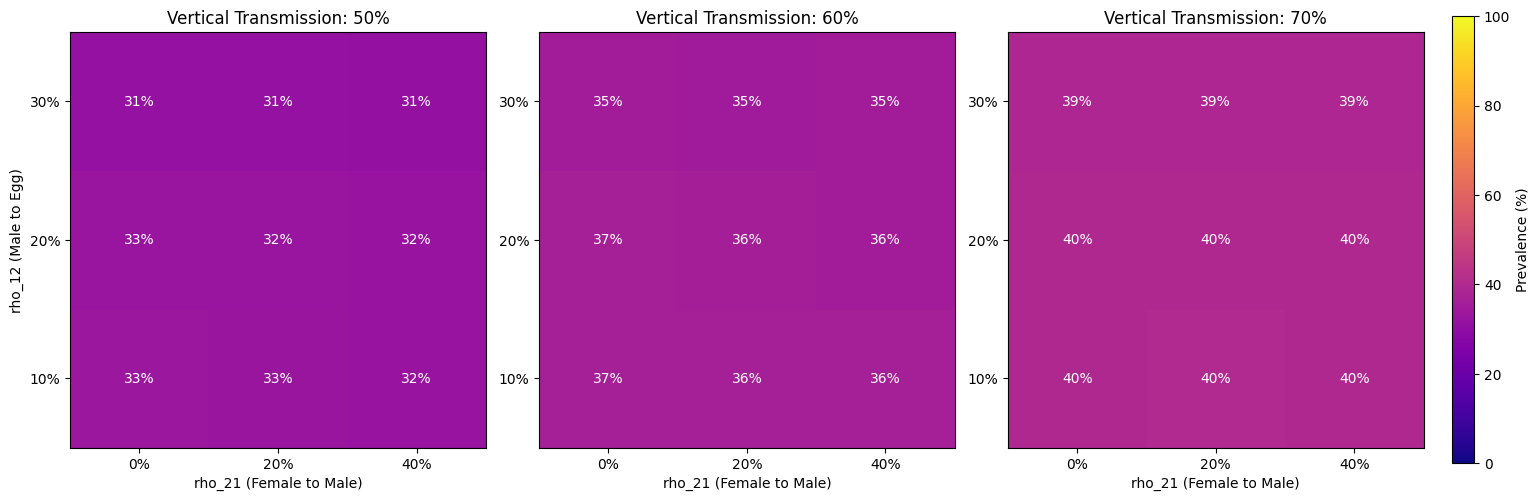

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation parameters
T = 100  # Total time
dt = 0.01  # Time step
N_steps = int(T / dt)  # Number of time steps
N_sim = 100  # Number of Monte Carlo simulations

# Model parameters
b_N = 2.0
b_M = 1.8
lambda_A = 0.3
lambda_N = 0.2
lambda_M = 0.25
beta_A = 0.5
sigma_A = 0.1
sigma_N = 0.05
sigma_M = 0.07
K_A = 500
K = 1000

# Transmission values
vertical_transmission_values = [0.5, 0.6, 0.7]
rho_21_values = [0.0, 0.2, 0.4]
rho_12_values = [0.1, 0.2, 0.3]

# Function to compute rho_matrix
def rho_matrix(rho_12, rho_21):
    return np.array([[1 - rho_12, rho_12], [rho_21, 1 - rho_21]])

# Function to run Monte Carlo simulations and compute prevalence
def compute_average_prevalence(alpha):
    prevalence_matrix = np.zeros((len(rho_21_values), len(rho_12_values)))

    for i, rho_21 in enumerate(rho_21_values):
        for j, rho_12 in enumerate(rho_12_values):
            rho = rho_matrix(rho_12, rho_21)
            prevalence_samples = []

            for _ in range(N_sim):
                A, N, M = 300, 100, 50

                for _ in range(N_steps):
                    N_frac = N / (N + M) if (N + M) > 0 else 0
                    M_frac = M / (N + M) if (N + M) > 0 else 0

                    # Drift terms
                    dA_dt = (b_N * N + b_M * M) * (1 - A / K_A) - lambda_A * A
                    dN_dt = ((rho[0, 0] * N_frac + rho[0, 1] * M_frac) * N * (1 - (N + M) / K)
                             - lambda_N * N + beta_A * A)
                    dM_dt = ((rho[1, 0] * N_frac + rho[1, 1] * M_frac) * M * (1 - (N + M) / K)
                             - lambda_M * M + alpha * beta_A * A)

                    # Diffusion terms
                    dW_A, dW_N, dW_M = np.sqrt(dt) * np.random.randn(3)
                    gA, gN, gM = sigma_A * A, sigma_N * N, sigma_M * M

                    # Milstein updates
                    A += dA_dt * dt + gA * dW_A + 0.5 * sigma_A * gA * (dW_A**2 - dt)
                    N += dN_dt * dt + gN * dW_N + 0.5 * sigma_N * gN * (dW_N**2 - dt)
                    M += dM_dt * dt + gM * dW_M + 0.5 * sigma_M * gM * (dW_M**2 - dt)

                    # Ensure non-negative populations
                    A, N, M = max(A, 0), max(N, 0), max(M, 0)

                # Compute prevalence
                prevalence_samples.append(M / (N + M) if (N + M) > 0 else 0)

            prevalence_matrix[i, j] = np.mean(prevalence_samples)

    return prevalence_matrix

# Generate heatmaps
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, alpha in enumerate(vertical_transmission_values):
    prevalence_matrix = compute_average_prevalence(alpha) * 100  # Convert to percentage
    ax = axes[idx]

    # Use "plasma" colormap for better color visibility
    im = ax.imshow(prevalence_matrix, cmap='plasma', vmin=0, vmax=100)

    # Show integer percentage values inside the heatmap
    for i in range(len(rho_21_values)):
        for j in range(len(rho_12_values)):
            ax.text(j, i, f"{int(round(prevalence_matrix[i, j]))}%", ha='center', va='center', color='white', fontsize=10)

    # Adjust axis labels
    ax.set_xticks(np.arange(len(rho_12_values)))
    ax.set_yticks(np.arange(len(rho_21_values)))
    ax.set_xticklabels([f"{int(v * 100)}%" for v in rho_21_values])
    ax.set_yticklabels([f"{int(v * 100)}%" for v in rho_12_values])

    # Invert y-axis so small values are at the bottom
    ax.invert_yaxis()

    ax.set_xlabel("rho_21 (Female to Male)")
    if idx == 0:
        ax.set_ylabel("rho_12 (Male to Egg)")
    ax.set_title(f"Vertical Transmission: {int(alpha * 100)}%")

# Adjust layout and show colorbar
plt.tight_layout()
cbar = fig.colorbar(im, ax=axes, orientation='vertical', fraction=0.02, pad=0.02)
cbar.set_label("Prevalence (%)")
plt.show()


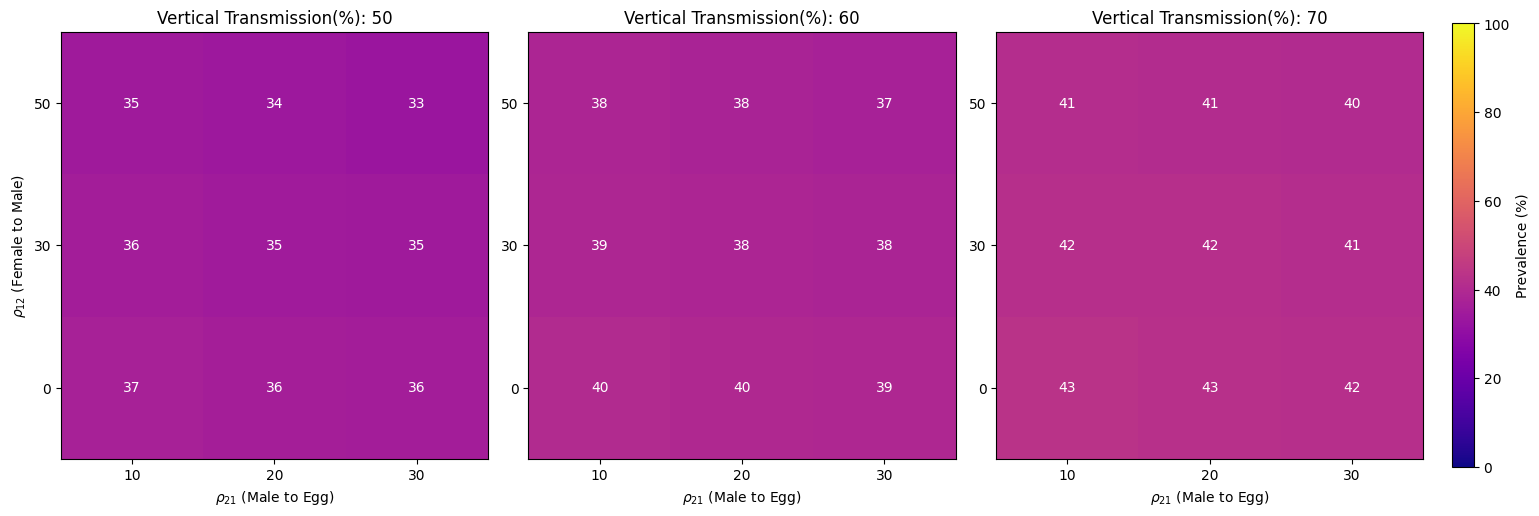

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(77)
# Simulation parameters
T = 100
dt = 0.01
N_steps = int(T / dt)
N_sim = 100

# Model parameters
b_N = 2.0
b_M = 1.8
lambda_A = 0.3
lambda_N = 0.2
lambda_M = 0.25
beta_A = 0.5
sigma_A = 0.1
sigma_N = 0.05
sigma_M = 0.07
K_A = 1000
K = 800

# Transmission values
vertical_transmission_values = [0.5, 0.6, 0.7]
rho_12_values = [0, 0.3, 0.5]  # Now on Y-axis
rho_21_values = [0.1, 0.2, 0.3]  # Now on X-axis

# Function to compute rho_matrix
def rho_matrix(rho_12, rho_21):
    return np.array([[1 - rho_12, rho_12], [rho_21, 1 - rho_21]])

# Function to run Monte Carlo simulations and compute prevalence
def compute_average_prevalence(alpha):
    prevalence_matrix = np.zeros((len(rho_12_values), len(rho_21_values)))

    for i, rho_12 in enumerate(rho_12_values):
        for j, rho_21 in enumerate(rho_21_values):
            rho = rho_matrix(rho_12, rho_21)
            prevalence_samples = []

            for _ in range(N_sim):
                A, N, M = 300, 100, 50

                for _ in range(N_steps):
                    N_frac = N / (N + M) if (N + M) > 0 else 0
                    M_frac = M / (N + M) if (N + M) > 0 else 0

                    # Drift terms
                    dA_dt = (b_N * N + b_M * M) * (1 - A / K_A) - lambda_A * A
                    dN_dt = ((rho[0, 0] * N_frac + rho[0, 1] * M_frac) * N * (1 - (N + M) / K)
                             - lambda_N * N + beta_A * A)
                    dM_dt = ((rho[1, 0] * N_frac + rho[1, 1] * M_frac) * M * (1 - (N + M) / K)
                             - lambda_M * M + alpha * beta_A * A)

                    # Diffusion terms
                    dW_A, dW_N, dW_M = np.sqrt(dt) * np.random.randn(3)
                    gA, gN, gM = sigma_A * A, sigma_N * N, sigma_M * M

                    # Milstein updates
                    A += dA_dt * dt + gA * dW_A + 0.5 * sigma_A * gA * (dW_A**2 - dt)
                    N += dN_dt * dt + gN * dW_N + 0.5 * sigma_N * gN * (dW_N**2 - dt)
                    M += dM_dt * dt + gM * dW_M + 0.5 * sigma_M * gM * (dW_M**2 - dt)

                    # Ensure non-negative populations
                    A, N, M = max(A, 0), max(N, 0), max(M, 0)

                # Compute prevalence
                prevalence_samples.append(M / (N + M) if (N + M) > 0 else 0)

            prevalence_matrix[i, j] = np.mean(prevalence_samples)

    return prevalence_matrix

# Generate heatmaps
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, alpha in enumerate(vertical_transmission_values):
    prevalence_matrix = compute_average_prevalence(alpha) * 100  # Convert to percentage
    ax = axes[idx]

    # Use "plasma" colormap for better visibility
    im = ax.imshow(prevalence_matrix, cmap='plasma', vmin=0, vmax=100)

    # Show integer percentage values inside the heatmap
    for i in range(len(rho_12_values)):
        for j in range(len(rho_21_values)):
            # ax.text(j, i, f"{int(round(prevalence_matrix[i, j]))}%", ha='center', va='center', color='white', fontsize=10)
            ax.text(j, i, f"{int(round(prevalence_matrix[i, j]))}", ha='center', va='center', color='white', fontsize=10)

    # Adjust axis labels
    ax.set_xticks(np.arange(len(rho_21_values)))
    ax.set_yticks(np.arange(len(rho_12_values)))
    # ax.set_xticklabels([f"{int(v * 100)}%" for v in rho_21_values])  # X-axis: rho_21
    # ax.set_yticklabels([f"{int(v * 100)}%" for v in rho_12_values])  # Y-axis: rho_12
    ax.set_xticklabels([f"{int(v * 100)}" for v in rho_21_values])  # X-axis: rho_21
    ax.set_yticklabels([f"{int(v * 100)}" for v in rho_12_values])  # Y-axis: rho_12

    # Ensure rho_12 runs from small to large (top to bottom)
    ax.invert_yaxis()

    ax.set_xlabel("$\\rho_{21}$ (Male to Egg)")
    if idx == 0:
        ax.set_ylabel("$\\rho_{12}$ (Female to Male)")
    # ax.set_title(f"Vertical Transmission: {int(alpha * 100)}%")
    ax.set_title(f"Vertical Transmission(%): {int(alpha * 100)}")

# Adjust layout and show colorbar
plt.tight_layout()
cbar = fig.colorbar(im, ax=axes, orientation='vertical', fraction=0.02, pad=0.02)
cbar.set_label("Prevalence (%)")
plt.show()


In [ ]:
# Step 1: Upload the TIF file
from google.colab import files
from PIL import Image

print("Please upload your .tif file (e.g., AEZ.tif)...")
uploaded = files.upload()

# Step 2: Convert to PNG and PDF
tif_filename = next(iter(uploaded))  # Get the name of the uploaded file
img = Image.open(tif_filename)

# Save as PNG
png_filename = tif_filename.replace('.tif', '_converted.png')
img.save(png_filename)

# Save as PDF
pdf_filename = tif_filename.replace('.tif', '_converted.pdf')
img.save(pdf_filename, "PDF", resolution=100.0)

print(f"✅ Conversion complete!\n- PNG: {png_filename}\n- PDF: {pdf_filename}")

# Step 3: Download the files
files.download(png_filename)
files.download(pdf_filename)


Please upload your .tif file (e.g., AEZ.tif)...


Saving AEZ.tif to AEZ.tif
✅ Conversion complete!
- PNG: AEZ_converted.png
- PDF: AEZ_converted.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

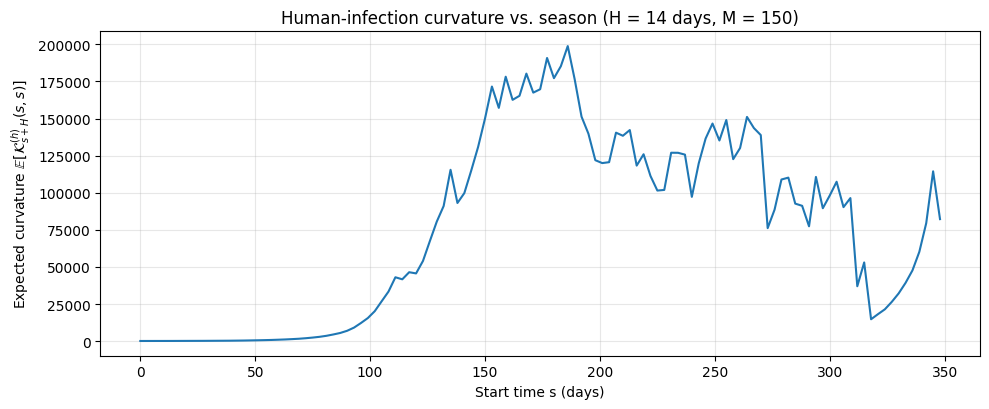

In [ ]:
# Stabilize the demo: smaller human noise, shorter horizon, and guard against extreme exponentials.

import numpy as np
import matplotlib.pyplot as plt

# Reuse previous settings but tweak a few
T_days = 365
h = 1.0
N = int(T_days / h)
tgrid = np.arange(N+1) * h

a_bar = 0.25
eps_season = 0.3
yr = 365.0

b_h, b_v = 0.2, 0.3
gamma = 1/14.0
nu = 1/10.0
mu_v = 1/10.0

sigma_a = 0.15
sigma_h = 0.10   # smaller to reduce extreme exponentials
sigma_v = 0.20

I0 = 0.05
Ev0 = 0.05
Iv0 = 0.05
Z0 = 1.0

M = 150
rng = np.random.default_rng(11)

H_days = 14.0
H_steps = int(H_days / h)

s_indices = np.arange(0, N - H_steps, 3)
EK_s_accum = np.zeros_like(s_indices, dtype=float)
EK_s_count = np.zeros_like(s_indices, dtype=int)

def seasonal_a(t, Z):
    return a_bar * (1.0 + eps_season * np.cos(2.0 * np.pi * t / yr)) * Z

for m in range(M):
    dWa = rng.normal(0.0, np.sqrt(h), size=N)
    dWh = rng.normal(0.0, np.sqrt(h), size=N)
    dWv = rng.normal(0.0, np.sqrt(h), size=N)

    I = np.empty(N+1); I[0] = I0
    Ev = np.empty(N+1); Ev[0] = Ev0
    Iv = np.empty(N+1); Iv[0] = Iv0
    Z = np.empty(N+1); Z[0] = Z0

    for n in range(N):
        t = tgrid[n]
        a_t = seasonal_a(t, Z[n])

        mu_I = a_t * b_h * Iv[n] * (1.0 - I[n]) - gamma * I[n]
        mu_Ev = a_t * b_v * I[n] * (1.0 - Ev[n] - Iv[n]) - nu * Ev[n]
        mu_Iv = nu * Ev[n] - mu_v * Iv[n]

        sig_I = sigma_h * I[n] * (1.0 - I[n])
        sig_Iv = sigma_v * Iv[n] * (1.0 - Iv[n])

        I[n+1]  = I[n]  + mu_I * h  + sig_I  * dWh[n]
        Ev[n+1] = Ev[n] + mu_Ev * h
        Iv[n+1] = Iv[n] + mu_Iv * h + sig_Iv * dWv[n]

        I[n+1]  = np.clip(I[n+1], 0.0, 1.0)
        Ev[n+1] = np.clip(Ev[n+1], 0.0, 1.0)
        Iv[n+1] = np.clip(Iv[n+1], 0.0, 1.0)

        Z[n+1] = Z[n] + sigma_a * Z[n] * dWa[n]
        if Z[n+1] <= 0:
            Z[n+1] = 1e-6

    for idx, k in enumerate(s_indices):
        k = int(k)
        t_end = k + H_steps
        if t_end > N:
            continue

        denom = sigma_h * I[k] * (1.0 - I[k])
        if denom <= 1e-8:
            continue

        J = 0.0
        J_partial = 0.0
        DsJ_drift_sum = 0.0
        DsJ_mart_sum = 0.0
        DsJ_initial = sigma_h * (1.0 - 2.0 * I[k])
        clip_thresh = 30.0  # guard

        skip = False
        for n in range(k, t_end):
            t = tgrid[n]
            a_t = seasonal_a(t, Z[n])
            mu_I_x = - a_t * b_h * Iv[n] - gamma
            sigma_I_x = sigma_h * (1.0 - 2.0 * I[n])
            lam = mu_I_x - 0.5 * (sigma_I_x**2)

            J_step = lam * h + sigma_I_x * dWh[n]
            J += J_step

            if abs(J_partial) < clip_thresh:
                DsI_n = sigma_h * I[k] * (1.0 - I[k]) * np.exp(J_partial)
            else:
                skip = True
                break

            a_coeff = 2.0 * (sigma_h**2) * (1.0 - 2.0 * I[n])
            b_coeff = -2.0 * sigma_h

            DsJ_drift_sum += a_coeff * DsI_n * h
            DsJ_mart_sum  += b_coeff * DsI_n * dWh[n]

            J_partial += J_step

        if skip or abs(J) > clip_thresh:
            continue

        DsJ = DsJ_initial + DsJ_drift_sum + DsJ_mart_sum
        K = (sigma_h * (1.0 - 2.0 * I[k]) + DsJ) / denom * np.exp(-J)

        if np.isfinite(K) and abs(K) < 1e6:  # discard extreme outliers for demo
            EK_s_accum[idx] += K
            EK_s_count[idx] += 1

EK_s = np.where(EK_s_count > 0, EK_s_accum / EK_s_count, np.nan)
s_times = tgrid[s_indices]

plt.figure(figsize=(10,4.2))
plt.plot(s_times, EK_s, lw=1.5)
plt.xlabel("Start time s (days)")
plt.ylabel(r"Expected curvature $\mathbb{E}[\mathcal{K}^{(h)}_{s+H}(s,s)]$")
plt.title(f"Human-infection curvature vs. season (H = {H_days:.0f} days, M = {M})")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


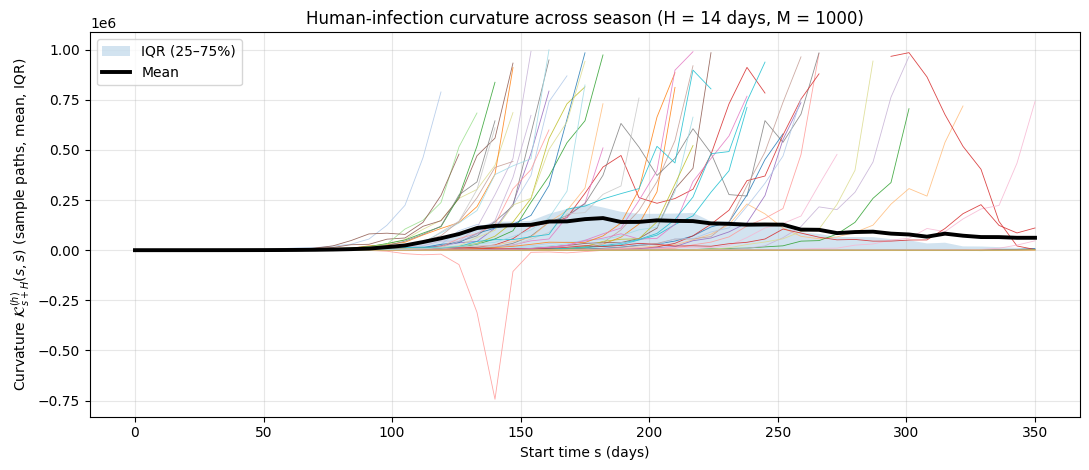

In [ ]:
# Retry execution with the same code. If this still fails due to environment reset,
# we will keep the code ready for the user to run locally as well.

import numpy as np
import matplotlib.pyplot as plt

# ------------------------
# Parameters
# ------------------------
T_days = 365
h = 1.0
N = int(T_days / h)
tgrid = np.arange(N+1) * h

# Seasonal/biological params
a_bar = 0.25
eps_season = 0.3
yr = 365.0

b_h, b_v = 0.2, 0.3
gamma = 1/14.0
nu = 1/10.0
mu_v = 1/10.0

# Noise intensities
sigma_a = 0.15
sigma_h = 0.10
sigma_v = 0.20

# Initial conditions
I0 = 0.05
Ev0 = 0.05
Iv0 = 0.05
Z0 = 1.0

# Monte Carlo
M = 1000
rng = np.random.default_rng(123)

# Curvature horizon
H_days = 14.0
H_steps = int(H_days / h)

# Evaluate s about weekly
s_indices = np.arange(0, N - H_steps, 7)
S = len(s_indices)

# Storage of curvature per path and s
K_paths = np.full((M, S), np.nan, dtype=float)

def seasonal_a(t, Z):
    return a_bar * (1.0 + eps_season * np.cos(2.0 * np.pi * t / yr)) * Z

# ------------------------
# Monte Carlo loop
# ------------------------
clip_thresh = 30.0

for m in range(M):
    dWa = rng.normal(0.0, np.sqrt(h), size=N)
    dWh = rng.normal(0.0, np.sqrt(h), size=N)
    dWv = rng.normal(0.0, np.sqrt(h), size=N)

    I = np.empty(N+1); I[0] = I0
    Ev = np.empty(N+1); Ev[0] = Ev0
    Iv = np.empty(N+1); Iv[0] = Iv0
    Z = np.empty(N+1); Z[0] = Z0

    # Forward simulate
    for n in range(N):
        t = tgrid[n]
        a_t = seasonal_a(t, Z[n])

        mu_I = a_t * b_h * Iv[n] * (1.0 - I[n]) - gamma * I[n]
        mu_Ev = a_t * b_v * I[n] * (1.0 - Ev[n] - Iv[n]) - nu * Ev[n]
        mu_Iv = nu * Ev[n] - mu_v * Iv[n]

        sig_I = sigma_h * I[n] * (1.0 - I[n])
        sig_Iv = sigma_v * Iv[n] * (1.0 - Iv[n])

        I[n+1]  = I[n]  + mu_I * h  + sig_I  * dWh[n]
        Ev[n+1] = Ev[n] + mu_Ev * h
        Iv[n+1] = Iv[n] + mu_Iv * h + sig_Iv * dWv[n]

        I[n+1]  = np.clip(I[n+1], 0.0, 1.0)
        Ev[n+1] = np.clip(Ev[n+1], 0.0, 1.0)
        Iv[n+1] = np.clip(Iv[n+1], 0.0, 1.0)

        Z[n+1] = Z[n] + sigma_a * Z[n] * dWa[n]
        if Z[n+1] <= 0:
            Z[n+1] = 1e-6

    # Curvature for each s
    for j, k in enumerate(s_indices):
        k = int(k)
        t_end = k + H_steps
        if t_end > N:
            continue

        denom = sigma_h * I[k] * (1.0 - I[k])
        if denom <= 1e-8:
            continue

        J = 0.0
        J_partial = 0.0
        DsJ_drift_sum = 0.0
        DsJ_mart_sum = 0.0
        DsJ_initial = sigma_h * (1.0 - 2.0 * I[k])

        skip = False
        for n in range(k, t_end):
            t = tgrid[n]
            a_t = seasonal_a(t, Z[n])
            mu_I_x = - a_t * b_h * Iv[n] - gamma
            sigma_I_x = sigma_h * (1.0 - 2.0 * I[n])
            lam = mu_I_x - 0.5 * (sigma_I_x**2)

            J_step = lam * h + sigma_I_x * dWh[n]
            J += J_step

            if abs(J_partial) < clip_thresh:
                DsI_n = sigma_h * I[k] * (1.0 - I[k]) * np.exp(J_partial)
            else:
                skip = True
                break

            a_coeff = 2.0 * (sigma_h**2) * (1.0 - 2.0 * I[n])
            b_coeff = -2.0 * sigma_h

            DsJ_drift_sum += a_coeff * DsI_n * h
            DsJ_mart_sum  += b_coeff * DsI_n * dWh[n]

            J_partial += J_step

        if skip or abs(J) > clip_thresh:
            continue

        DsJ = DsJ_initial + DsJ_drift_sum + DsJ_mart_sum
        K = (sigma_h * (1.0 - 2.0 * I[k]) + DsJ) / denom * np.exp(-J)

        if np.isfinite(K) and abs(K) < 1e6:
            K_paths[m, j] = K

# ------------------------
# Visualization
# ------------------------
s_times = tgrid[s_indices]

# Mean and IQR (ignore NaNs)
EK = np.nanmean(K_paths, axis=0)
Q1 = np.nanpercentile(K_paths, 25, axis=0)
Q3 = np.nanpercentile(K_paths, 75, axis=0)

# Choose subset of paths to display (multicolor)
show_m = min(60, M)  # 60 sample paths for richer view
colors = plt.cm.tab20(np.linspace(0, 1, 20))

plt.figure(figsize=(11, 4.8))

# IQR band
plt.fill_between(s_times, Q1, Q3, alpha=0.2, label='IQR (25–75%)')

# sample paths
for i in range(show_m):
    c = colors[i % 20]
    plt.plot(s_times, K_paths[i], lw=0.6, alpha=0.85, color=c)

# mean
plt.plot(s_times, EK, lw=2.8, color='k', label='Mean')

plt.xlabel("Start time s (days)")
plt.ylabel(r"Curvature $\mathcal{K}^{(h)}_{s+H}(s,s)$ (sample paths, mean, IQR)")
plt.title(f"Human-infection curvature across season (H = {H_days:.0f} days, M = {M})")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


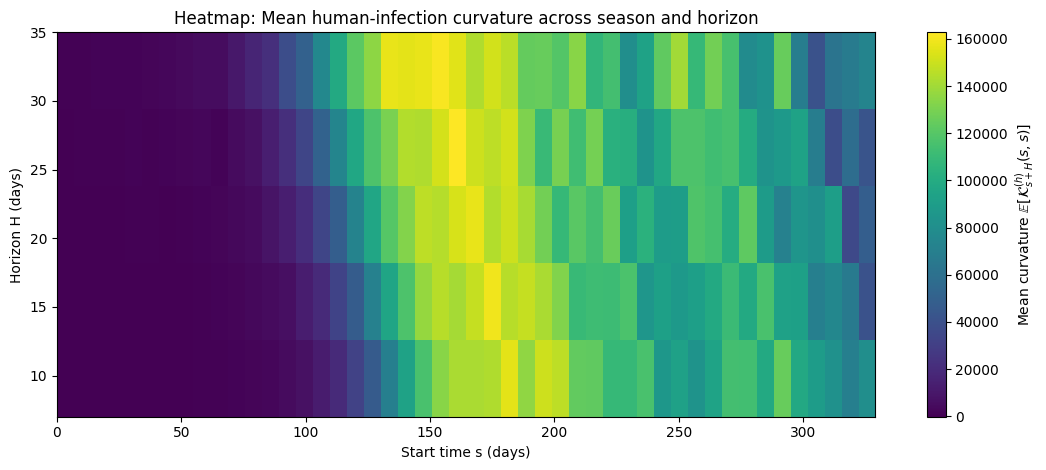

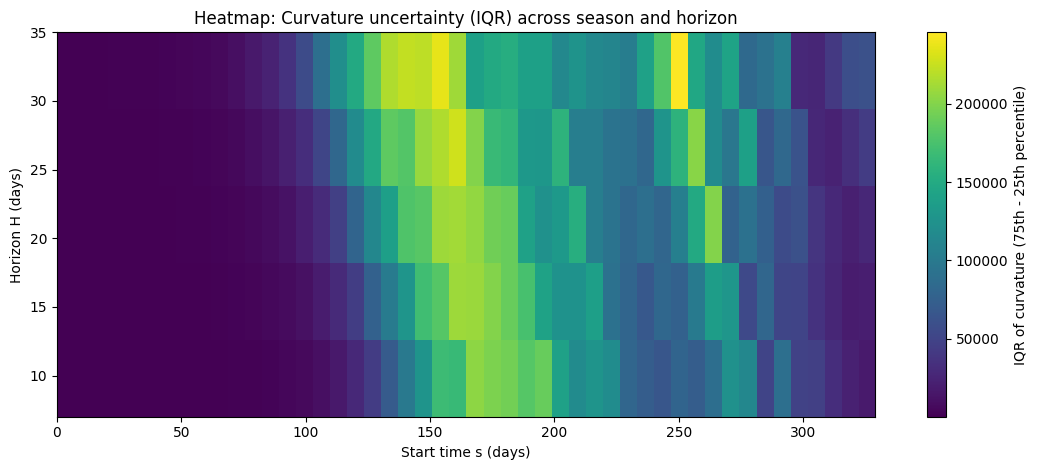

In [ ]:
# Heatmaps of expected human-infection curvature E[K_{s+H}^{(h)}(s,s)]
# across start time s (x-axis) and horizon H (y-axis).

import numpy as np
import matplotlib.pyplot as plt

# ------------------------
# Parameters
# ------------------------
T_days = 365
h = 1.0
N = int(T_days / h)
tgrid = np.arange(N+1) * h

# Seasonal/biological params
a_bar = 0.25
eps_season = 0.3
yr = 365.0

b_h, b_v = 0.2, 0.3
gamma = 1/14.0
nu = 1/10.0
mu_v = 1/10.0

# Noise intensities
sigma_a = 0.15
sigma_h = 0.10
sigma_v = 0.20

# Initial conditions
I0 = 0.05
Ev0 = 0.05
Iv0 = 0.05
Z0 = 1.0

# Monte Carlo
M = 400                      # keep moderate for runtime
rng = np.random.default_rng(2025)

# Horizons (days) and start indices (weekly)
H_list = np.array([7, 14, 21, 28, 35], dtype=float)
H_steps_list = (H_list / h).astype(int)
s_indices = np.arange(0, N - int(H_list.max()/h), 7)  # weekly starts
S = len(s_indices)
R = len(H_steps_list)

# Storage
K_mean = np.zeros((R, S), dtype=float)
K_q1   = np.zeros((R, S), dtype=float)
K_q3   = np.zeros((R, S), dtype=float)

def seasonal_a(t, Z):
    return a_bar * (1.0 + eps_season * np.cos(2.0 * np.pi * t / yr)) * Z

# ------------------------
# Monte Carlo: simulate all paths, then compute K for each (H,s)
# ------------------------
clip_thresh = 30.0

# Pre-allocate per-path storage of curvature values to compute quantiles
K_paths = np.full((M, R, S), np.nan, dtype=float)

for m in range(M):
    dWa = rng.normal(0.0, np.sqrt(h), size=N)
    dWh = rng.normal(0.0, np.sqrt(h), size=N)
    dWv = rng.normal(0.0, np.sqrt(h), size=N)

    I = np.empty(N+1); I[0] = I0
    Ev = np.empty(N+1); Ev[0] = Ev0
    Iv = np.empty(N+1); Iv[0] = Iv0
    Z = np.empty(N+1); Z[0] = Z0

    # Forward simulate one year
    for n in range(N):
        t = tgrid[n]
        a_t = seasonal_a(t, Z[n])

        mu_I = a_t * b_h * Iv[n] * (1.0 - I[n]) - gamma * I[n]
        mu_Ev = a_t * b_v * I[n] * (1.0 - Ev[n] - Iv[n]) - nu * Ev[n]
        mu_Iv = nu * Ev[n] - mu_v * Iv[n]

        sig_I = sigma_h * I[n] * (1.0 - I[n])
        sig_Iv = sigma_v * Iv[n] * (1.0 - Iv[n])

        I[n+1]  = I[n]  + mu_I * h  + sig_I  * dWh[n]
        Ev[n+1] = Ev[n] + mu_Ev * h
        Iv[n+1] = Iv[n] + mu_Iv * h + sig_Iv * dWv[n]

        I[n+1]  = np.clip(I[n+1], 0.0, 1.0)
        Ev[n+1] = np.clip(Ev[n+1], 0.0, 1.0)
        Iv[n+1] = np.clip(Iv[n+1], 0.0, 1.0)

        Z[n+1] = Z[n] + sigma_a * Z[n] * dWa[n]
        if Z[n+1] <= 0:
            Z[n+1] = 1e-6

    # For each horizon and start time
    for r, H_steps in enumerate(H_steps_list):
        for j, k in enumerate(s_indices):
            t_end = k + H_steps
            denom = sigma_h * I[k] * (1.0 - I[k])
            if t_end > N or denom <= 1e-8:
                continue

            J = 0.0
            J_partial = 0.0
            DsJ_drift_sum = 0.0
            DsJ_mart_sum  = 0.0
            DsJ_initial   = sigma_h * (1.0 - 2.0 * I[k])

            skip = False
            for n in range(k, t_end):
                t = tgrid[n]
                a_t = seasonal_a(t, Z[n])
                mu_I_x = - a_t * b_h * Iv[n] - gamma
                sigma_I_x = sigma_h * (1.0 - 2.0 * I[n])
                lam = mu_I_x - 0.5 * (sigma_I_x**2)

                J_step = lam * h + sigma_I_x * dWh[n]
                J += J_step

                if abs(J_partial) < clip_thresh:
                    DsI_n = sigma_h * I[k] * (1.0 - I[k]) * np.exp(J_partial)
                else:
                    skip = True
                    break

                a_coeff = 2.0 * (sigma_h**2) * (1.0 - 2.0 * I[n])
                b_coeff = -2.0 * sigma_h

                DsJ_drift_sum += a_coeff * DsI_n * h
                DsJ_mart_sum  += b_coeff * DsI_n * dWh[n]

                J_partial += J_step

            if skip or abs(J) > clip_thresh:
                continue

            DsJ = DsJ_initial + DsJ_drift_sum + DsJ_mart_sum
            K = (sigma_h * (1.0 - 2.0 * I[k]) + DsJ) / denom * np.exp(-J)

            if np.isfinite(K) and abs(K) < 1e6:
                K_paths[m, r, j] = K

# Means and quantiles (ignore NaNs)
K_mean = np.nanmean(K_paths, axis=0)
K_q1   = np.nanpercentile(K_paths, 25, axis=0)
K_q3   = np.nanpercentile(K_paths, 75, axis=0)
K_iqr  = K_q3 - K_q1

# ------------------------
# Plot heatmaps
# ------------------------

# 1) Mean curvature heatmap
plt.figure(figsize=(11, 4.8))
im = plt.imshow(K_mean, aspect='auto', origin='lower',
                extent=[tgrid[s_indices[0]], tgrid[s_indices[-1]], H_list[0], H_list[-1]])
plt.colorbar(im, label=r"Mean curvature $\mathbb{E}[\mathcal{K}^{(h)}_{s+H}(s,s)]$")
plt.xlabel("Start time s (days)")
plt.ylabel("Horizon H (days)")
plt.title("Heatmap: Mean human-infection curvature across season and horizon")
plt.tight_layout()
plt.show()

# 2) IQR heatmap (uncertainty)
plt.figure(figsize=(11, 4.8))
im2 = plt.imshow(K_iqr, aspect='auto', origin='lower',
                 extent=[tgrid[s_indices[0]], tgrid[s_indices[-1]], H_list[0], H_list[-1]])
plt.colorbar(im2, label=r"IQR of curvature (75th - 25th percentile)")
plt.xlabel("Start time s (days)")
plt.ylabel("Horizon H (days)")
plt.title("Heatmap: Curvature uncertainty (IQR) across season and horizon")
plt.tight_layout()
plt.show()


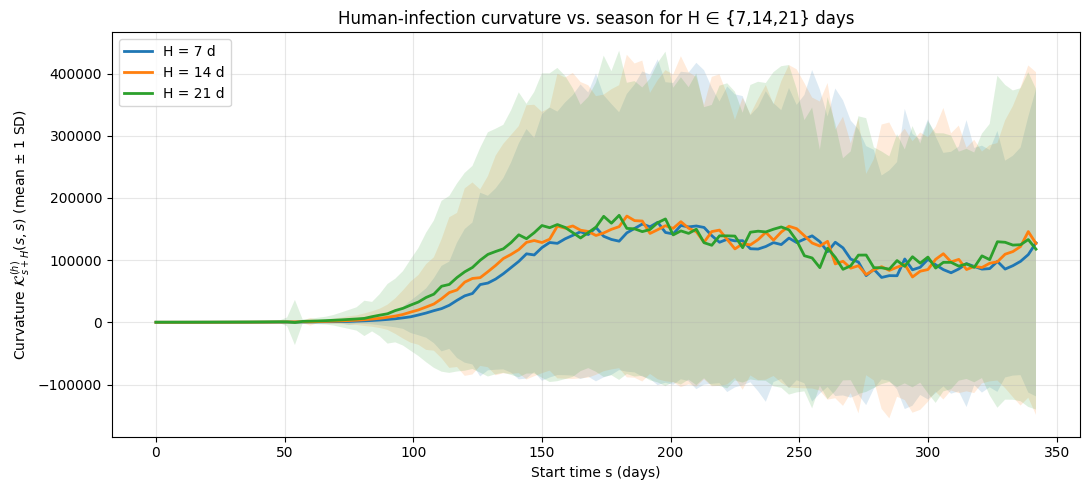

In [ ]:
# Re-run the multi-horizon plot (H = 7, 14, 21 days).

import numpy as np
import matplotlib.pyplot as plt

T_days = 365
h = 1.0
N = int(T_days / h)
tgrid = np.arange(N+1) * h

a_bar = 0.25
eps_season = 0.3
yr = 365.0

b_h, b_v = 0.2, 0.3
gamma = 1/14.0
nu = 1/10.0
mu_v = 1/10.0

sigma_a = 0.15
sigma_h = 0.10
sigma_v = 0.20

I0 = 0.05
Ev0 = 0.05
Iv0 = 0.05
Z0 = 1.0

M = 600
rng = np.random.default_rng(31)

H_list = [7, 14, 21]
H_steps_list = [int(H / h) for H in H_list]

s_indices = np.arange(0, N - max(H_steps_list), 3)
S = len(s_indices)

K_store = {H: np.full((M, S), np.nan, dtype=float) for H in H_list}

def seasonal_a(t, Z):
    return a_bar * (1.0 + eps_season * np.cos(2.0 * np.pi * t / yr)) * Z

clip_thresh = 30.0

for m in range(M):
    dWa = rng.normal(0.0, np.sqrt(h), size=N)
    dWh = rng.normal(0.0, np.sqrt(h), size=N)
    dWv = rng.normal(0.0, np.sqrt(h), size=N)

    I = np.empty(N+1); I[0] = I0
    Ev = np.empty(N+1); Ev[0] = Ev0
    Iv = np.empty(N+1); Iv[0] = Iv0
    Z = np.empty(N+1); Z[0] = Z0

    for n in range(N):
        t = tgrid[n]
        a_t = seasonal_a(t, Z[n])

        mu_I = a_t * b_h * Iv[n] * (1.0 - I[n]) - gamma * I[n]
        mu_Ev = a_t * b_v * I[n] * (1.0 - Ev[n] - Iv[n]) - nu * Ev[n]
        mu_Iv = nu * Ev[n] - mu_v * Iv[n]

        sig_I = sigma_h * I[n] * (1.0 - I[n])
        sig_Iv = sigma_v * Iv[n] * (1.0 - Iv[n])

        I[n+1]  = I[n]  + mu_I * h  + sig_I  * dWh[n]
        Ev[n+1] = Ev[n] + mu_Ev * h
        Iv[n+1] = Iv[n] + mu_Iv * h + sig_Iv * dWv[n]

        I[n+1]  = np.clip(I[n+1], 0.0, 1.0)
        Ev[n+1] = np.clip(Ev[n+1], 0.0, 1.0)
        Iv[n+1] = np.clip(Iv[n+1], 0.0, 1.0)

        Z[n+1] = Z[n] + sigma_a * Z[n] * dWa[n]
        if Z[n+1] <= 0:
            Z[n+1] = 1e-6

    for j, k in enumerate(s_indices):
        denom = sigma_h * I[k] * (1.0 - I[k])
        if denom <= 1e-8:
            continue

        for H, H_steps in zip(H_list, H_steps_list):
            t_end = k + H_steps
            if t_end > N:
                continue

            J = 0.0
            J_partial = 0.0
            DsJ_drift_sum = 0.0
            DsJ_mart_sum = 0.0
            DsJ_initial = sigma_h * (1.0 - 2.0 * I[k])

            skip = False
            for n in range(k, t_end):
                t = tgrid[n]
                a_t = seasonal_a(t, Z[n])
                mu_I_x = - a_t * b_h * Iv[n] - gamma
                sigma_I_x = sigma_h * (1.0 - 2.0 * I[n])
                lam = mu_I_x - 0.5 * (sigma_I_x**2)

                J_step = lam * h + sigma_I_x * dWh[n]
                J += J_step

                if abs(J_partial) < clip_thresh:
                    DsI_n = sigma_h * I[k] * (1.0 - I[k]) * np.exp(J_partial)
                else:
                    skip = True
                    break

                a_coeff = 2.0 * (sigma_h**2) * (1.0 - 2.0 * I[n])
                b_coeff = -2.0 * sigma_h

                DsJ_drift_sum += a_coeff * DsI_n * h
                DsJ_mart_sum  += b_coeff * DsI_n * dWh[n]

                J_partial += J_step

            if skip or abs(J) > clip_thresh:
                continue

            DsJ = DsJ_initial + DsJ_drift_sum + DsJ_mart_sum
            K = (sigma_h * (1.0 - 2.0 * I[k]) + DsJ) / denom * np.exp(-J)

            if np.isfinite(K) and abs(K) < 1e6:
                K_store[H][m, j] = K

# Plot means with std bands
s_times = tgrid[s_indices]
plt.figure(figsize=(11, 5.0))

for H in H_list:
    meanK = np.nanmean(K_store[H], axis=0)
    stdK  = np.nanstd(K_store[H], axis=0)
    plt.plot(s_times, meanK, lw=2.0, label=f"H = {H} d")
    plt.fill_between(s_times, meanK - stdK, meanK + stdK, alpha=0.15)

plt.xlabel("Start time s (days)")
plt.ylabel(r"Curvature $\mathcal{K}^{(h)}_{s+H}(s,s)$ (mean ± 1 SD)")
plt.title("Human-infection curvature vs. season for H ∈ {7,14,21} days")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


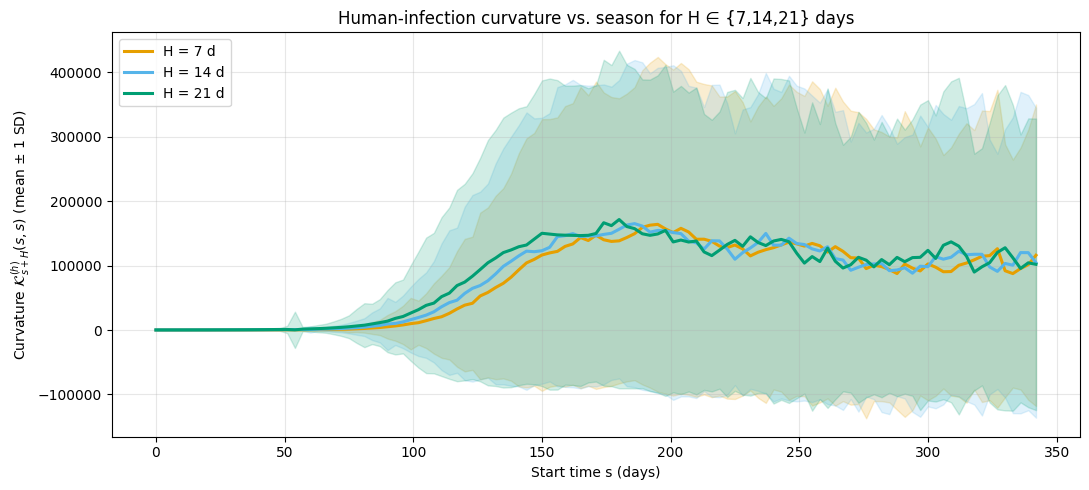

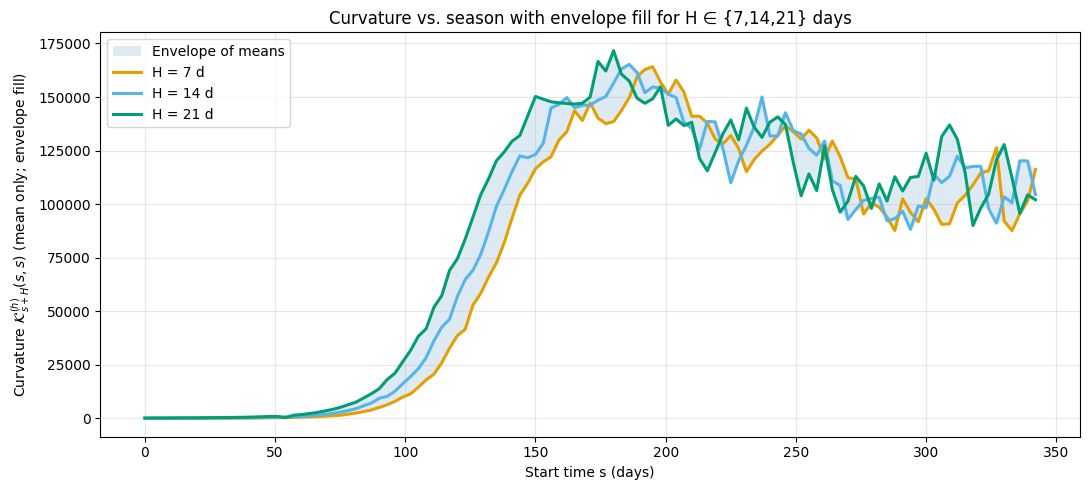

('/curvature_multiH_withSD.pdf', '/curvature_multiH_fillOnly.pdf')

In [ ]:
# Generate two publication-style figures and export as PDF:
# (1) Multi-horizon means with ±1 SD bands
# (2) Multi-horizon means with only a fill-between region (no SD)
#
# Files will be saved to /mnt/data and links provided.

import numpy as np
import matplotlib.pyplot as plt

# ------------------------
# Parameters
# ------------------------
T_days = 365
h = 1.0
N = int(T_days / h)
tgrid = np.arange(N+1) * h

# Seasonal/biological params
a_bar = 0.25
eps_season = 0.3
yr = 365.0

b_h, b_v = 0.2, 0.3
gamma = 1/14.0
nu = 1/10.0
mu_v = 1/10.0

# Noise intensities
sigma_a = 0.15
sigma_h = 0.10
sigma_v = 0.20

# Initial conditions
I0 = 0.05
Ev0 = 0.05
Iv0 = 0.05
Z0 = 1.0

# Monte Carlo
M = 1000
rng = np.random.default_rng(31)

# Horizons (days)
H_list = [7, 14, 21]
H_steps_list = [int(H / h) for H in H_list]

# Evaluate s every 3 days, valid for the largest horizon
s_indices = np.arange(0, N - max(H_steps_list), 3)
S = len(s_indices)

# Storage: for each H, keep all path values K over s
K_store = {H: np.full((M, S), np.nan, dtype=float) for H in H_list}

def seasonal_a(t, Z):
    return a_bar * (1.0 + eps_season * np.cos(2.0 * np.pi * t / yr)) * Z

clip_thresh = 30.0

# ------------------------
# Monte Carlo loop
# ------------------------
for m in range(M):
    dWa = rng.normal(0.0, np.sqrt(h), size=N)
    dWh = rng.normal(0.0, np.sqrt(h), size=N)
    dWv = rng.normal(0.0, np.sqrt(h), size=N)

    I = np.empty(N+1); I[0] = I0
    Ev = np.empty(N+1); Ev[0] = Ev0
    Iv = np.empty(N+1); Iv[0] = Iv0
    Z = np.empty(N+1); Z[0] = Z0

    # Forward simulate one year
    for n in range(N):
        t = tgrid[n]
        a_t = seasonal_a(t, Z[n])

        mu_I = a_t * b_h * Iv[n] * (1.0 - I[n]) - gamma * I[n]
        mu_Ev = a_t * b_v * I[n] * (1.0 - Ev[n] - Iv[n]) - nu * Ev[n]
        mu_Iv = nu * Ev[n] - mu_v * Iv[n]

        sig_I = sigma_h * I[n] * (1.0 - I[n])
        sig_Iv = sigma_v * Iv[n] * (1.0 - Iv[n])

        I[n+1]  = I[n]  + mu_I * h  + sig_I  * dWh[n]
        Ev[n+1] = Ev[n] + mu_Ev * h
        Iv[n+1] = Iv[n] + mu_Iv * h + sig_Iv * dWv[n]

        I[n+1]  = np.clip(I[n+1], 0.0, 1.0)
        Ev[n+1] = np.clip(Ev[n+1], 0.0, 1.0)
        Iv[n+1] = np.clip(Iv[n+1], 0.0, 1.0)

        Z[n+1] = Z[n] + sigma_a * Z[n] * dWa[n]
        if Z[n+1] <= 0:
            Z[n+1] = 1e-6

    # For each s and each horizon, compute K
    for j, k in enumerate(s_indices):
        denom = sigma_h * I[k] * (1.0 - I[k])
        if denom <= 1e-8:
            continue

        for H, H_steps in zip(H_list, H_steps_list):
            t_end = k + H_steps
            if t_end > N:
                continue

            J = 0.0
            J_partial = 0.0
            DsJ_drift_sum = 0.0
            DsJ_mart_sum = 0.0
            DsJ_initial = sigma_h * (1.0 - 2.0 * I[k])

            skip = False
            for n in range(k, t_end):
                t = tgrid[n]
                a_t = seasonal_a(t, Z[n])
                mu_I_x = - a_t * b_h * Iv[n] - gamma
                sigma_I_x = sigma_h * (1.0 - 2.0 * I[n])
                lam = mu_I_x - 0.5 * (sigma_I_x**2)

                J_step = lam * h + sigma_I_x * dWh[n]
                J += J_step

                if abs(J_partial) < clip_thresh:
                    DsI_n = sigma_h * I[k] * (1.0 - I[k]) * np.exp(J_partial)
                else:
                    skip = True
                    break

                a_coeff = 2.0 * (sigma_h**2) * (1.0 - 2.0 * I[n])
                b_coeff = -2.0 * sigma_h

                DsJ_drift_sum += a_coeff * DsI_n * h
                DsJ_mart_sum  += b_coeff * DsI_n * dWh[n]

                J_partial += J_step

            if skip or abs(J) > clip_thresh:
                continue

            DsJ = DsJ_initial + DsJ_drift_sum + DsJ_mart_sum
            K = (sigma_h * (1.0 - 2.0 * I[k]) + DsJ) / denom * np.exp(-J)

            if np.isfinite(K) and abs(K) < 1e6:
                K_store[H][m, j] = K

# ------------------------
# Aggregate stats
# ------------------------
s_times = tgrid[s_indices]
mean_by_H = {}
std_by_H = {}

for H in H_list:
    mean_by_H[H] = np.nanmean(K_store[H], axis=0)
    std_by_H[H]  = np.nanstd(K_store[H], axis=0)

# ------------------------
# (1) Plot with ±1 SD bands and save as PDF
# ------------------------
plt.figure(figsize=(11, 5.0))
palette = {7: '#E69F00', 14: '#56B4E9', 21: '#009E73'}  # colorblind-friendly
for H in H_list:
    meanK = mean_by_H[H]
    stdK  = std_by_H[H]
    plt.plot(s_times, meanK, lw=2.2, label=f"H = {H} d", color=palette[H])
    plt.fill_between(s_times, meanK - stdK, meanK + stdK, alpha=0.18, color=palette[H])

plt.xlabel("Start time s (days)")
plt.ylabel(r"Curvature $\mathcal{K}^{(h)}_{s+H}(s,s)$ (mean ± 1 SD)")
plt.title("Human-infection curvature vs. season for H ∈ {7,14,21} days")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
pdf_path_sd = "/curvature_multiH_withSD.pdf"
plt.savefig(pdf_path_sd)
plt.show()

# ------------------------
# (2) Plot with only fill-between among the three mean curves (no SD) and save as PDF
#     We fill the envelope between the min and max of the three mean curves at each time.
# ------------------------
means_stack = np.vstack([mean_by_H[H] for H in H_list])  # shape (3, S)
lower_env = np.nanmin(means_stack, axis=0)
upper_env = np.nanmax(means_stack, axis=0)

plt.figure(figsize=(11, 5.0))
# Envelope fill
plt.fill_between(s_times, lower_env, upper_env, alpha=0.15, label="Envelope of means")

# Plot means on top
for H in H_list:
    plt.plot(s_times, mean_by_H[H], lw=2.2, label=f"H = {H} d", color=palette[H])

plt.xlabel("Start time s (days)")
plt.ylabel(r"Curvature $\mathcal{K}^{(h)}_{s+H}(s,s)$ (mean only; envelope fill)")
plt.title("Curvature vs. season with envelope fill for H ∈ {7,14,21} days")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
pdf_path_env = "/curvature_multiH_fillOnly.pdf"
plt.savefig(pdf_path_env)
plt.show()

pdf_path_sd, pdf_path_env


In [ ]:
# Add H = 28 days to the multi-horizon plot and export PDFs.
# We reuse the same model/simulation structure as before.

import numpy as np
import matplotlib.pyplot as plt

# ------------------------
# Parameters
# ------------------------
T_days = 365
h = 0.1
N = int(T_days / h)
tgrid = np.arange(N+1) * h

# Seasonal/biological params
a_bar = 0.25
eps_season = 0.3
yr = 365.0

b_h, b_v = 0.2, 0.3
gamma = 1/14.0
nu = 1/10.0
mu_v = 1/10.0

# Noise intensities
sigma_a = 0.15
sigma_h = 0.10
sigma_v = 0.20

# Initial conditions
I0 = 0.05
Ev0 = 0.05
Iv0 = 0.05
Z0 = 1.0

# Monte Carlo
M = 1000
rng = np.random.default_rng(31)

# Horizons (days) now include 28
H_list = [7, 14, 21, 28]
H_steps_list = [int(H / h) for H in H_list]

# Evaluate s every 3 days, valid for the largest horizon
s_indices = np.arange(0, N - max(H_steps_list), 3)
S = len(s_indices)

# Storage
K_store = {H: np.full((M, S), np.nan, dtype=float) for H in H_list}

def seasonal_a(t, Z):
    return a_bar * (1.0 + eps_season * np.cos(2.0 * np.pi * t / yr)) * Z

clip_thresh = 30.0

# ------------------------
# Monte Carlo loop
# ------------------------
for m in range(M):
    dWa = rng.normal(0.0, np.sqrt(h), size=N)
    dWh = rng.normal(0.0, np.sqrt(h), size=N)
    dWv = rng.normal(0.0, np.sqrt(h), size=N)

    I = np.empty(N+1); I[0] = I0
    Ev = np.empty(N+1); Ev[0] = Ev0
    Iv = np.empty(N+1); Iv[0] = Iv0
    Z = np.empty(N+1); Z[0] = Z0

    # Forward simulate one year
    for n in range(N):
        t = tgrid[n]
        a_t = seasonal_a(t, Z[n])

        mu_I = a_t * b_h * Iv[n] * (1.0 - I[n]) - gamma * I[n]
        mu_Ev = a_t * b_v * I[n] * (1.0 - Ev[n] - Iv[n]) - nu * Ev[n]
        mu_Iv = nu * Ev[n] - mu_v * Iv[n]

        sig_I = sigma_h * I[n] * (1.0 - I[n])
        sig_Iv = sigma_v * Iv[n] * (1.0 - Iv[n])

        I[n+1]  = I[n]  + mu_I * h  + sig_I  * dWh[n]
        Ev[n+1] = Ev[n] + mu_Ev * h
        Iv[n+1] = Iv[n] + mu_Iv * h + sig_Iv * dWv[n]

        I[n+1]  = np.clip(I[n+1], 0.0, 1.0)
        Ev[n+1] = np.clip(Ev[n+1], 0.0, 1.0)
        Iv[n+1] = np.clip(Iv[n+1], 0.0, 1.0)

        Z[n+1] = Z[n] + sigma_a * Z[n] * dWa[n]
        if Z[n+1] <= 0:
            Z[n+1] = 1e-6

    # For each s and each horizon, compute K
    for j, k in enumerate(s_indices):
        denom = sigma_h * I[k] * (1.0 - I[k])
        if denom <= 1e-8:
            continue

        for H, H_steps in zip(H_list, H_steps_list):
            t_end = k + H_steps
            if t_end > N:
                continue

            J = 0.0
            J_partial = 0.0
            DsJ_drift_sum = 0.0
            DsJ_mart_sum = 0.0
            DsJ_initial = sigma_h * (1.0 - 2.0 * I[k])

            skip = False
            for n in range(k, t_end):
                t = tgrid[n]
                a_t = seasonal_a(t, Z[n])
                mu_I_x = - a_t * b_h * Iv[n] - gamma
                sigma_I_x = sigma_h * (1.0 - 2.0 * I[n])
                lam = mu_I_x - 0.5 * (sigma_I_x**2)

                J_step = lam * h + sigma_I_x * dWh[n]
                J += J_step

                if abs(J_partial) < clip_thresh:
                    DsI_n = sigma_h * I[k] * (1.0 - I[k]) * np.exp(J_partial)
                else:
                    skip = True
                    break

                a_coeff = 2.0 * (sigma_h**2) * (1.0 - 2.0 * I[n])
                b_coeff = -2.0 * sigma_h

                DsJ_drift_sum += a_coeff * DsI_n * h
                DsJ_mart_sum  += b_coeff * DsI_n * dWh[n]

                J_partial += J_step

            if skip or abs(J) > clip_thresh:
                continue

            DsJ = DsJ_initial + DsJ_drift_sum + DsJ_mart_sum
            K = (sigma_h * (1.0 - 2.0 * I[k]) + DsJ) / denom * np.exp(-J)

            if np.isfinite(K) and abs(K) < 1e6:
                K_store[H][m, j] = K

# ------------------------
# Aggregate stats and plotting
# ------------------------
s_times = tgrid[s_indices]
palette = {7: '#E69F00', 14: '#56B4E9', 21: '#009E73', 28: '#CC79A7'}  # colorblind-friendly

# (A) Means + ±1 SD
plt.figure(figsize=(11, 5.0))
for H in H_list:
    meanK = np.nanmean(K_store[H], axis=0)
    stdK  = np.nanstd(K_store[H], axis=0)
    plt.plot(s_times, meanK, lw=2.2, label=f"H = {H} d", color=palette[H])
    plt.fill_between(s_times, meanK - stdK, meanK + stdK, alpha=0.18, color=palette[H])

plt.xlabel("Start time s (days)")
plt.ylabel(r"Curvature $\mathcal{K}^{(h)}_{s+H}(s,s)$ (mean ± 1 SD)")
plt.title("Human-infection curvature vs. season for H ∈ {7,14,21,28} days")
plt.grid(True, alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
pdf_path_sd = "/curvature_multiH_withSD_7_14_21_28.pdf"
plt.savefig(pdf_path_sd)
plt.show()

# (B) Envelope fill (no SD)
means_stack = np.vstack([np.nanmean(K_store[H], axis=0) for H in H_list])
lower_env = np.nanmin(means_stack, axis=0)
upper_env = np.nanmax(means_stack, axis=0)

plt.figure(figsize=(11, 5.0))
plt.fill_between(s_times, lower_env, upper_env, alpha=0.15, label="Envelope of means", color="#999999")
for H in H_list:
    plt.plot(s_times, np.nanmean(K_store[H], axis=0), lw=2.2, label=f"H = {H} d", color=palette[H])

plt.xlabel("Start time s (days)")
plt.ylabel(r"Curvature $\mathcal{K}^{(h)}_{s+H}(s,s)$ (mean only; envelope fill)")
plt.title("Curvature vs. season with envelope fill for H ∈ {7,14,21,28} days")
plt.grid(True, alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
pdf_path_env = "/curvature_multiH_fillOnly_7_14_21_28.pdf"
plt.savefig(pdf_path_env)
plt.show()

pdf_path_sd, pdf_path_env


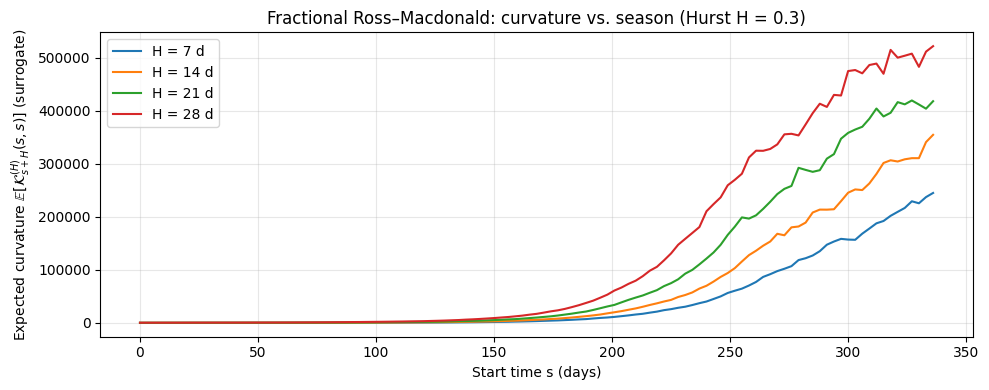

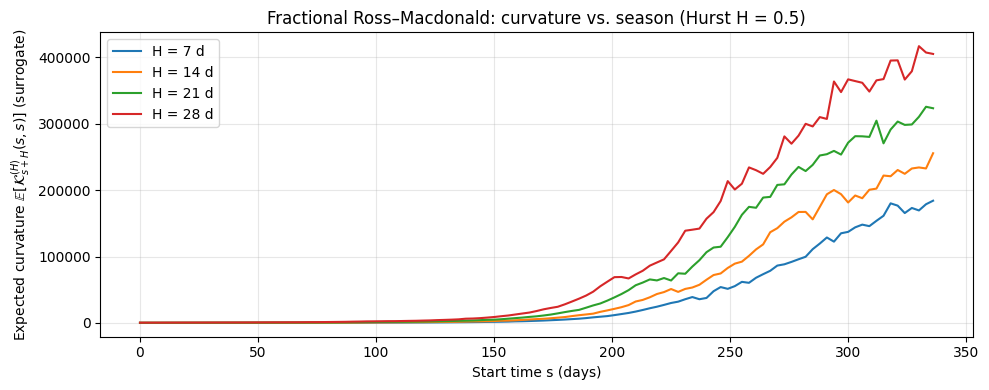

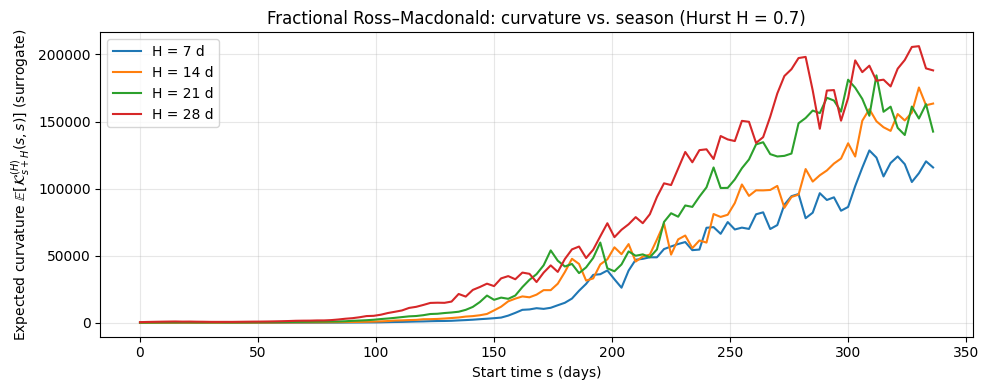

(['/frac_RM_curvature_H0p3.png',
  '/frac_RM_curvature_H0p5.png',
  '/frac_RM_curvature_H0p7.png'],
 ['/frac_RM_curvature_H0p3.pdf',
  '/frac_RM_curvature_H0p5.pdf',
  '/frac_RM_curvature_H0p7.pdf'])

In [ ]:
# Retry: Fractional Ross–Macdonald curvature demo (Monte Carlo)
# H in {0.3, 0.5, 0.7}, horizons {7, 14, 21, 28}.

import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Utilities: fGn via Hosking
# -----------------------------
def fgn_hosking(N, H, rng):
    """
    Generate fractional Gaussian noise (fGn) of length N with Hurst parameter H using Hosking's method.
    Returns increments with Var=1 per step (i.e., fBm increment over Δ=1).
    """
    def autocov(k):
        k = int(abs(k))
        # Handle k=0 carefully to avoid 0**(negative) when H<0.5 and k-1 = -1
        if k == 0:
            return 1.0  # Var of fGn increment over Δ=1 equals 1
        return 0.5 * ((k+1)**(2*H) - 2*(k**(2*H)) + (k-1)**(2*H))

    X = np.empty(N, dtype=float)
    phi = np.empty(N, dtype=float)
    var = np.empty(N, dtype=float)

    r = np.array([autocov(k) for k in range(N)], dtype=float)
    # Numerical safeguard: ensure r[0]>0
    r[0] = max(r[0], 1e-12)

    X[0] = rng.normal(0.0, np.sqrt(r[0]))
    var[0] = r[0]

    for n in range(1, N):
        phi_temp = np.zeros(n, dtype=float)
        if n == 1:
            phi_temp[0] = r[1] / r[0] if r[0] != 0 else 0.0
            var[n] = r[0] * max(1 - phi_temp[0]**2, 1e-12)
        else:
            num = r[n] - np.dot(phi[:n-1], r[1:n][::-1])
            den = var[n-1]
            kappa = num / den if den != 0 else 0.0
            phi_temp[:n-1] = phi[:n-1] - kappa * phi[:n-1][::-1]
            phi_temp[n-1] = kappa
            var[n] = var[n-1] * max(1 - kappa**2, 1e-12)

        phi[:n] = phi_temp
        mean = np.dot(phi[:n], X[n-1::-1]) if n > 0 else 0.0
        eps = rng.normal(0.0, np.sqrt(max(var[n], 1e-14)))
        X[n] = mean + eps

    return X

# -----------------------------
# Model parameters (daily step)
# -----------------------------
T_days = 365
h = 1.0  # day
N = int(T_days / h)
tgrid = np.arange(N+1) * h

# Seasonality
a_bar = 0.25
eps_season = 0.3
yr = 365.0
def a_season(t):
    return a_bar * (1.0 + eps_season * np.cos(2.0 * np.pi * t / yr))

# RM parameters
b_h, b_v = 0.2, 0.3
gamma = 1/14.0
nu = 1/10.0
mu_v = 1/10.0

# Noise intensities
sigma_h = 0.10   # human infection noise
sigma_v = 0.20   # vector infectious noise

# Initial conditions
I0 = 0.05
Ev0 = 0.05
Iv0 = 0.05

# Monte Carlo
M = 120  # modest to keep runtime reasonable
rng = np.random.default_rng(2025)

# Horizons
H_list_days = [7, 14, 21, 28]
H_list_steps = [int(Hd / h) for Hd in H_list_days]

# Hurst parameters to explore
H_values = [0.3, 0.5, 0.7]

# s grid (start indices)
max_H_steps = max(H_list_steps)
s_indices = np.arange(0, N - max_H_steps, 3)  # every 3 days

# Storage
EK_by_H = {H: {Hd: np.full_like(s_indices, np.nan, dtype=float) for Hd in H_list_days} for H in H_values}

# -----------------------------
# Simulation loop
# -----------------------------
for H in H_values:
    sums = {Hd: np.zeros_like(s_indices, dtype=float) for Hd in H_list_days}
    counts = {Hd: np.zeros_like(s_indices, dtype=int) for Hd in H_list_days}

    for m in range(M):
        # Human fGn increments (daily) for fractional noise
        dB_h = fgn_hosking(N, H, rng)
        # Vector noise (standard Brownian increments)
        dWv = rng.normal(0.0, np.sqrt(h), size=N)

        # Paths
        I = np.empty(N+1); I[0] = I0
        Ev = np.empty(N+1); Ev[0] = Ev0
        Iv = np.empty(N+1); Iv[0] = Iv0

        for n in range(N):
            t = tgrid[n]
            a_t = a_season(t)
            # Drift
            mu_I  = a_t * b_h * Iv[n] * (1.0 - I[n]) - gamma * I[n]
            mu_Ev = a_t * b_v * I[n] * (1.0 - Ev[n] - Iv[n]) - nu * Ev[n]
            mu_Iv = nu * Ev[n] - mu_v * Iv[n]
            # Diffusions
            sig_I  = sigma_h * I[n] * (1.0 - I[n])
            sig_Iv = sigma_v * Iv[n] * (1.0 - Iv[n])

            # Updates
            I[n+1]  = I[n]  + mu_I * h  + sig_I  * dB_h[n]
            Ev[n+1] = Ev[n] + mu_Ev * h
            Iv[n+1] = Iv[n] + mu_Iv * h + sig_Iv * dWv[n]

            # Clips
            I[n+1]  = np.clip(I[n+1],  0.0, 1.0)
            Ev[n+1] = np.clip(Ev[n+1], 0.0, 1.0)
            Iv[n+1] = np.clip(Iv[n+1], 0.0, 1.0)

        # Curvature surrogate at s with horizon Hd
        clip_thresh = 30.0
        for idx, k in enumerate(s_indices):
            denom = sigma_h * I[k] * (1.0 - I[k])
            if denom <= 1e-10:
                continue
            for Hd, Hsteps in zip(H_list_days, H_list_steps):
                t_end = k + Hsteps
                if t_end > N:
                    continue

                J = 0.0
                J_partial = 0.0
                DsJ_drift_sum = 0.0
                DsJ_mart_sum = 0.0
                DsJ_initial = sigma_h * (1.0 - 2.0 * I[k])

                skip = False
                for n in range(k, t_end):
                    t = tgrid[n]
                    a_t = a_season(t)
                    mu_I_x = - a_t * b_h * Iv[n] - gamma
                    sigma_I_x = sigma_h * (1.0 - 2.0 * I[n])
                    lam = mu_I_x - 0.5 * (sigma_I_x**2)  # heuristic fractional analogue
                    dBh = dB_h[n]

                    J_step = lam * h + sigma_I_x * dBh
                    J += J_step

                    if abs(J_partial) < clip_thresh:
                        DsI_n = denom * np.exp(J_partial)
                    else:
                        skip = True
                        break

                    a_coeff = 2.0 * (sigma_h**2) * (1.0 - 2.0 * I[n])
                    b_coeff = -2.0 * sigma_h

                    DsJ_drift_sum += a_coeff * DsI_n * h
                    DsJ_mart_sum  += b_coeff * DsI_n * dBh

                    J_partial += J_step

                if skip or abs(J) > clip_thresh:
                    continue

                DsJ = DsJ_initial + DsJ_drift_sum + DsJ_mart_sum
                K_est = (sigma_h * (1.0 - 2.0 * I[k]) + DsJ) / denom * np.exp(-J)

                if np.isfinite(K_est) and abs(K_est) < 1e6:
                    sums[Hd][idx] += K_est
                    counts[Hd][idx] += 1

    for Hd in H_list_days:
        EK = np.where(counts[Hd] > 0, sums[Hd] / counts[Hd], np.nan)
        EK_by_H[H][Hd] = EK

# -----------------------------
# Plotting: one figure per H value with four horizons; save PNG and PDF
# -----------------------------
fig_paths = []
pdf_paths = []
for H in H_values:
    plt.figure(figsize=(10, 4.0))
    for Hd in H_list_days:
        plt.plot(tgrid[s_indices], EK_by_H[H][Hd], lw=1.5, label=f"H = {Hd} d")
    plt.xlabel("Start time s (days)")
    plt.ylabel(r"Expected curvature $\mathbb{E}[\mathcal{K}_{s+H}^{(H)}(s,s)]$ (surrogate)")
    plt.title(f"Fractional Ross–Macdonald: curvature vs. season (Hurst H = {H})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    png_path = f"/frac_RM_curvature_H{str(H).replace('.','p')}.png"
    pdf_path = f"/frac_RM_curvature_H{str(H).replace('.','p')}.pdf"
    plt.savefig(png_path, dpi=160, bbox_inches="tight")
    plt.savefig(pdf_path, dpi=300, bbox_inches="tight")
    fig_paths.append(png_path)
    pdf_paths.append(pdf_path)
    plt.show()

(fig_paths, pdf_paths)


/tmp/ipython-input-3748333578.py:163: RuntimeWarning: divide by zero encountered in scalar divide
  K = (DsJ / (sigma_cir * np.sqrt(Xs) * np.exp(J))) * (1.0 + 1.0 / (2.0 * Xs))
/tmp/ipython-input-3748333578.py:173: RuntimeWarning: Mean of empty slice
  stats['CIR'][H]['mean'][:S_eff] = np.nanmean(K_arr, axis=0)
/usr/local/lib/python3.12/dist-packages/numpy/lib/_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


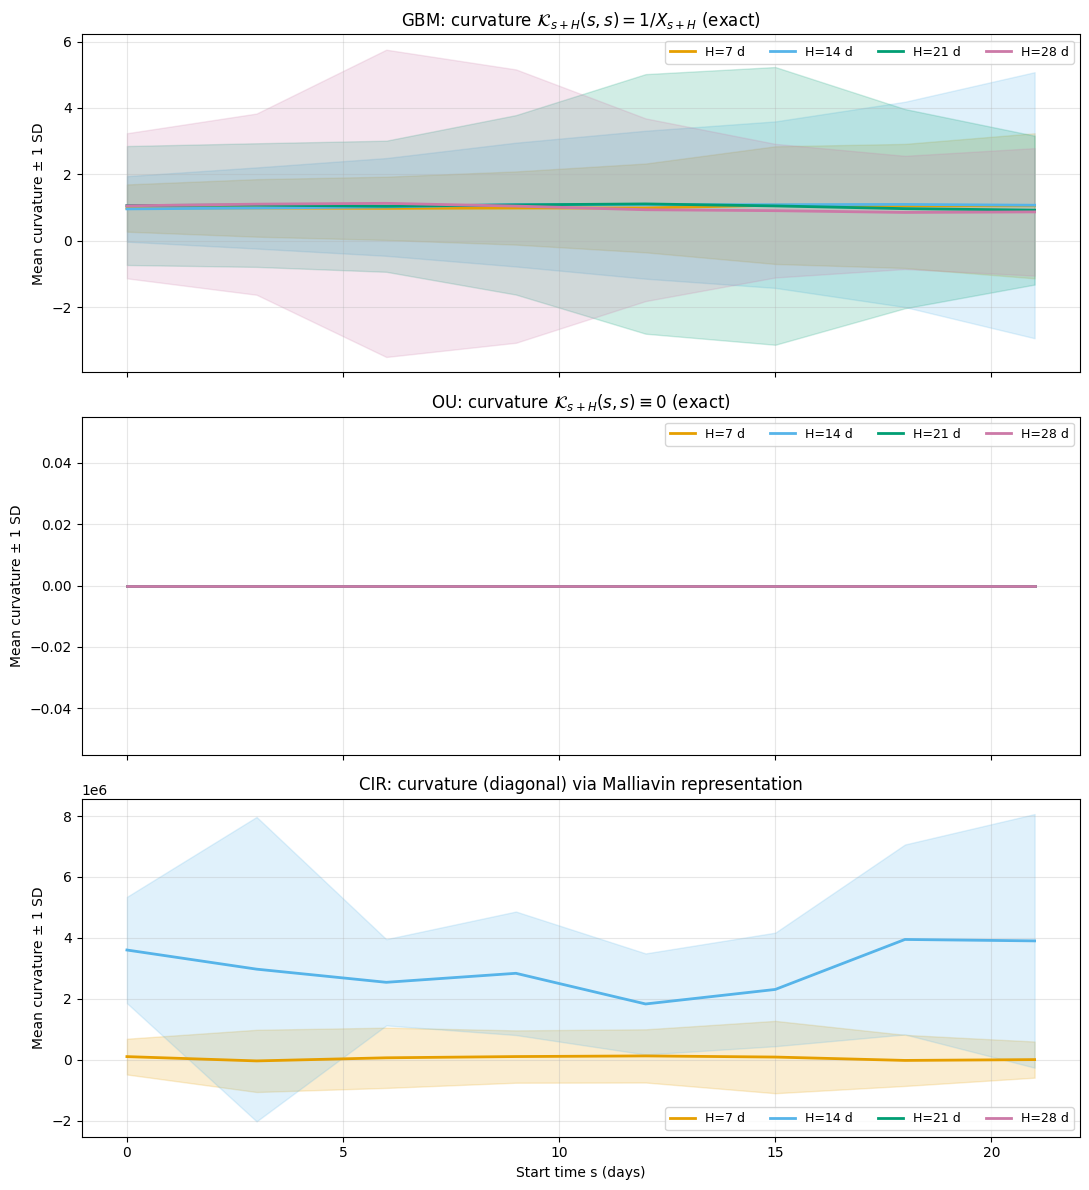

'/curvature_GBM_OU_CIR_multiH.pdf'

In [ ]:
# # Curvature comparisons for GBM, OU, and CIR across horizons H ∈ {7,14,21,28}.
# # We simulate paths and compute diagonal Malliavin curvature K_{s+H}(s,s).
# # Outputs: a multi-panel PDF with mean ± 1 SD for each model.

# import numpy as np
# import matplotlib.pyplot as plt

# # ------------------------
# # Global simulation settings
# # ------------------------
# T = 50.0         # total time (days/units)
# h = 1.0           # step (days)
# N = int(T / h)
# tgrid = np.arange(N+1) * h

# M = 400           # Monte Carlo paths (balanced for runtime)

# rng = np.random.default_rng(2025)

# # Horizons (days)
# H_list = [7, 14, 21, 28]
# H_steps_list = [int(H / h) for H in H_list]

# # s grid (every 3 time units, valid for the largest H)
# s_indices = np.arange(0, N - max(H_steps_list), 3)
# S = len(s_indices)

# # Color palette (colorblind friendly)
# palette = {7: '#E69F00', 14: '#56B4E9', 21: '#009E73', 28: '#CC79A7'}

# # ------------------------
# # GBM parameters and simulation
# # ------------------------
# mu_gbm = 0.06
# sigma_gbm = 0.25
# X0_gbm = 1.0

# # OU parameters
# kappa_ou = 0.5
# sigma_ou = 0.3
# X0_ou = 0.0

# # CIR parameters (Feller condition)
# kappa_cir = 1.2
# theta_cir = 1.0
# sigma_cir = 0.9
# X0_cir = 0.8  # positive

# # ------------------------
# # Containers for mean/std across H for each model
# # ------------------------
# stats = {
#     'GBM': {H: {'mean': np.full(S, np.nan), 'std': np.full(S, np.nan)} for H in H_list},
#     'OU' : {H: {'mean': np.zeros(S), 'std': np.zeros(S)} for H in H_list},  # curvature zero
#     'CIR': {H: {'mean': np.full(S, np.nan), 'std': np.full(S, np.nan)} for H in H_list},
# }

# # ------------------------
# # Helper: simulate GBM path and return X
# # ------------------------
# def simulate_gbm():
#     dW = rng.normal(0.0, np.sqrt(h), size=N)
#     X = np.empty(N+1); X[0] = X0_gbm
#     for n in range(N):
#         # Exact discretization for GBM
#         X[n+1] = X[n] * np.exp((mu_gbm - 0.5 * sigma_gbm**2) * h + sigma_gbm * dW[n])
#     return X

# # ------------------------
# # Helper: simulate OU path and return X
# # ------------------------
# def simulate_ou():
#     dW = rng.normal(0.0, np.sqrt(h), size=N)
#     X = np.empty(N+1); X[0] = X0_ou
#     for n in range(N):
#         # Euler-Maruyama
#         X[n+1] = X[n] - kappa_ou * X[n] * h + sigma_ou * dW[n]
#     return X

# # ------------------------
# # Helper: simulate CIR path and return (X, dW) since we reuse dW for Malliavin terms
# # ------------------------
# def simulate_cir():
#     dW = rng.normal(0.0, np.sqrt(h), size=N)
#     X = np.empty(N+1); X[0] = X0_cir
#     for n in range(N):
#         # Euler-Maruyama with positivity clamp
#         X[n+1] = X[n] + kappa_cir * (theta_cir - X[n]) * h + sigma_cir * np.sqrt(max(X[n], 1e-10)) * dW[n]
#         if X[n+1] <= 0:
#             X[n+1] = 1e-8
#     return X, dW

# # ------------------------
# # Monte Carlo for each model
# # ------------------------

# # GBM: K_{s+H}(s,s) = 1 / X_{s+H}
# K_store_gbm = {H: [] for H in H_list}
# for m in range(M):
#     X = simulate_gbm()
#     for H, Hs in zip(H_list, H_steps_list):
#         K_vals = []
#         for j, k in enumerate(s_indices):
#             t_end = k + Hs
#             if t_end > N:
#                 break
#             K_vals.append(1.0 / X[t_end])
#         K_store_gbm[H].append(K_vals)

# for H in H_list:
#     K_arr = np.array(K_store_gbm[H])   # shape (M, S_eff)
#     S_eff = K_arr.shape[1]
#     stats['GBM'][H]['mean'][:S_eff] = np.nanmean(K_arr, axis=0)
#     stats['GBM'][H]['std'][:S_eff]  = np.nanstd(K_arr, axis=0)

# # OU: curvature zero everywhere (already filled with zeros)

# # CIR: use diagonal formula at γ = s
# # K = (D_s J_{s,t}) / (σ √X_s e^{J_{s,t}}) * (1 + 1/(2 X_s))
# # with
# # J_{s,t} = ∫ [ -κ - σ^2/(8 X_r) ] dr + ∫ [ σ/(2 √X_r) ] dW_r
# # D_s J_{s,t} = σ/(2 √X_s) + ∫ [(σ^2)/(8 X_r^2) D_s X_r] dr - ∫ [ (σ)/(4 X_r^{3/2}) D_s X_r ] dW_r
# # where D_s X_r solves dU_r = κ' U_r dr + (σ/(2√X_r)) U_r dW_r with κ' = μ_x = -κ
# # BUT for CIR μ_x = ∂/∂x [ κ(θ - x) ] = -κ  and σ_x = σ/(2√x).
# #
# # We integrate U forward from r=s with U_s = σ √X_s using the same Brownian increments.

# K_store_cir = {H: [] for H in H_list}

# for m in range(M):
#     X, dW = simulate_cir()
#     for H, Hs in zip(H_list, H_steps_list):
#         K_vals = []
#         for j, k in enumerate(s_indices):
#             t_end = k + Hs
#             if t_end > N:
#                 break
#             Xs = X[k]
#             if Xs <= 1e-10:
#                 K_vals.append(np.nan); continue
#             # initialize
#             J = 0.0
#             DsJ_drift = 0.0
#             DsJ_mart  = 0.0
#             # U_s
#             U = sigma_cir * np.sqrt(Xs)
#             dsJ_initial = sigma_cir / (2.0 * np.sqrt(Xs))
#             # step from k to t_end (indices n: k..t_end-1)
#             for n in range(k, t_end):
#                 Xr = max(X[n], 1e-10)
#                 # coefficients
#                 mu_x  = -kappa_cir
#                 sigma_x = sigma_cir / (2.0 * np.sqrt(Xr))
#                 lam = mu_x - 0.5 * (sigma_x**2)
#                 # accumulate J
#                 J += lam * h + sigma_x * dW[n]
#                 # evolve U (D_s X_r)
#                 U = U + mu_x * U * h + sigma_x * U * dW[n]
#                 # drift and martingale parts for D_s J
#                 DsJ_drift += (sigma_cir**2) / (8.0 * Xr**2) * U * h
#                 DsJ_mart  += - (sigma_cir) / (4.0 * Xr**1.5) * U * dW[n]
#             DsJ = dsJ_initial + DsJ_drift + DsJ_mart
#             K = (DsJ / (sigma_cir * np.sqrt(Xs) * np.exp(J))) * (1.0 + 1.0 / (2.0 * Xs))
#             if np.isfinite(K) and abs(K) < 1e7:
#                 K_vals.append(K)
#             else:
#                 K_vals.append(np.nan)
#         K_store_cir[H].append(K_vals)

# for H in H_list:
#     K_arr = np.array(K_store_cir[H])
#     S_eff = K_arr.shape[1]
#     stats['CIR'][H]['mean'][:S_eff] = np.nanmean(K_arr, axis=0)
#     stats['CIR'][H]['std'][:S_eff]  = np.nanstd(K_arr, axis=0)

# # ------------------------
# # Plot: three subplots for GBM, OU, CIR
# # ------------------------
# fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)

# models = ['GBM', 'OU', 'CIR']
# titles = {
#     'GBM': "GBM: curvature $\\mathcal{K}_{s+H}(s,s)=1/X_{s+H}$ (exact)",
#     'OU' : "OU: curvature $\\mathcal{K}_{s+H}(s,s)\\equiv 0$ (exact)",
#     'CIR': "CIR: curvature (diagonal) via Malliavin representation",
# }

# for ax, model in zip(axes, models):
#     for H in H_list:
#         mK = stats[model][H]['mean']
#         sK = stats[model][H]['std']
#         ax.plot(tgrid[s_indices], mK, lw=2.0, label=f"H={H} d", color=palette[H])
#         # ±1 SD band (skip for OU since it's zero)
#         if model != 'OU':
#             ax.fill_between(tgrid[s_indices], mK - sK, mK + sK, alpha=0.18, color=palette[H])
#     ax.set_ylabel("Mean curvature ± 1 SD")
#     ax.set_title(titles[model])
#     ax.grid(True, alpha=0.3)
#     ax.legend(ncol=4, fontsize=9)

# axes[-1].set_xlabel("Start time s (days)")

# plt.tight_layout()
# pdf_path = "/curvature_GBM_OU_CIR_multiH.pdf"
# plt.savefig(pdf_path)
# plt.show()

# pdf_path
